# 10 · ETF 20종 공통 고변동성 기반 급변 후보 구간 추출·비교·선정

**「17개 경제적 노출 그룹이 같은 날 동시에 자기 과거 대비 고변동성(A)을 보이는 정도로 정의한 급변 후보 구간 — 20·60거래일 × 최소 동시 참여 그룹 수 k 의 비교」**

- 연구 ID `t19_common_volatility_candidates_10`, 프로토콜 `10-lock-1`, 기준 커밋 `172cbb3` (W4 최종), 브랜치 `research/10_common_volatility_candidate_intervals`.
- 계약 `research/common_volatility_candidates_10/CANDIDATE_RESEARCH_CONTRACT.md` — 후보 구간을 계산하기 전에 커밋했다 (`1ab42bd`, 개정 1 `3b183f8`).
- **설계 지위: 사후 탐색 연구.** 09번(W4) 결과를 본 뒤 설계했다. 특히 C3(k=12)·C4(k=6)의 임계값은 09번의 관측 최대 참여값과 같다.
- 이 노트북의 산출물은 **정의별 실제 후보 구간 목록과 비교평가표**다. 통계적 구조변화의 입증, CNN 예측성능 검증, 최적 정의의 선언이 아니다.
- 09번 판정 `VALID_ZERO_INTERVALS` (17/17 ∧ A ∧ B) 는 그대로 유지한다.
- **v2 (리디자인, `10-lock-2`, 계약 `1dceefa`)**: lock-1 결과를 본 뒤 정의를 단단하게 하는 여섯 분석을 계산 전에 고정하고 PART D 로 통합했다 — 우연 기준선 k*, 자산군 균형, 이력 구간, 연속 강도 지수, 20→60일 시차, C1 구간 바텀업. lock-1 결과는 바이트 동일하게 재현된다.

## 먼저 보는 결론 (v2)

| 질문 | 답 | 근거 |
|---|---|---|
| 시장 공통 급변은 언제였나 | **C1 (20일, 같은 날 9/17 이상)**: 2022-10-11~12 · 2024-08-05~09-02 · 2025-04-10~05-07, 3구간 39일 | §8 |
| k=9 는 임의인가 | **아니다.** 그룹별 급변 시계열을 독립 원형 이동한 귀무에서 '5년 중 하루라도 9개 이상 동시' 확률 0.005, 8개 이상은 0.052 — 9 가 5% 기준을 처음 넘는 문턱 (k*_fw = 9) | §D1 |
| 60일 기준 C4 는 쓸 만한가 | **우연과 구별되지 않는다.** 관측 최대 6 < k*_fw 7, C4 의 우연 확률 0.164 | §D1 |
| 세 구간은 같은 종류인가 | **아니다.** 2022-10 은 채권·달러가 먼저 들어온 금리 충격 (강도 중 주식 16%), 2024-08 은 주식만 (비주식 0, 100%), 2025-04 는 주식·원자재·통화 다자산 (80%) | §D2·D4·D6 |
| 2024-08 의 20일 지속은 무엇인가 | **하루(08-05)가 20일 창에 머문 기간.** 빠진 7개 그룹 모두 그 하루가 창에서 빠진 날 빠졌다 | §D6 |
| 하루 미달로 쪼개지는 문제는 | 이력 규칙(10 진입·8 유지)이 C2 의 5조각을 2구간으로 잇는다 | §D3 |
| 20일과 60일은 왜 겹치지 않나 | 60일 공통성은 20일 공통성보다 **약 33거래일 늦다** (상관 0.38 → 0.57) | §D5 |

## 0. 실행 환경·동결 지문

In [1]:
# 새 커널 첫 셀: BLAS 스레드를 NumPy 로드 전에 1로 고정해 결과를 결정적으로 만든다.
import os  # 환경변수 설정
import sys  # 인터프리터·모듈 경로 확인
from pathlib import Path  # 저장소 상대 경로

for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):  # 네 BLAS 계열 변수
    os.environ[key] = "1"  # 다중 스레드 합산 순서에 따른 비트 차이를 막는다
assert "numpy" not in sys.modules, "새 커널에서 첫 셀부터 실행해야 합니다"  # 숨은 커널 상태 금지
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/t19_common_vol_candidates_v1.json").is_file())  # 저장소 루트 탐색
sys.path.insert(0, str(ROOT / "src"))  # 이 작업트리의 r2h 패키지를 우선 사용

import csv  # 보호 파일 SHA 목록
import hashlib  # 파일 지문
import importlib.metadata as metadata  # 설치 패키지 버전 조회
import json  # 설정·캡션
import platform  # Python 버전

import matplotlib  # 그림 백엔드
matplotlib.use("Agg")  # 화면 없이 파일로 저장
import numpy as np  # 수치 배열
import pandas as pd  # 결과표
from IPython.display import Image, display  # 표·그림 출력
import matplotlib.pyplot as plt  # 그림 기본 설정
from matplotlib import font_manager  # 한글 글꼴 등록

FONT_FILE = Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")  # 한글 도판용 나눔고딕
assert FONT_FILE.is_file(), "한글 도판 렌더링을 위한 나눔고딕 파일이 없습니다"  # 글꼴 없으면 중단
font_manager.fontManager.addfont(str(FONT_FILE))  # matplotlib 글꼴 목록에 등록
plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(FONT_FILE)).get_name()  # 한글 글꼴 사용
plt.rcParams["axes.unicode_minus"] = False  # 음수 기호 깨짐 방지

# 09(W4) 와 같은 고정 환경이어야 한다 (user-site 의 다른 numpy/pandas 를 잡으면 여기서 멈춘다).
EXPECTED_ENV = {"python": "3.12.3", "numpy": "2.5.4", "pandas": "3.0.6", "scipy": "1.18.1", "matplotlib": "3.11.2"}  # 고정 환경
ACTUAL_ENV = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scipy": metadata.version("scipy"), "matplotlib": metadata.version("matplotlib")}  # 실제 커널
assert ACTUAL_ENV == EXPECTED_ENV, f"실행 환경 불일치: {ACTUAL_ENV}"  # 버전 불일치는 재현 실패로 처리
assert ".local" not in np.__file__, np.__file__  # user-site 패키지 차단
pd.set_option("display.width", 220)  # 표 줄바꿈 완화
pd.set_option("display.max_columns", 40)  # 열 생략 완화
pd.set_option("display.max_colwidth", 140)  # 그룹 명단이 잘리지 않게

from r2h.common_vol import pipeline as P  # 10번 계산 (09 파이프라인은 호출하지 않는다)
from r2h.common_vol import lock2 as L  # 10-lock-2 확장 계산
from r2h.common_vol.figures import Figures10L2  # 10번 그림 (lock-1 G01–G16 + lock-2 G17–G22)

assert Path(sys.modules["r2h"].__file__).resolve().is_relative_to((ROOT / "src").resolve())  # 다른 트리의 r2h 금지
BASE = ROOT / "research/common_volatility_candidates_10"  # 10번 산출물 폴더
RES = BASE / "results"  # 결과표
FIGDIR = BASE / "figures"  # 그림 (PNG 320dpi + SVG)
W4 = ROOT / "research/peer_relative_shock_w4"  # 09 산출물 (읽기만)


def preview(path, width=1600):  # 노트북 용량을 줄이는 축소 미리보기 (원본은 figures/)
    from io import BytesIO  # 메모리 버퍼
    from PIL import Image as PILImage  # 이미지 축소
    im = PILImage.open(path)  # 320dpi 원본
    im.thumbnail((width, width * 3))  # 가로 1600px 이하로 축소
    buf = BytesIO()  # 출력 버퍼
    im.save(buf, format="PNG", optimize=True)  # PNG 로 다시 저장
    return buf.getvalue()  # 바이트 반환


def sha(p):  # 파일 SHA256
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()  # 바이트 단위 지문


# 10번 계약·설정 동결 지문 (결과를 보고 규칙을 바꾸지 않았음을 확인).
for line in (BASE / "CONTRACT_FREEZE_SHA256.txt").read_text().splitlines() + (BASE / "CONTRACT_FREEZE_SHA256_LOCK2.txt").read_text().splitlines():  # lock-1·lock-2 동결 기록
    digest, name = line.split(maxsplit=1)  # 해시·경로
    assert sha(ROOT / name) == digest, f"동결 파일 변경: {name}"  # 변경되면 중단
# 이전 연구(노트북 00–08, W1–W3, T12) 보호 파일 불변 확인.
PROTECTED = list(csv.DictReader(open(ROOT / "research/joint_cusum_w3/W3_PROTECTED_SHA256.csv", encoding="utf-8")))  # W3 가 남긴 보호 목록
CHANGED = [r["path"] for r in PROTECTED if sha(ROOT / r["path"]) != r["sha256"]]  # 바뀐 보호 파일
assert not CHANGED, f"보호 파일 변경: {CHANGED}"  # 기존 연구는 읽기만
# 09 노트북과 W4 results 지문을 작업 시작 시점에 기록해 두고 마지막 셀에서 다시 대조한다.
W4_BEFORE = {p.name: sha(p) for p in sorted((W4 / "results").glob("*"))} | {"09_notebook": sha(ROOT / "notebooks/09_ETF20종_Peer상대변동성_급변구간정의.ipynb")}  # 시작 지문
print("작업트리:", ROOT)  # 실행 위치
print("보호 파일", len(PROTECTED), "개 불변 · W4 results", len(W4_BEFORE) - 1, "개 지문 기록")  # 검증 요약
print("실행 환경:", ACTUAL_ENV)  # 환경 기록

작업트리: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1018/R2H_W4_Peer_Shock
보호 파일 252 개 불변 · W4 results 23 개 지문 기록
실행 환경: {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'matplotlib': '3.11.2'}


## 0.1 전체 계산 실행

In [2]:
# 09 산출물 승계 게이트 → 12개 규칙 일별 판정 → 구간 → 비교·사례. 결과는 research/common_volatility_candidates_10/results/.
R = P.run(ROOT)  # 09 의 그룹 A 상태만 읽는다 (W4 results/figures 는 쓰지 않는다)
CFG, VER = R["cfg"], R["verify"]  # 설정과 승계 검증 결과
X = L.run(ROOT, R)  # 10-lock-2: 우연 기준선·자산군 균형·이력·강도 지수·시차·C1 바텀업
FG = Figures10L2(R, X, ROOT)  # 그림 생성기 (lock-1·lock-2 같은 결과 객체)
CAP = {}  # 그림별 캡션 수치
D, IV, SM = R["daily"], R["intervals"], R["summary"]  # 일별 표·구간표·후보 요약
PRI = D[D["period"] == "PRIMARY"]  # 주분석 2021–2025
IVP = IV[IV["period"] == "PRIMARY"]  # 주분석 구간
SMI = SM.set_index("rule")  # 규칙 ID 로 조회
print("프로토콜:", CFG["protocol_version"], "| 설계 지위:", CFG["design_status"])  # 실행 정보
print("주분석 거래일:", len(PRI), "| 규칙", len(R["rules"]), "개 | 주분석 구간 총", len(IVP), "개")  # 핵심 규모

프로토콜: 10-lock-1 | 설계 지위: POST_HOC_EXPLORATORY — 09(W4) 결과를 본 뒤 설계
주분석 거래일: 1225 | 규칙 12 개 | 주분석 구간 총 72 개


## 1. 연구 목적 — 왜 W4 의 17/17 A∩B 에서 구간이 0개였는가

09번(W4)은 급변 구간을 다음과 같이 정의했다.

- A: 각 ETF 의 20·60거래일 연환산 σ 가 자기 과거 확장형 분위 0.90 이상.
- B: 각 ETF 의 σ 가 Peer 대비 평소 비율에서 위·아래 5% 꼬리로 벗어남.
- 17개 노출 그룹 **모두**가 같은 날 A 와 B 를 함께 만족.

결과는 주분석 1,225일 중 0일, 구간 0개였다 (`VALID_ZERO_INTERVALS`). 이것은 계산 실패가 아니라 정의가 만든 정직한 결과다.

원인은 09번 §12 에서 분해했다.

- A 와 B 는 서로 다른 현상이다. A 는 "모두가 함께 흔들리는가", B 는 "평소 짝과 다르게 흔들리는가" 를 잰다.
- 시장 전체가 흔들리는 날에는 Peer 도 같이 흔들리므로 B 가 오히려 잘 켜지지 않는다. 2020-03 처럼 A 가 17/17 인 날에도 B 는 3–6/17 이었다.
- 주분석에서 A 만 보아도 동시 참여는 최대 12/17 (q20) · 6/17 (q60) 이다. 17/17 은 A 만으로도 닿지 않는다.

따라서 "급변 구간이 없다" 는 결론과 "정의가 너무 엄격하다" 는 문제는 분리해서 다뤄야 한다. 10번은 후자를 다룬다.

## 2. 이번 연구 질문 — 시장 공통 고변동성의 정의 후보

10번은 **A 를 후보 구간의 주 기준**으로 쓴다. B 와 A∩B 는 후보 구간을 사후에 설명하는 데만 쓰고, 진입 조건에 넣지 않는다.

| 상태 | 묻는 것 | 10번에서의 역할 |
|---|---|---|
| A | 여러 자산이 각각 자기 과거보다 높은 변동성을 보이는가 | 후보 구간의 진입·종료 기준 |
| B | 각 ETF 가 Peer 와의 평소 변동성 관계에서 이탈했는가 | 사후 특성 기술 |
| AB | 높은 변동성과 상대 괴리가 동시에 나타났는가 | 사후 특성 기술 |

답할 질문은 네 가지다.

1. 자기 과거 대비 고변동성인 날이 여러 노출 그룹에서 실제로 얼마나 겹치는가?
2. q = 20·60 과 k = 9·10·12·6 등을 적용하면 어떤 날짜와 구간이 나오는가?
3. 규칙마다 구간 수, 지속기간, 참여 그룹, 사건, 시간적 일관성이 어떻게 다른가?
4. 최종 정의를 고르려면 어떤 장단점과 한계를 따져야 하는가?

## 3. 09번 결과·동결 계약 검증 (승계 게이트)

09번 파이프라인은 다시 실행하지 않는다 (W4 results 와 figures 를 다시 쓰기 때문이다). 대신 09번이 남긴 그룹별 일별 상태 `group_daily_states.csv` 를 읽고, 다음을 먼저 확인했다.

1. W4 `RELEASE_MANIFEST.json` 의 09 노트북·파일 지문 전부. 예외는 1건이다. `evidence/reproducibility_report.md` 는 매니페스트 작성 뒤 W4 최종 커밋 `172cbb3` 이 한 줄(검증 파일 수 89→91)만 고쳤다. 이 사실은 계약 개정 1 로 적었고, 이 파일만 새 지문으로 대조한다.
2. 그룹 상태에서 다시 센 날짜·q 별 `N_A`, `n_eval_A` 가 `global_daily_counts.csv` 와 전 행 일치.
3. 기간별 최대 A·17/17 일수·NA 일수가 `global_by_period.csv` 와 일치.
4. W4 구간표 0행, 판정 `VALID_ZERO_INTERVALS`.

In [3]:
# 승계 게이트 결과: 기간 지위별로 다시 센 값과 09 기록을 나란히 보인다.
print("매니페스트 파일", VER["n_manifest_files"], "개 · 대조 행", VER["rows_checked"], "· W4 판정", VER["w4_verdict"], "· W4 구간", VER["w4_intervals"])  # 요약
print("매니페스트 이후 정정 파일:", list(VER["post_manifest_edits"]))  # 예외 1건
display(VER["period_check"])  # 기간별 재계산 vs 09 기록

매니페스트 파일 105 개 · 대조 행 3806 · W4 판정 VALID_ZERO_INTERVALS · W4 구간 0
매니페스트 이후 정정 파일: ['research/peer_relative_shock_w4/evidence/reproducibility_report.md']


,period,q,days,max_n_A,days17_A,na_A,w4_max_n_A,w4_days17_A,w4_na_A
0,PARTIAL_NON_BLIND,20,184,13,0,0,13,0,0
1,PARTIAL_NON_BLIND,60,184,12,0,0,12,0,0
2,PILOT,20,248,17,16,26,17,16,26
3,PILOT,60,248,16,0,66,16,0,66
4,PRIMARY,20,1225,12,0,0,12,0,0
5,PRIMARY,60,1225,6,0,0,6,0,0
6,REFERENCE_ONLY,20,246,0,0,246,0,0,246
7,REFERENCE_ONLY,60,246,0,0,246,0,0,246


**해석.**
- 주분석 2021–2025 는 q20·q60 모두 1,225일이고 NA 가 0일이다. 17개 그룹이 매일 평가 가능하므로 분모 17 을 그대로 쓴다.
- 09번 사실이 재현됐다: 주분석 최대 A 는 q20 12, q60 6 이다. 2020 파일럿 q20 의 17/17 은 16일이다.
- 2020 파일럿은 기준 이력이 쌓이기 전이라 q20 26일, q60 66일이 NA 다. 이 날들은 0 이 아니라 관측 불능으로 처리한다.

## 4. 17개 경제적 노출 그룹과 A 상태

- 집계 단위는 ETF 20종이 아니라 **노출 그룹 17개**다. KOSPI200 동일노출 4종(069500·102110·122630·114800)은 한 그룹이고, 나머지 16종은 각자 한 그룹이다.
- KOSPI200 그룹의 A 는 09번 규칙 그대로 Core Pair(069500·102110) 둘 다 A 일 때만 1 이다.
- A 는 과거 **분위**(0–1) 기준이다. 연환산 σ 의 절대 수준(%)이 아니다. 같은 A 라도 단기채권 153130 의 σ 는 0.x%, 레버리지·주식 ETF 는 수십 %다.

In [4]:
# 노출 그룹 17개와 구성 ETF (W2 exposure_groups.csv 원본).
EG = R["states"]["eg"]  # 20종 표
display(EG.groupby("exposure_group", sort=False).agg(구성=("ticker", ", ".join), 이름=("name", " / ".join), 범주=("category", "first")))  # 그룹별 구성
assert EG["exposure_group"].nunique() == 17 and len(EG) == 20  # 17 그룹·20 ETF

,구성,이름,범주
exposure_group,,,
KOSPI200_동일노출,"069500, 102110, 122630, 114800",KODEX 200 / TIGER 200 / KODEX 레버리지 / KODEX 인버스,broad_market
229200,229200,KODEX 코스닥150,broad_market
091230,091230,TIGER 반도체,sector
091170,091170,KODEX 은행,sector
091180,091180,KODEX 자동차,sector
305540,305540,TIGER 2차전지테마,theme
143860,143860,TIGER 헬스케어,sector
117680,117680,KODEX 철강,sector
161510,161510,PLUS 고배당주,strategy


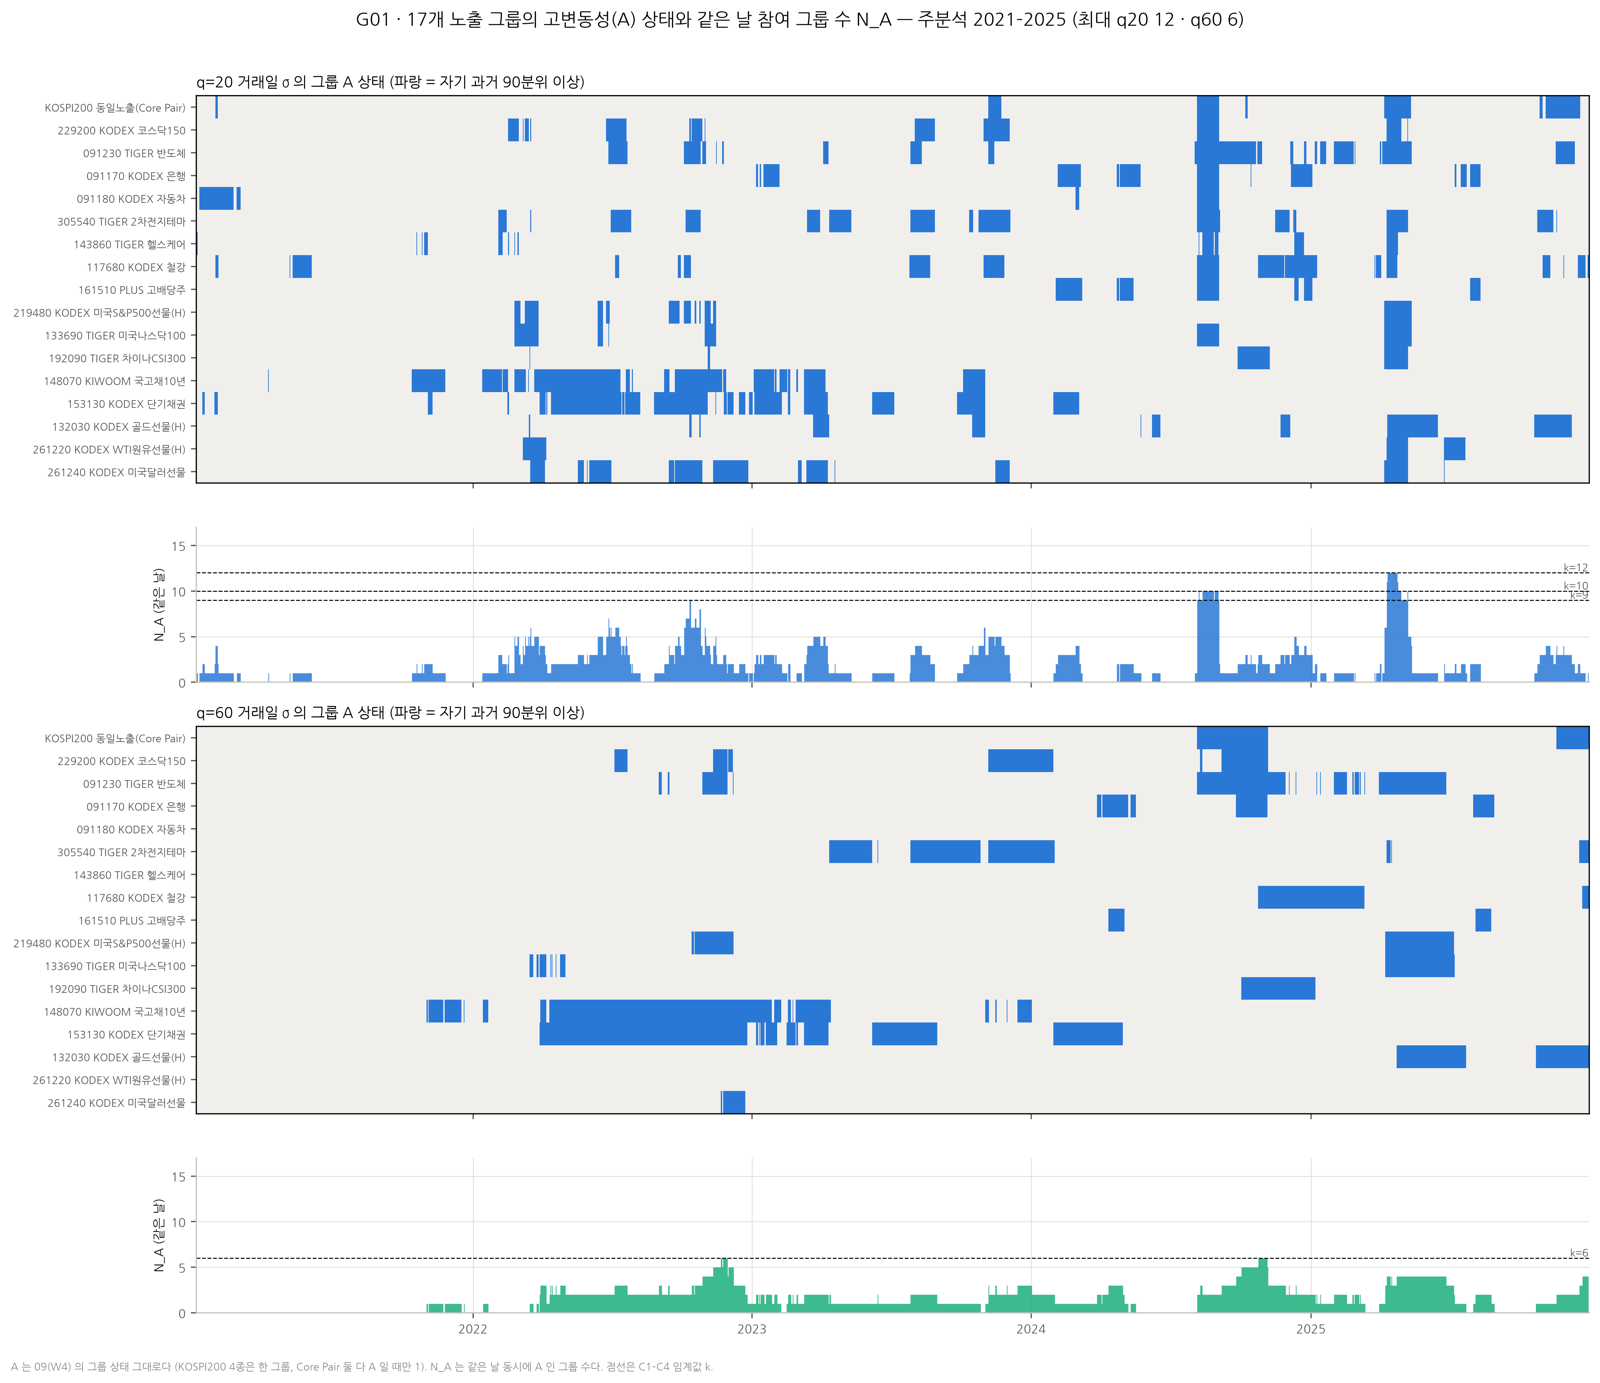

{"q20_max": 12, "q20_mean": 1.752, "q20_median": 1.0, "q60_max": 6, "q60_mean": 1.464, "q60_median": 1.0}


In [5]:
CAP["G01_group_A_state_maps"] = FG.g01_state_maps()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G01_group_A_state_maps.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G01_group_A_state_maps"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

**해석 (G01).**
- 주분석에서 같은 날 A 인 그룹 수 N_A 는 대부분 0–3 이다. 중앙값은 q20·q60 모두 1, 평균은 q20 1.75, q60 1.46 이다.
- q20 에서 N_A 가 9 이상으로 솟는 곳은 세 군데뿐이다: 2022-10, 2024-08, 2025-04.
- 2022 에는 채권(148070·153130)과 달러(261240)가 긴 띠를 만든다. 주식 그룹이 같이 켜지는 날은 짧다.
- q60 은 같은 사건을 늦고 길게 본다. 최대 6 은 2022-11 과 2024-10~11 에만 나온다.

## 5. 20일·60일 공통 고변동성 참여도

In [6]:
# 주분석 N_A 분포: k 이상인 날 수 (q20·q60). 같은 날 동시 참여 기준이다.
dist = pd.DataFrame({f"q{q}": [int((PRI[f"n_A_q{q}"] >= k).sum()) for k in range(0, 18)] for q in (20, 60)}, index=pd.Index(range(0, 18), name="k"))  # 생존표
display(dist.T)  # k 별 일수

k,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
q20,1225,789,497,321,182,118,65,46,41,39,28,11,9,0,0,0,0,0
q60,1225,843,557,231,108,41,14,0,0,0,0,0,0,0,0,0,0,0


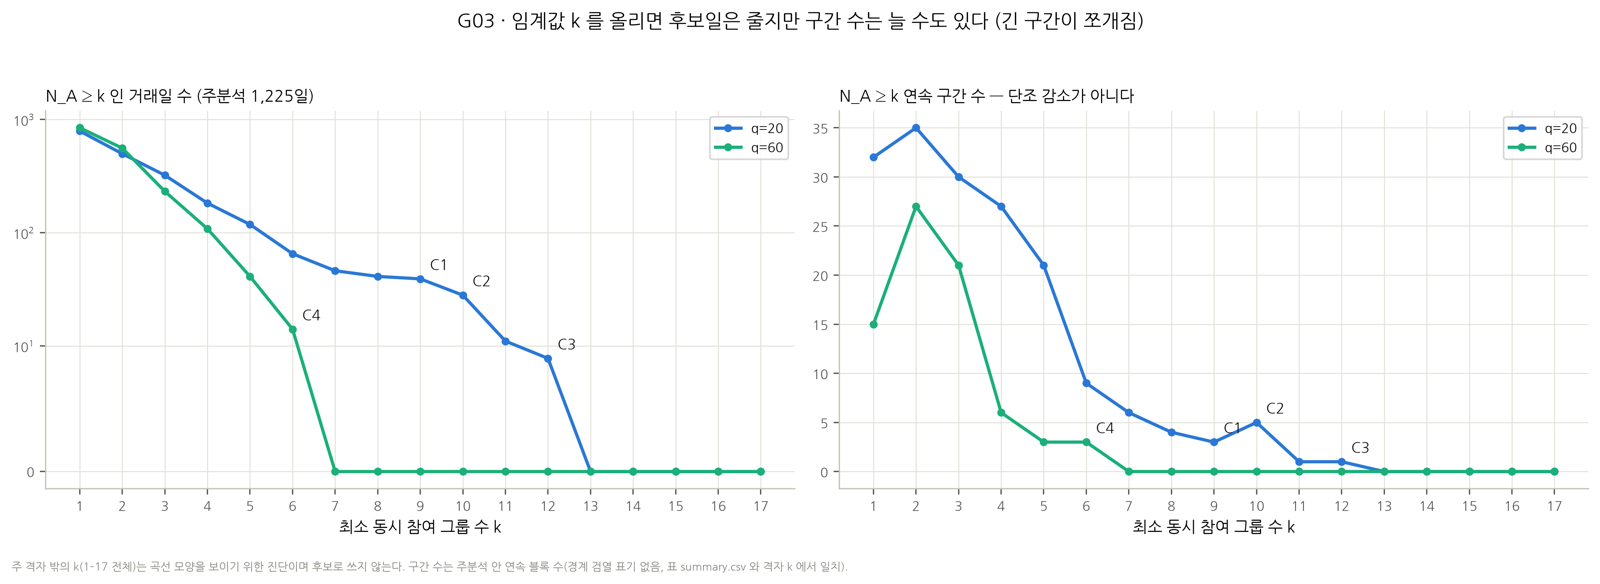

{"q20_days": {"1": 789, "2": 497, "3": 321, "4": 182, "5": 118, "6": 65, "7": 46, "8": 41, "9": 39, "10": 28, "11": 11, "12": 9, "13": 0, "14": 0, "15": 0, "16": 0, "17": 0}, "q20_intervals": {"1": 32, "2": 35, "3": 30, "4": 27, "5": 21, "6": 9, "7": 6, "8": 4, "9": 3, "10": 5, "11": 1, "12": 1, "13": 0, "14": 0, "15": 0, "16": 0, "17": 0}, "q60_days": {"1": 843, "2": 557, "3": 231, "4": 108, "5": 41, "6": 14, "7": 0, "8": 0, "9": 0, "10": 0, "11": 0, "12": 0, "13": 0, "14": 0, "15": 0, "16": 0, "17": 0}, "q60_intervals": {"1": 15, "2": 27, "3": 21, "4": 6, "5": 3, "6": 3, "7": 0, "8": 0, "9": 0, "10": 0, "11": 0, "12": 0, "13": 0, "14": 0, "15": 0, "16": 0, "17": 0}}


In [7]:
CAP["G03_k_survival_curves"] = FG.g03_k_curve()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G03_k_survival_curves.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G03_k_survival_curves"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

**해석 (G03).**
- q20 에서 N_A ≥ k 인 날은 k=7·8·9 에서 46·41·39일로 거의 평평하다. k=10 에서 28일, k=11 에서 11일로 급히 줄고, 13 이상은 0일이다.
- 따라서 k=9 는 평탄한 구간의 끝에 있다. k 를 7–9 사이에서 바꾸면 후보일이 크게 바뀌지 않는다. 반면 k=10 이상에서는 한 단계마다 결과가 크게 바뀐다.
- q60 은 k=6 에서 14일, k=7 이상에서 0일이다. q60 의 C4(k=6) 는 관측 최대값 바로 위의 칼날 위에 있다.
- 오른쪽 그림처럼 구간 수는 k 에 대해 단조가 아니다. q20 은 k=9 에서 3개, k=10 에서 5개다. 긴 구간이 하루 미충족 때문에 쪼개지기 때문이다.

## 6. C1–C4 후보 규칙과 계산 정의

`N_A(t,q) = Σ_g 1[A(g,t,q)=1]`, 후보 `C(k,q,t) = 1[N_A ≥ k]`. 17개 그룹 중 하나라도 NA 이면 그날은 NA 다.

| 후보 | q | k | 이름 | 목적 |
|---|---|---|---|---|
| C1 | 20 | 9 | 과반 공통 고변동성 | 노출 그룹의 과반이 같은 날 고변동성 |
| C2 | 20 | 10 | 강한 공통 고변동성 | C1 보다 강한 공통성 |
| C3 | 20 | 12 | 광범위한 극단적 고변동성 | 관측 최대 수준 (= 09 q20 최대) |
| C4 | 60 | 6 | 중기 고변동성 | 지속적 중기 국면 (= 09 q60 최대) |

- 통제 비교: k = 9·10·12 를 q60 에도, k = 6 을 q20 에도 적용한다. k = 17 은 W4 연결 참고, k = 3 은 W2 "3그룹 이상" 개념의 참고다.
- **C4 의 6/17 은 C1 의 9/17 보다 완화된 기준이다.** C1 과 C4 의 차이를 q 효과만으로 읽지 않는다.
- q=20 은 20거래일이다 (21일이 아니다). 변동성 측정기간 q 와 W1·W3 의 CUSUM 검정창 w 는 다른 개념이다.

In [8]:
display(R["rules"])  # 격자 12개 규칙과 역할

,rule,q,k,role,candidate,label
0,q20_k3,20,3,REFERENCE_W2,,W2 참고
1,q20_k6,20,6,DIAGNOSTIC,,진단
2,q20_k9,20,9,C1,C1,C1
3,q20_k10,20,10,C2,C2,C2
4,q20_k12,20,12,C3,C3,C3
5,q20_k17,20,17,REFERENCE_W4,,W4 연결 참고
6,q60_k3,60,3,REFERENCE_W2,,W2 참고
7,q60_k6,60,6,C4,C4,C4
8,q60_k9,60,9,HORIZON_CONTROL,,기간 통제
9,q60_k10,60,10,HORIZON_CONTROL,,기간 통제


## 7. 일별 후보 상태 생성

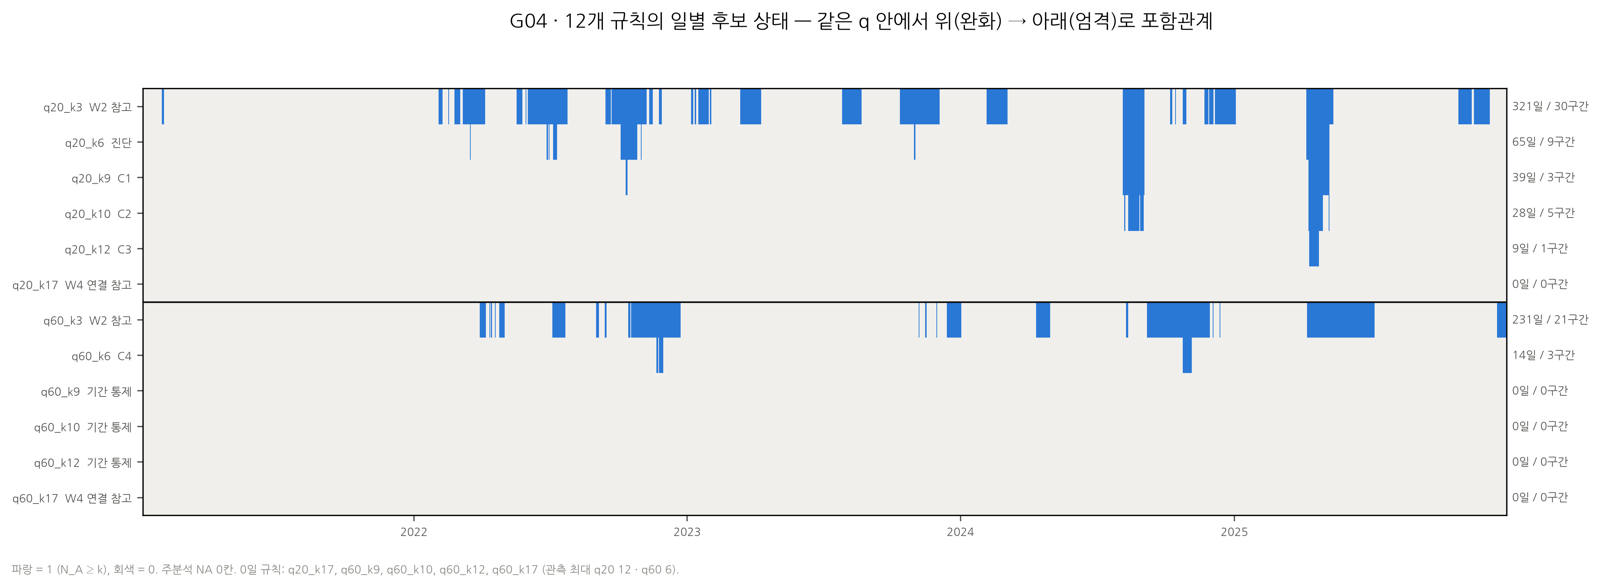

{"q20_k3": 321, "q20_k6": 65, "q20_k9": 39, "q20_k10": 28, "q20_k12": 9, "q20_k17": 0, "q60_k3": 231, "q60_k6": 14, "q60_k9": 0, "q60_k10": 0, "q60_k12": 0, "q60_k17": 0}


In [9]:
CAP["G04_rule_ribbons"] = FG.g04_rule_ribbons()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G04_rule_ribbons.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G04_rule_ribbons"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

In [10]:
# 무결성: 같은 q 에서 날짜 집합 포함관계 (k 가 크면 부분집합), 구간 날짜 = 후보일, 중복 포함 없음은 pipeline.check_intervals 가 assert 했다.
for q in (20, 60):  # 두 기간
    ks = CFG["k_grid"]  # 격자 k 3·6·9·10·12·17
    for k1, k2 in zip(ks[:-1], ks[1:]):  # 인접 k 쌍
        assert not ((D[f"q{q}_k{k2}"] == 1) & (D[f"q{q}_k{k1}"] != 1)).any()  # 엄격 ⊆ 완화
print("포함관계 OK: C3 ⊆ C2 ⊆ C1 (q20), q60 도 k 단조")  # 확인
display(R["integrity"][R["integrity"]["period"] == "PRIMARY"])  # 규칙별 후보일·구간 수·NA (주분석)

포함관계 OK: C3 ⊆ C2 ⊆ C1 (q20), q60 도 k 단조


,rule,period,candidate_days,n_intervals,na_days
2,q20_k3,PRIMARY,321,30,0
6,q20_k6,PRIMARY,65,9,0
10,q20_k9,PRIMARY,39,3,0
14,q20_k10,PRIMARY,28,5,0
18,q20_k12,PRIMARY,9,1,0
22,q20_k17,PRIMARY,0,0,0
26,q60_k3,PRIMARY,231,21,0
30,q60_k6,PRIMARY,14,3,0
34,q60_k9,PRIMARY,0,0,0
38,q60_k10,PRIMARY,0,0,0


**해석 (G04).**
- 같은 q 안에서 위(완화)에서 아래(엄격)로 갈수록 파란 날이 줄어들고, 아래 줄의 파란 날은 항상 위 줄에도 있다 (assert 통과).
- q60 은 k ≥ 9 에서 한 번도 켜지지 않는다. 관측 최대가 6 이기 때문이다. 0 도 유효한 결과이며 임계값을 바꾸지 않았다.

## 8. 실제 급변 후보 구간 전수 추출

규칙: 첫 1 이 시작일, 0 이 나오면 직전 1 에서 종료, 하루짜리 보존, 갭 병합 없음, NA 는 끊는 경계. 기간 첫날·마지막 날이 1 이면 옆 기간의 상태로 좌우 검열을 적는다.

In [11]:
# C1–C4 주분석 구간 전수. '동시 최대'(max_n_A) 와 '한 번이라도'(n_groups_ever) 를 따로 적는다.
COLS = ["interval_id", "candidate", "start", "end", "duration_trading_days", "max_n_A", "max_n_A_first_date", "n_days_at_max", "mean_n_A", "median_n_A", "start_n_A", "end_n_A", "n_groups_always", "n_groups_ever", "n_groups_never", "max_n_B", "max_n_AB", "evaluable_share", "left_censored", "right_censored", "exit_reason"]  # 표시 열
MAIN_IV = IVP[IVP["candidate"].isin(["C1", "C2", "C3", "C4"])]  # 주 후보 구간
display(MAIN_IV[COLS].round(2))  # 구간 표

,interval_id,candidate,start,end,duration_trading_days,max_n_A,max_n_A_first_date,n_days_at_max,mean_n_A,median_n_A,start_n_A,end_n_A,n_groups_always,n_groups_ever,n_groups_never,max_n_B,max_n_AB,evaluable_share,left_censored,right_censored,exit_reason
64,q20_k9_PRI_001,C1,2022-10-11,2022-10-12,2,9,2022-10-11,2,9.00,9.0,9,9,9,9,8,1,1,1.0,False,False,CONDITION_EXITED
65,q20_k9_PRI_002,C1,2024-08-05,2024-09-02,20,10,2024-08-07,14,9.70,10.0,9,9,9,10,7,5,3,1.0,False,False,CONDITION_EXITED
66,q20_k9_PRI_003,C1,2025-04-10,2025-05-07,17,12,2025-04-11,9,11.00,12.0,11,10,8,12,5,3,1,1.0,False,False,CONDITION_EXITED
74,q20_k10_PRI_001,C2,2024-08-07,2024-08-07,1,10,2024-08-07,1,10.00,10.0,10,10,10,10,7,4,3,1.0,False,False,CONDITION_EXITED
75,q20_k10_PRI_002,C2,2024-08-12,2024-08-26,10,10,2024-08-12,10,10.00,10.0,10,10,10,10,7,3,3,1.0,False,False,CONDITION_EXITED
76,q20_k10_PRI_003,C2,2024-08-28,2024-08-30,3,10,2024-08-28,3,10.00,10.0,10,10,10,10,7,3,3,1.0,False,False,CONDITION_EXITED
77,q20_k10_PRI_004,C2,2025-04-10,2025-04-28,13,12,2025-04-11,9,11.54,12.0,11,10,9,12,5,2,1,1.0,False,False,CONDITION_EXITED
78,q20_k10_PRI_005,C2,2025-05-07,2025-05-07,1,10,2025-05-07,1,10.00,10.0,10,10,10,10,7,3,1,1.0,False,False,CONDITION_EXITED
86,q20_k12_PRI_001,C3,2025-04-11,2025-04-23,9,12,2025-04-11,9,12.00,12.0,12,12,12,12,5,2,1,1.0,False,False,CONDITION_EXITED
115,q60_k6_PRI_001,C4,2022-11-21,2022-11-22,2,6,2022-11-21,2,6.00,6.0,6,6,6,6,11,2,1,1.0,False,False,CONDITION_EXITED


In [12]:
# 구간별 참여 그룹 명단: 최대 첫날 · 매일 · 전혀 참여 안 함 (그룹 ID 는 ETF 코드, KOSPI200 은 묶음 그룹).
display(MAIN_IV[["interval_id", "groups_at_max_first_day", "groups_always", "groups_never"]])  # 명단 표

,interval_id,groups_at_max_first_day,groups_always,groups_never
64,q20_k9_PRI_001,229200|091230|305540|117680|219480|148070|153130|132030|261240,229200|091230|305540|117680|219480|148070|153130|132030|261240,KOSPI200_동일노출|091170|091180|143860|161510|133690|192090|261220
65,q20_k9_PRI_002,KOSPI200_동일노출|229200|091230|091170|091180|305540|143860|117680|161510|133690,KOSPI200_동일노출|229200|091230|091170|091180|305540|117680|161510|133690,219480|192090|148070|153130|132030|261220|261240
66,q20_k9_PRI_003,KOSPI200_동일노출|229200|091230|305540|143860|117680|219480|133690|192090|132030|261220|261240,KOSPI200_동일노출|091230|305540|219480|133690|192090|261220|261240,091170|091180|161510|148070|153130
74,q20_k10_PRI_001,KOSPI200_동일노출|229200|091230|091170|091180|305540|143860|117680|161510|133690,KOSPI200_동일노출|229200|091230|091170|091180|305540|143860|117680|161510|133690,219480|192090|148070|153130|132030|261220|261240
75,q20_k10_PRI_002,KOSPI200_동일노출|229200|091230|091170|091180|305540|143860|117680|161510|133690,KOSPI200_동일노출|229200|091230|091170|091180|305540|143860|117680|161510|133690,219480|192090|148070|153130|132030|261220|261240
76,q20_k10_PRI_003,KOSPI200_동일노출|229200|091230|091170|091180|305540|143860|117680|161510|133690,KOSPI200_동일노출|229200|091230|091170|091180|305540|143860|117680|161510|133690,219480|192090|148070|153130|132030|261220|261240
77,q20_k10_PRI_004,KOSPI200_동일노출|229200|091230|305540|143860|117680|219480|133690|192090|132030|261220|261240,KOSPI200_동일노출|229200|091230|305540|219480|133690|192090|261220|261240,091170|091180|161510|148070|153130
78,q20_k10_PRI_005,KOSPI200_동일노출|229200|091230|305540|219480|133690|192090|132030|261220|261240,KOSPI200_동일노출|229200|091230|305540|219480|133690|192090|132030|261220|261240,091170|091180|143860|117680|161510|148070|153130
86,q20_k12_PRI_001,KOSPI200_동일노출|229200|091230|305540|143860|117680|219480|133690|192090|132030|261220|261240,KOSPI200_동일노출|229200|091230|305540|143860|117680|219480|133690|192090|132030|261220|261240,091170|091180|161510|148070|153130
115,q60_k6_PRI_001,229200|091230|219480|148070|153130|261240,229200|091230|219480|148070|153130|261240,KOSPI200_동일노출|091170|091180|305540|143860|117680|161510|133690|192090|132030|261220


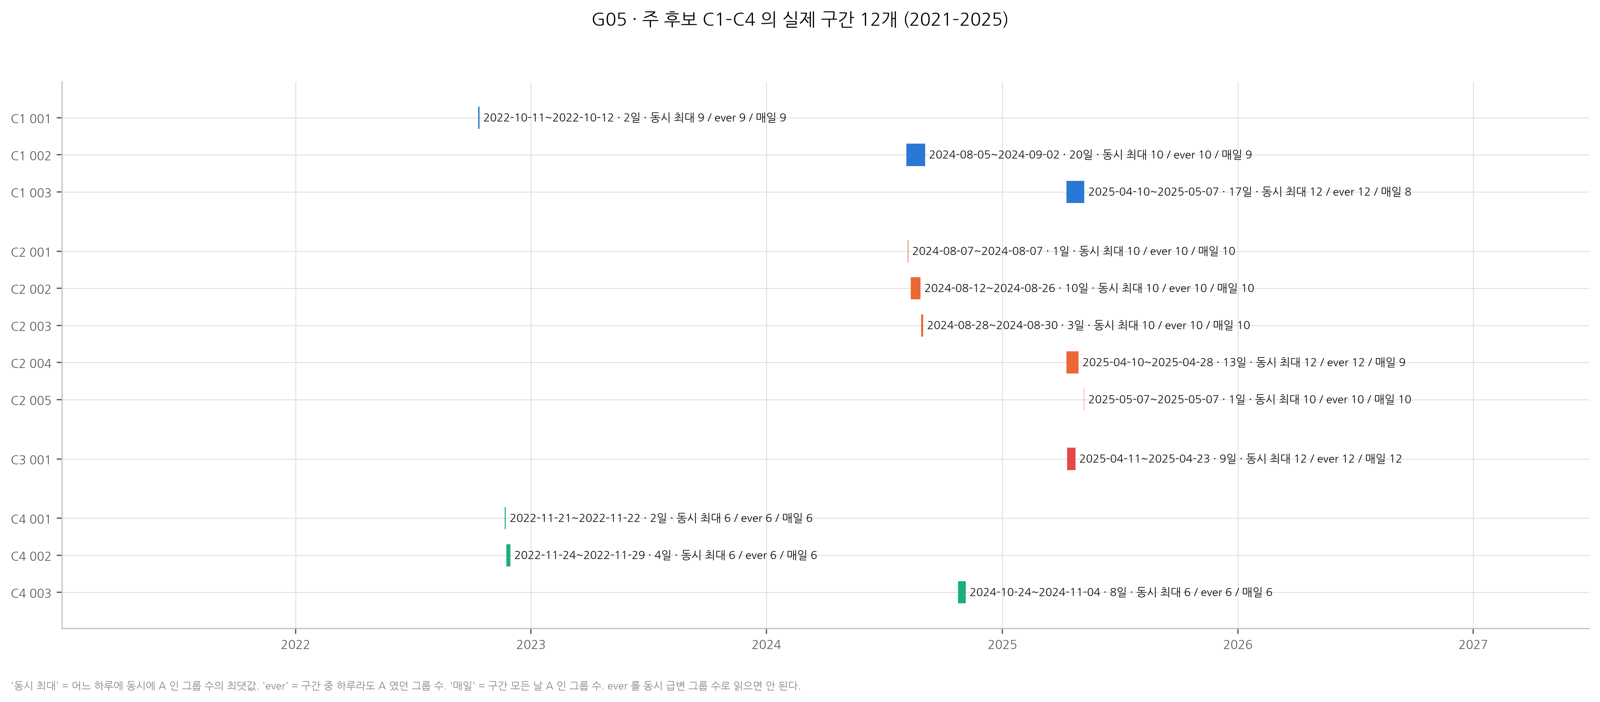

{"n": 12}


In [13]:
CAP["G05_candidate_gantt"] = FG.g05_gantt()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G05_candidate_gantt.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G05_candidate_gantt"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

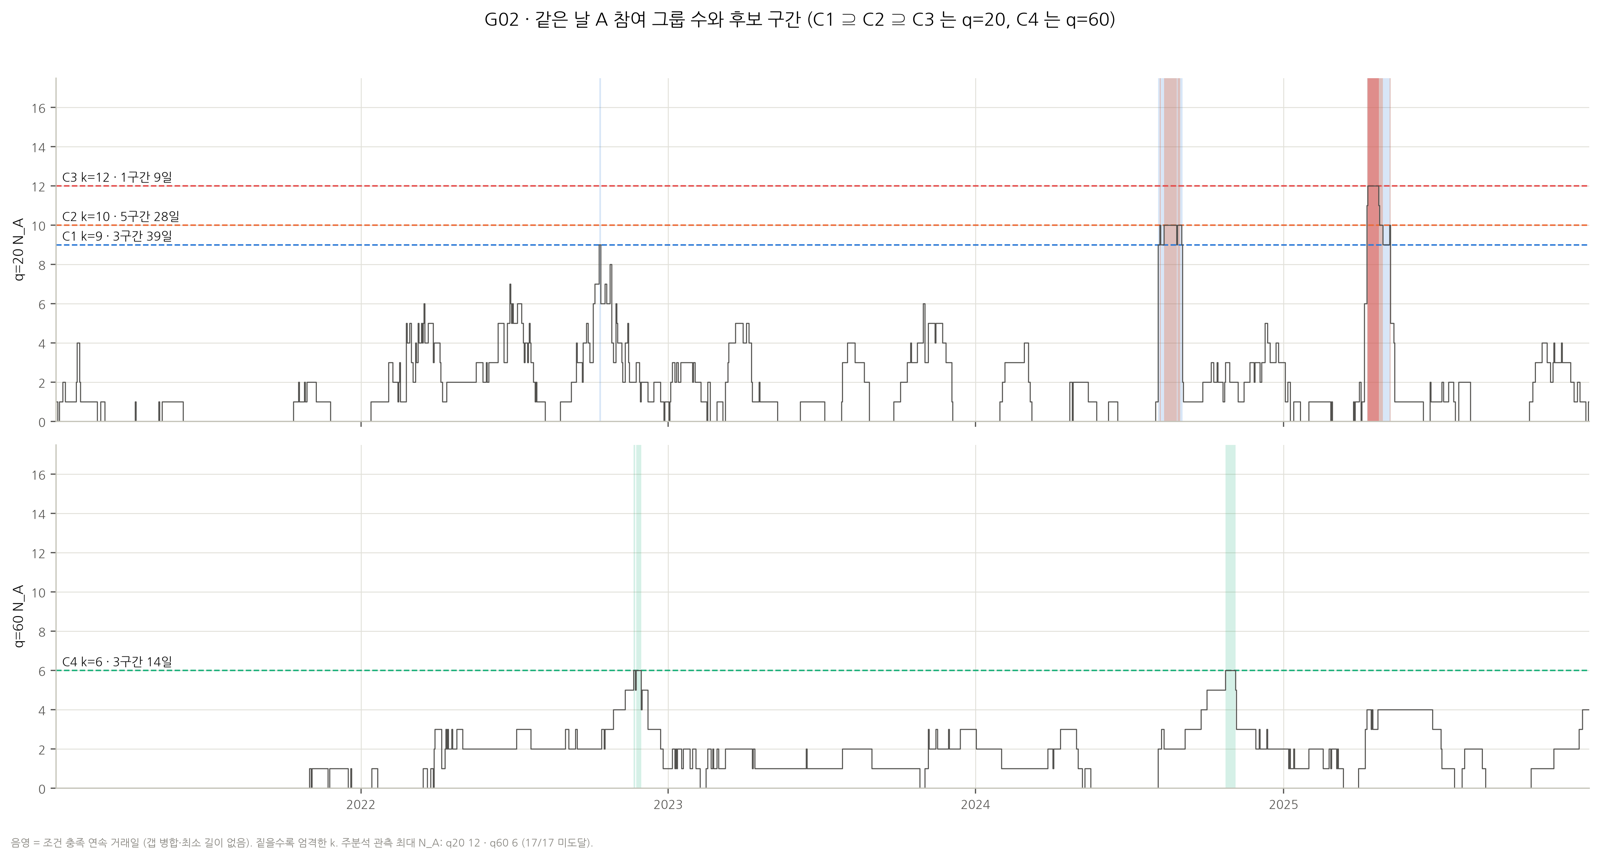

{"C1": {"n_intervals": 3, "days": 39}, "C2": {"n_intervals": 5, "days": 28}, "C3": {"n_intervals": 1, "days": 9}, "C4": {"n_intervals": 3, "days": 14}}


In [14]:
CAP["G02_count_and_candidate_intervals"] = FG.g02_count_with_intervals()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G02_count_and_candidate_intervals.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G02_count_and_candidate_intervals"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

**해석 (G05·G02).** 주분석 2021–2025 에서 실제로 나온 구간은 다음과 같다.

| 후보 | 구간 | 거래일 | 동시 최대 N_A |
|---|---|---|---|
| C1 (q20 k9) | 2022-10-11~10-12 | 2 | 9 |
| | 2024-08-05~09-02 | 20 | 10 |
| | 2025-04-10~05-07 | 17 | 12 |
| C2 (q20 k10) | 2024-08-07 | 1 | 10 |
| | 2024-08-12~08-26 | 10 | 10 |
| | 2024-08-28~08-30 | 3 | 10 |
| | 2025-04-10~04-28 | 13 | 12 |
| | 2025-05-07 | 1 | 10 |
| C3 (q20 k12) | 2025-04-11~04-23 | 9 | 12 |
| C4 (q60 k6) | 2022-11-21~11-22 | 2 | 6 |
| | 2022-11-24~11-29 | 4 | 6 |
| | 2024-10-24~11-04 | 8 | 6 |

- 주 후보 구간은 모두 12개이고, 좌우 검열된 구간은 없다. 모든 구간은 다음 날 조건 미충족(0)으로 끝났다.
- 모든 주 후보 구간에서 ever 참여 그룹 수가 동시 최대 N_A 와 같다. 구간 중 참여한 그룹이 최대일에 모두 함께 A 였다는 뜻이다. 그래도 이 값은 데이터가 정한 결과일 뿐이다. 표현은 항상 '동시 최대' 기준으로 한다.
- C4 의 2022-11 은 11-23 하루가 5/17 로 내려가 두 구간으로 나뉜다. 갭 병합을 하지 않는 주 정의 그대로다.

## 9. 후보 정의별 구간 수·지속일·범위 비교

In [15]:
# 12개 규칙 전수 비교표 (주분석). 0개 규칙은 gap = k − 관측 최대 를 함께 적는다.
SHOW = ["rule", "label", "q", "k", "n_intervals", "candidate_days", "candidate_share", "n_one_day", "duration_mean", "duration_median", "duration_max", "observed_max_n_A", "gap_k_minus_max", "mean_n_A_on_candidate_days", "mean_stability_jaccard", "mean_core_share", "top5_longest"]  # 표시 열
display(SM[SHOW].round(3))  # 전수 비교표

,rule,label,q,k,n_intervals,candidate_days,candidate_share,n_one_day,duration_mean,duration_median,duration_max,observed_max_n_A,gap_k_minus_max,mean_n_A_on_candidate_days,mean_stability_jaccard,mean_core_share,top5_longest
0,q20_k3,W2 참고,20,3,30,321,0.262,5,10.700,5.0,37,12,0,4.679,0.910,0.685,2023-10-12~2023-12-01 (37일); 2022-06-02~2022-07-22 (36일); 2022-09-22~2022-11-07 (31일); 2025-04-07~2025-05-12 (23일); 2022-03-07~2022-04-0...
1,q20_k6,진단,20,6,9,65,0.053,3,7.222,2.0,20,12,0,8.677,0.945,0.856,2024-08-05~2024-09-02 (20일); 2025-04-07~2025-05-07 (20일); 2022-10-04~2022-10-25 (15일); 2022-07-06~2022-07-08 (3일); 2022-06-27~2022-06-28...
2,q20_k9,C1,20,9,3,39,0.032,0,13.000,17.0,20,12,0,10.231,0.980,0.856,2024-08-05~2024-09-02 (20일); 2025-04-10~2025-05-07 (17일); 2022-10-11~2022-10-12 (2일)
3,q20_k10,C2,20,10,5,28,0.023,2,5.600,3.0,13,12,0,10.714,0.993,0.950,2025-04-10~2025-04-28 (13일); 2024-08-12~2024-08-26 (10일); 2024-08-28~2024-08-30 (3일); 2024-08-07~2024-08-07 (1일); 2025-05-07~2025-05-07 ...
4,q20_k12,C3,20,12,1,9,0.007,0,9.000,9.0,9,12,0,12.000,1.000,1.000,2025-04-11~2025-04-23 (9일)
5,q20_k17,W4 연결 참고,20,17,0,0,0.000,0,NaN,NaN,0,12,5,NaN,NaN,NaN,
6,q60_k3,W2 참고,60,3,21,231,0.189,9,11.000,2.0,59,6,0,3.706,0.989,0.888,2025-04-08~2025-07-04 (59일); 2024-09-06~2024-11-28 (54일); 2022-10-18~2022-12-22 (48일); 2022-07-05~2022-07-21 (13일); 2024-04-11~2024-04-2...
7,q60_k6,C4,60,6,3,14,0.011,0,4.667,4.0,8,6,0,6.000,1.000,1.000,2024-10-24~2024-11-04 (8일); 2022-11-24~2022-11-29 (4일); 2022-11-21~2022-11-22 (2일)
8,q60_k9,기간 통제,60,9,0,0,0.000,0,NaN,NaN,0,6,3,NaN,NaN,NaN,
9,q60_k10,기간 통제,60,10,0,0,0.000,0,NaN,NaN,0,6,4,NaN,NaN,NaN,


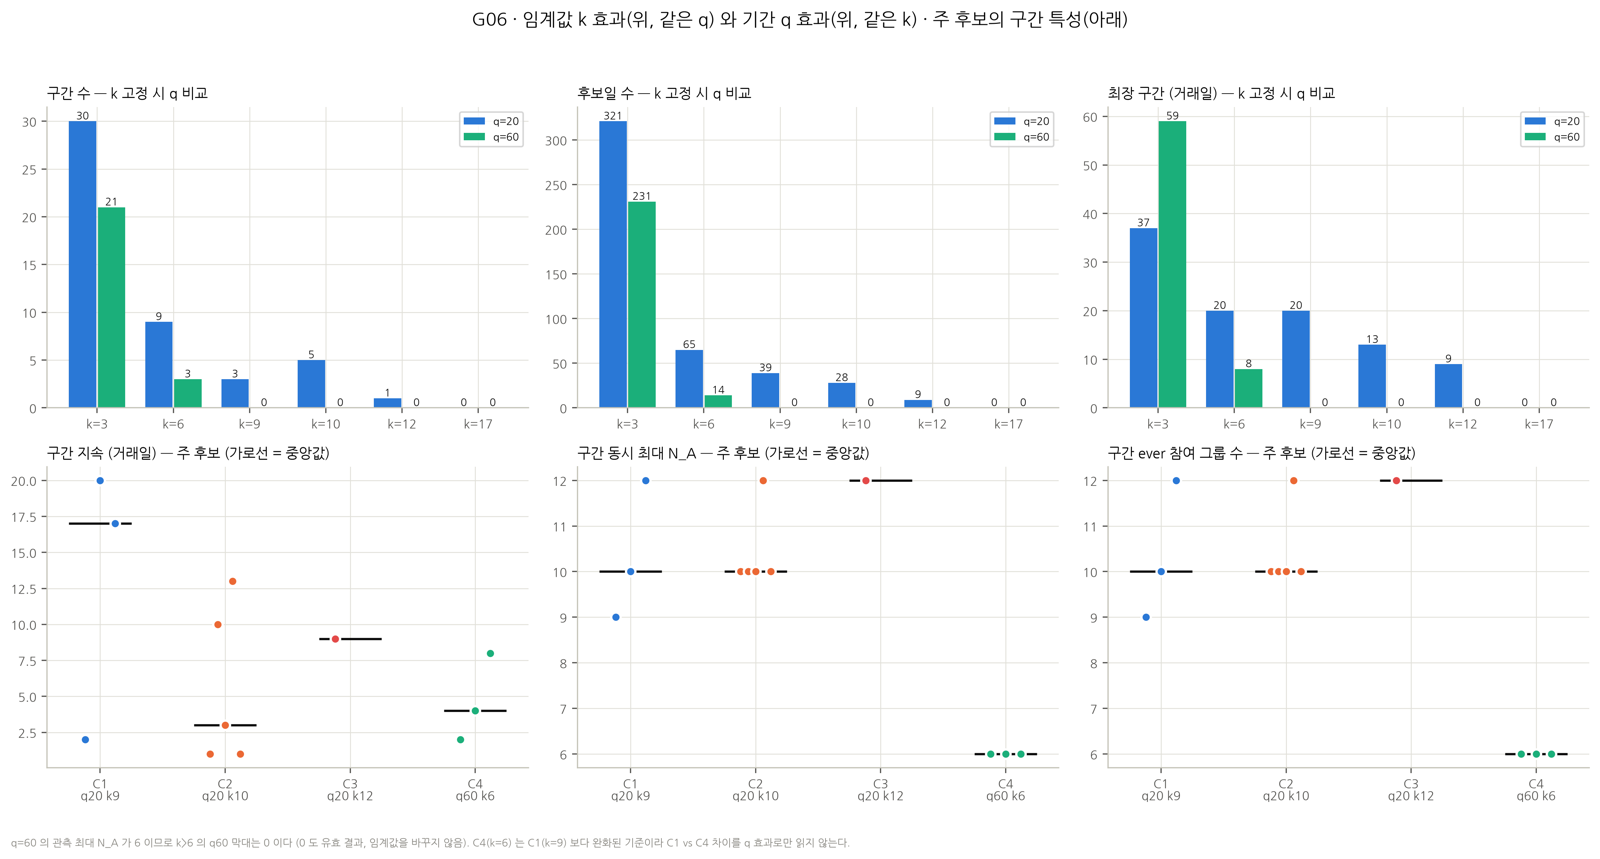

{}


In [16]:
CAP["G06_k_and_q_effects"] = FG.g06_effects()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G06_k_and_q_effects.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G06_k_and_q_effects"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

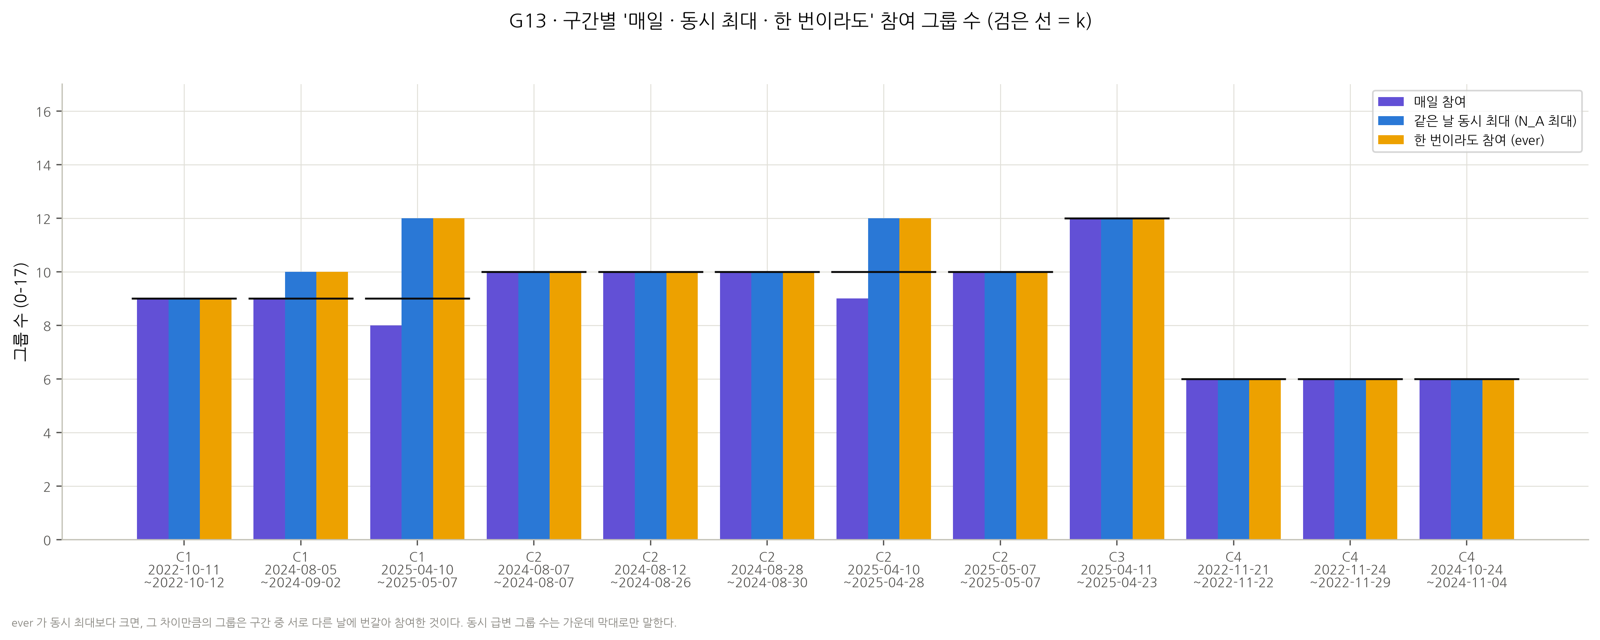

{"max_gap_ever_minus_max": 0}


In [17]:
CAP["G13_simultaneous_vs_ever"] = FG.g13_simul_vs_ever()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G13_simultaneous_vs_ever.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G13_simultaneous_vs_ever"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

**해석 (G06·G13).**
- **C1**: 3구간, 39일 (주분석의 3.2%). 1일 구간 0개, 지속 중앙값 17일. 인접일 참여 집합 Jaccard 평균 0.98 로 구성이 안정적이다.
- **C2**: 5구간, 28일 (2.3%). 1일 구간이 2개다. 2024-08 의 C1 구간 하나가 C2 에서 세 조각이 된다.
- **C3**: 1구간, 9일 (0.7%). 2025-04 하나만 남는다.
- **C4**: 3구간, 14일 (1.1%). 지속 중앙값 4일, 최장 8일로 C1 보다 짧다.
- 0개 규칙: q20 k17 (gap 5), q60 k9·k10·k12·k17 (gap 3·4·6·11). 이 기준들은 2021–2025 에 관측된 공통성 수준을 넘는다.
- G13 에서 세 막대(매일·동시 최대·ever)가 겹치는 정도가 '같은 날 동시 급변' 의 순도다. C3·C4 는 세 값이 모두 같다. C1 의 2025-04 구간은 매일 참여 8, 동시 최대 12 로 차이가 가장 크다.

## 10. 임계값 k 의 효과 (q 고정)

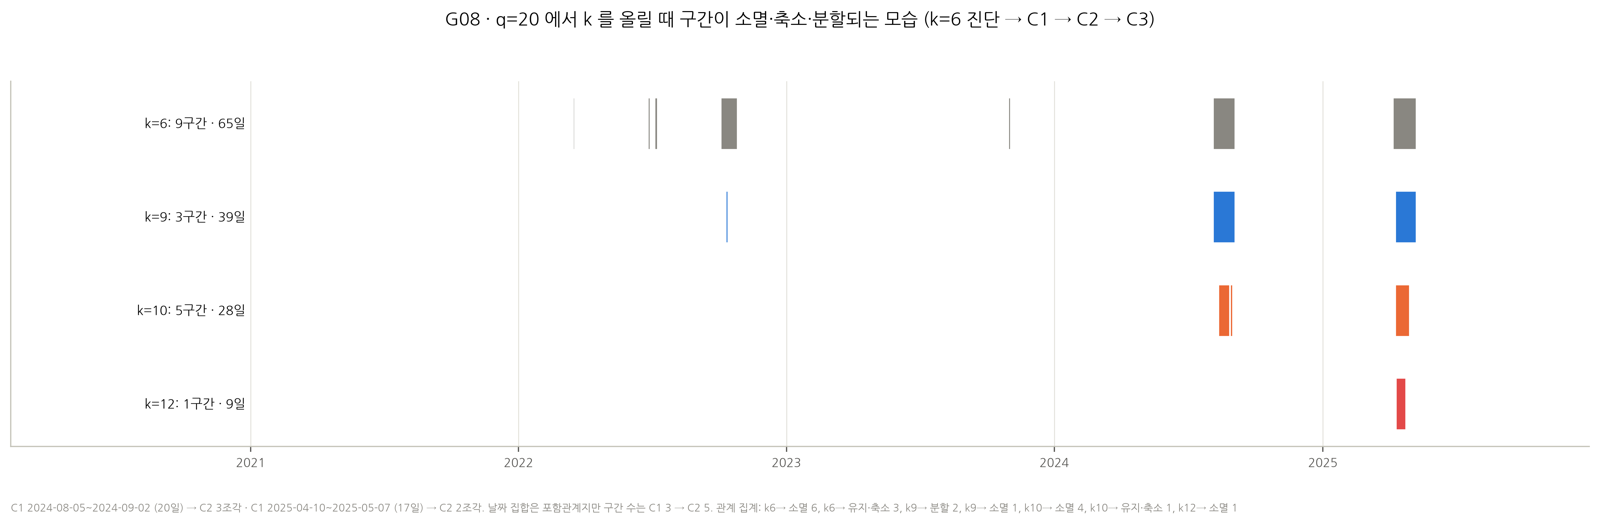

{"6": 9, "9": 3, "10": 5, "12": 1}


In [18]:
CAP["G08_split_and_vanish"] = FG.g08_split()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G08_split_and_vanish.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G08_split_and_vanish"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

In [19]:
# k 를 한 단계 올릴 때 완화 규칙의 각 구간이 소멸·유지·분할되는지 (q20, k 6→9→10→12→17).
KID = R["split_kids"]  # 완화 구간별 자식 수
display(KID[(KID["q"] == 20) & (KID["k_loose"] >= 6)][["k_loose", "k_strict", "loose_id", "start", "end", "loose_days", "n_children", "strict_days_kept", "relation"]])  # 분할 표
display(R["jaccard"].pivot(index="rule_a", columns="rule_b", values="jaccard").loc[["q20_k6", "q20_k9", "q20_k10", "q20_k12"], ["q20_k6", "q20_k9", "q20_k10", "q20_k12"]].round(3))  # q20 날짜 Jaccard

,k_loose,k_strict,loose_id,start,end,loose_days,n_children,strict_days_kept,relation
30,6,9,q20_k6_PRI_001,2022-03-17,2022-03-17,1,0,0,소멸
31,6,9,q20_k6_PRI_002,2022-06-27,2022-06-28,2,0,0,소멸
32,6,9,q20_k6_PRI_003,2022-06-30,2022-06-30,1,0,0,소멸
33,6,9,q20_k6_PRI_004,2022-07-06,2022-07-08,3,0,0,소멸
34,6,9,q20_k6_PRI_005,2022-10-04,2022-10-25,15,1,2,유지·축소
35,6,9,q20_k6_PRI_006,2022-10-31,2022-10-31,1,0,0,소멸
36,6,9,q20_k6_PRI_007,2023-10-31,2023-11-01,2,0,0,소멸
37,6,9,q20_k6_PRI_008,2024-08-05,2024-09-02,20,1,20,유지·축소
38,6,9,q20_k6_PRI_009,2025-04-07,2025-05-07,20,1,17,유지·축소
39,9,10,q20_k9_PRI_001,2022-10-11,2022-10-12,2,0,0,소멸


rule_b,q20_k6,q20_k9,q20_k10,q20_k12
rule_a,,,,
q20_k6,1.000,0.600,0.431,0.138
q20_k9,0.600,1.000,0.718,0.231
q20_k10,0.431,0.718,1.000,0.321
q20_k12,0.138,0.231,0.321,1.000


**해석 (G08).**
- k=6 (진단) → C1: 9개 구간 중 6개가 사라진다. 2022-03-17, 2022-06-27~28, 06-30, 07-06~08, 10-31, 2023-10-31~11-01 의 1–3일 구간들이다. 2022-10, 2024-08, 2025-04 셋만 남는다.
- C1 → C2: 2022-10-11~12 (N_A 9) 가 사라진다. 2024-08 (20일)은 3개로, 2025-04 (17일)는 2개로 **분할**된다. 날짜는 39 → 28일로 줄지만 구간은 3 → 5개로 늘어난다.
  - 2024-08 이 나뉘는 날은 08-05·06·08·09·27, 09-02 이다. 이날들의 N_A 는 9 다.
  - 2025-04 가 나뉘는 날은 04-29·30, 05-02 이다. 역시 N_A 9 다.
- C2 → C3: 2024-08 이 통째로 사라진다 (그 사건의 최대는 10). 2025-04-11~23 만 남는다.
- 날짜 Jaccard: C1–C2 0.72, C1–C3 0.23. 같은 q 안에서는 포함관계라 Jaccard = |엄격|/|완화| 이다.
- 결론: k 는 '어떤 사건이 남는가' 와 '사건이 몇 조각으로 보이는가' 를 함께 바꾼다. k=10 은 N_A 가 9–10 을 오가는 사건(2024-08)을 조각낸다.

## 11. 기간 q 의 효과 (k 고정)

In [20]:
display(R["horizon"])  # k 별 q20 vs q60 날짜 겹침·Jaccard·겹치는 구간 쌍

,k,q20_days,q60_days,both_days,q20_only_days,q60_only_days,jaccard,q20_intervals,q60_intervals,overlapping_pairs,q20_intervals_touching_q60,q20_max,q60_max
0,3,321,231,79,242,152,0.167019,30,21,19,15,12,6
1,6,65,14,0,65,14,0.000000,9,3,0,0,12,6
2,9,39,0,0,39,0,0.000000,3,0,0,0,12,6
3,10,28,0,0,28,0,0.000000,5,0,0,0,12,6
4,12,9,0,0,9,0,0.000000,1,0,0,0,12,6
5,17,0,0,0,0,0,NaN,0,0,0,0,12,6


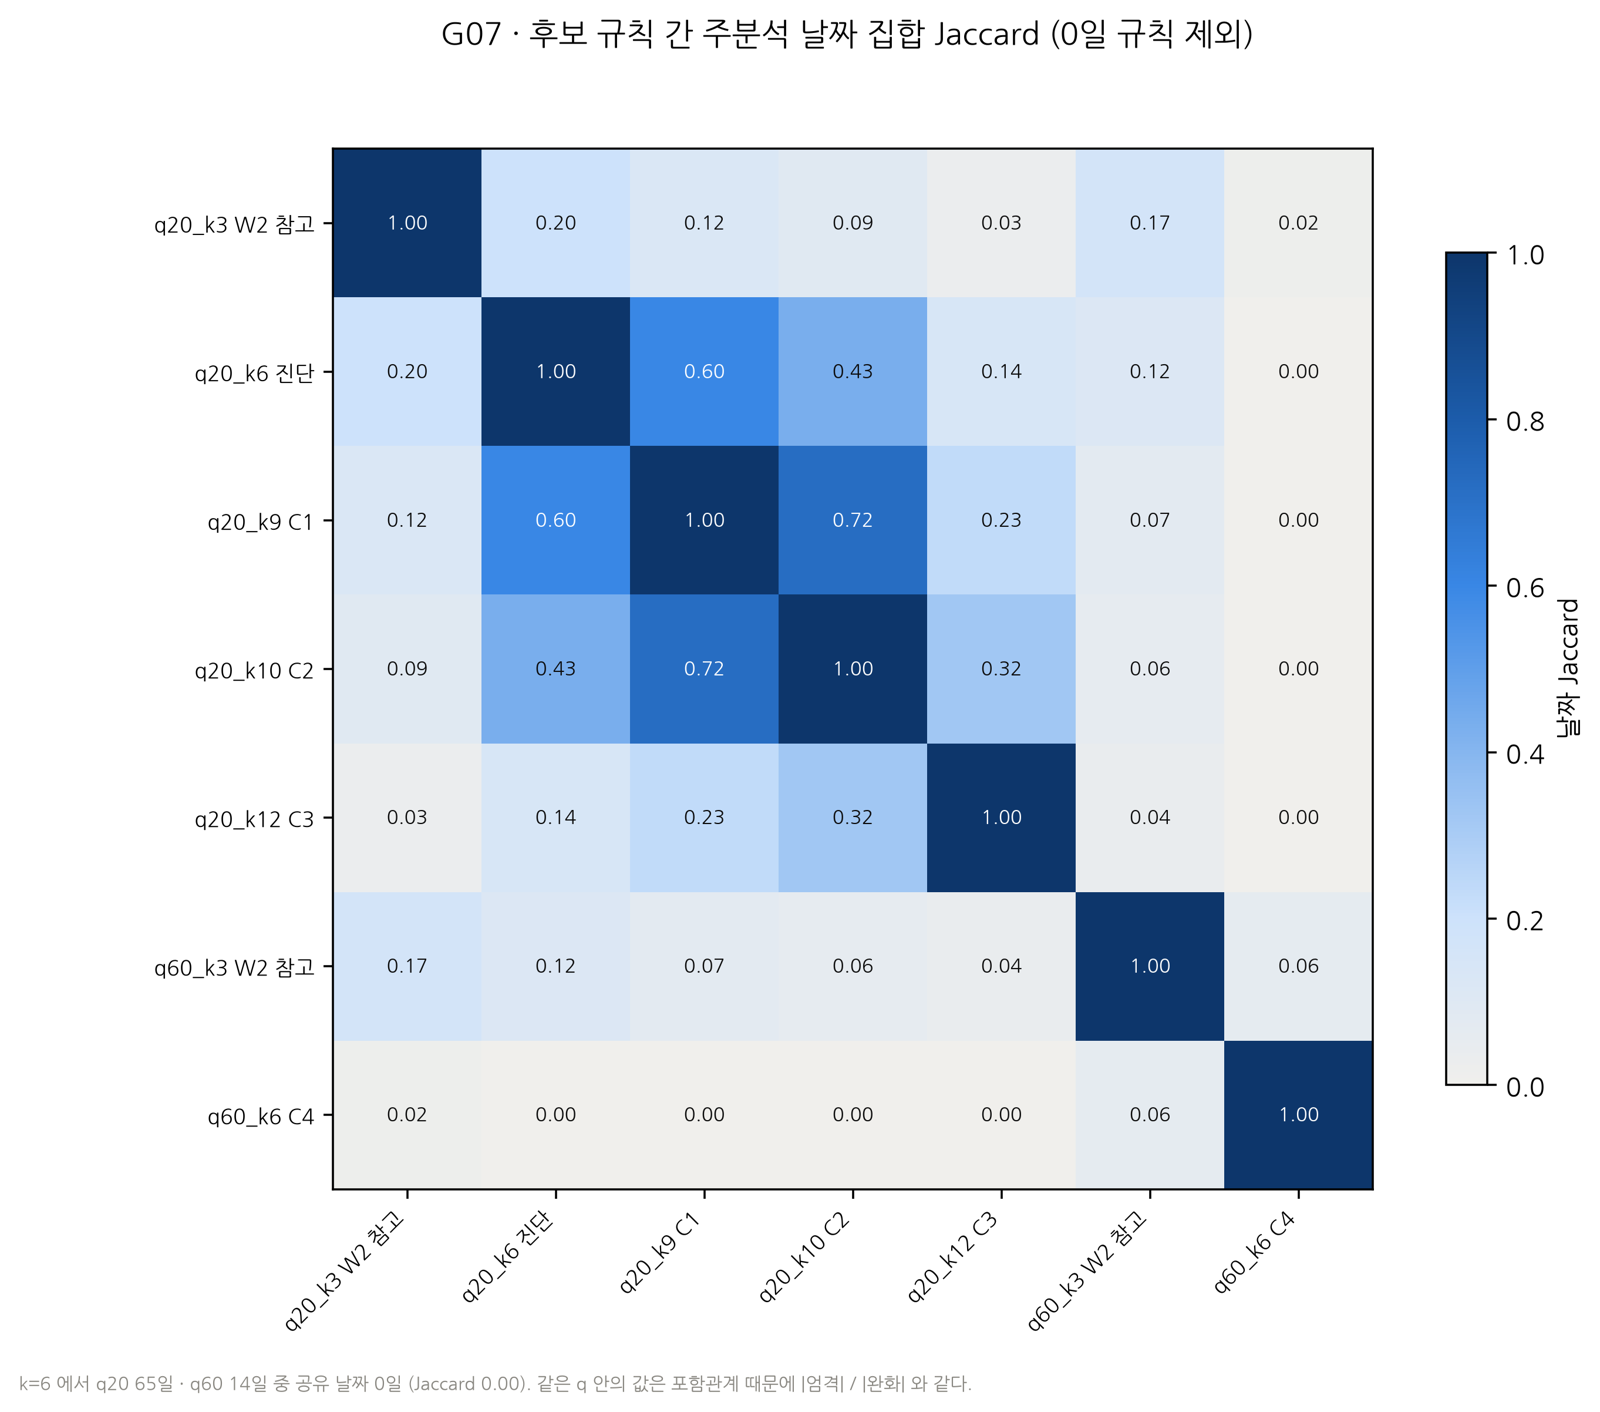

{"C1_C2": 0.7179, "C1_C4": 0.0}


In [21]:
CAP["G07_rule_jaccard"] = FG.g07_jaccard()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G07_rule_jaccard.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G07_rule_jaccard"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

**해석 (G07, 기간 통제).**
- 같은 k=6 에서 q20 은 65일, q60 은 14일이다. **겹치는 날은 0일**이다 (Jaccard 0). 20일 창이 공통 고변동성을 보일 때 60일 창은 아직 오르는 중이고, 60일 창이 최대일 때 20일 창은 이미 내려온 뒤다.
- k=3 에서도 Jaccard 는 0.17 이다. q20 구간 30개 중 q60 구간과 한 번이라도 겹치는 것은 15개다.
- k = 9·10·12 에서 q60 은 0일이다. 따라서 "C1 은 q20, C4 는 q60" 의 차이에는 k 의 차이(9 vs 6)와 q 의 차이가 섞여 있다. 같은 k=9 로 비교하면 q60 은 아무 구간도 만들지 않는다.
- 해석: q20 은 **충격 시점의 동시 고변동성**을, q60 은 **충격 뒤 남은 고변동성의 누적**을 본다. 둘은 같은 현상의 다른 단면이며 한쪽이 다른 쪽을 대신하지 않는다.

# PART D · 정의를 단단하게 — `10-lock-2` 확장

lock-1 결과(C1–C4)를 본 뒤 설계했다. 계약 `CANDIDATE_RESEARCH_CONTRACT_LOCK2.md` 에 반복 수(2,000)·시드(20261019)·유의수준(일별 1%, 기간 5%)·이탈 k(진입 − 2)·균형 문턱(9/17)을 계산 전에 고정했다. 여전히 검정이 아니라 **정의 선택을 위한 탐색**이다.

## D1. 우연 기준선 — k 는 어디서 우연을 벗어나나

귀무: 주분석 1,225일 안에서 17개 그룹의 A 시계열을 **그룹마다 독립 무작위 시차로 원형 이동**한다. 각 그룹의 급변 빈도와 지속(자기상관)은 그대로이고, 그룹 간 동시성만 사라진다.

In [22]:
# 우연 기준 문턱 k*: 일별 1% (k*_day), 5년 중 하루라도 5% (k*_fw). 관측 N_A ≥ k 일수와 귀무 기대 일수.
display(X["kstar"])  # q 별 k*
NT = X["null"]  # 귀무 표
display(NT[NT["k"].between(4, 13)].round(5))  # 관측 vs 귀무

,q,k_star_day,k_star_fw,obs_max,null_mean_N_A
0,20,6,9,12,1.751837
1,60,5,7,6,1.464490


,q,k,p_day_null,p_fw_null,obs_days,obs_share,expected_days_null
4,20,4,0.08642,1.0000,182,0.14857,105.8585
5,20,5,0.02268,0.9975,118,0.09633,27.7865
6,20,6,0.00453,0.7710,65,0.05306,5.5520
7,20,7,0.00076,0.2345,46,0.03755,0.9280
8,20,8,0.00011,0.0520,41,0.03347,0.1330
9,20,9,0.00001,0.0050,39,0.03184,0.0140
10,20,10,0.00000,0.0005,28,0.02286,0.0015
11,20,11,0.00000,0.0000,11,0.00898,0.0000
12,20,12,0.00000,0.0000,9,0.00735,0.0000
13,20,13,0.00000,0.0000,0,0.00000,0.0000


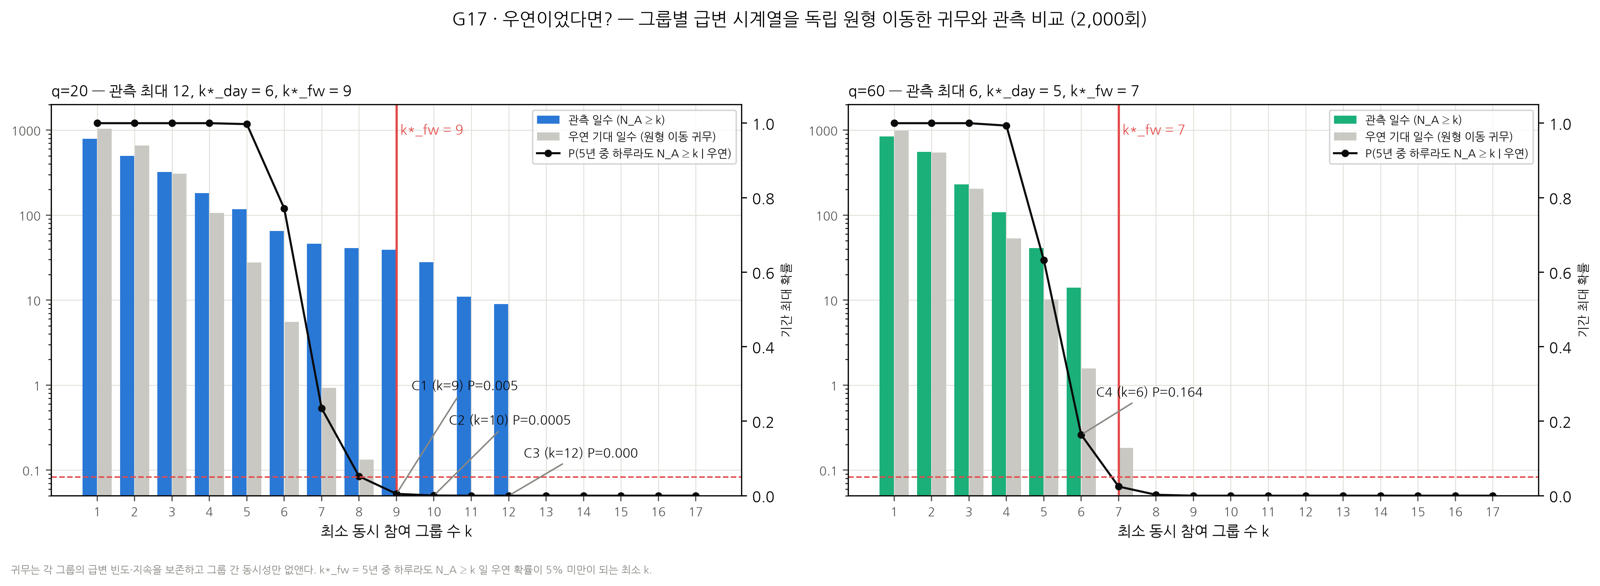

{"C1": 0.005, "C2": 0.0005, "C3": 0.0, "q20": {"k_star_fw": 9, "k_star_day": 6}, "C4": 0.1635, "q60": {"k_star_fw": 7, "k_star_day": 5}}


In [23]:
CAP["G17_null_kstar"] = FG.g17_null()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G17_null_kstar.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G17_null_kstar"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

**해석 (D1).**
- 귀무의 평균 N_A 는 관측과 같다 (q20 1.75, q60 1.46). 원형 이동이 각 그룹의 급변 비율을 보존하기 때문이다. 다른 것은 **동시에 몰리는 정도**뿐이다.
- **q20**: 5년 중 하루라도 N_A ≥ 8 이 우연히 나올 확률은 0.052, ≥ 9 는 0.005 다. 따라서 k*_fw = 9 이고, **C1 의 k=9 가 우연 기준을 처음 넘는 문턱과 정확히 같다.** 귀무에서 N_A ≥ 9 인 날의 기대 일수는 0.014일인데 관측은 39일이다. C2 (0.0005)·C3 (0) 도 기준을 넘는다.
- 일별 기준(k*_day = 6)은 하루 단위의 1% 선이다. 5년 내내 매일 보면 우연히도 넘는 날이 생기므로, 구간 정의에는 기간 기준(k*_fw)이 맞다.
- **q60**: k*_fw = 7 인데 관측 최대는 6 이다. **C4 (k=6) 의 우연 확률은 0.164** 로, 60일 기준의 공통성은 이 귀무로는 우연과 구별되지 않는다.
- 주의: 이 귀무는 그룹 간 상관을 **전부** 없앤다. 실제 시장에는 평소에도 상관이 있으므로, 통과했다는 것은 "동시성이 없지는 않다" 이지 "급변이다" 가 아니다. 상관을 보존하는 더 엄격한 귀무(예: 자산군 블록 이동)는 후속 과제다.

## D2. 자산군 균형 — 17개 중 12개가 주식이다

주식 12 그룹, 비주식 5 그룹 (채권 2 · 원자재 2 · 통화 1). 균형 폭 W = (주식 비율 + 비주식 비율)/2, 규칙 WB: W ≥ 9/17 (사전 고정).

In [24]:
# 주식·비주식 동시 급변 그룹 수의 2차원 분포 (주분석), C1 후보일의 비주식 분포, WB 구간.
BAL = X["balance"]  # 일별 균형 표
BP = BAL[BAL["period"] == "PRIMARY"]  # 주분석
display(pd.crosstab(BP["n_eq"], BP["n_non"]))  # 주식 × 비주식
print("C1 후보일의 비주식 급변 그룹 수:", BP.loc[PRI.index[PRI["q20_k9"] == 1]].groupby("n_non").size().to_dict())  # C1 구성
display(X["wb_intervals"])  # WB 구간

n_non,0,1,2,3,4
n_eq,,,,,
0,436,150,71,27,7
1,142,36,24,20,10
2,69,57,8,14,1
3,31,18,10,10,0
4,11,10,5,5,2
5,9,3,0,0,2
6,0,0,0,3,0
7,0,0,0,3,0
8,0,0,0,1,0


C1 후보일의 비주식 급변 그룹 수: {0: 20, 2: 1, 3: 16, 4: 2}


,rule,interval_id,start,end,duration,max_n_A,min_n_A,i0,i1
0,WB,WB_001,2022-10-11,2022-10-12,2,9,9,930,931
1,WB,WB_002,2022-10-24,2022-10-25,2,8,8,939,940
2,WB,WB_003,2025-04-10,2025-05-07,17,12,9,1542,1558


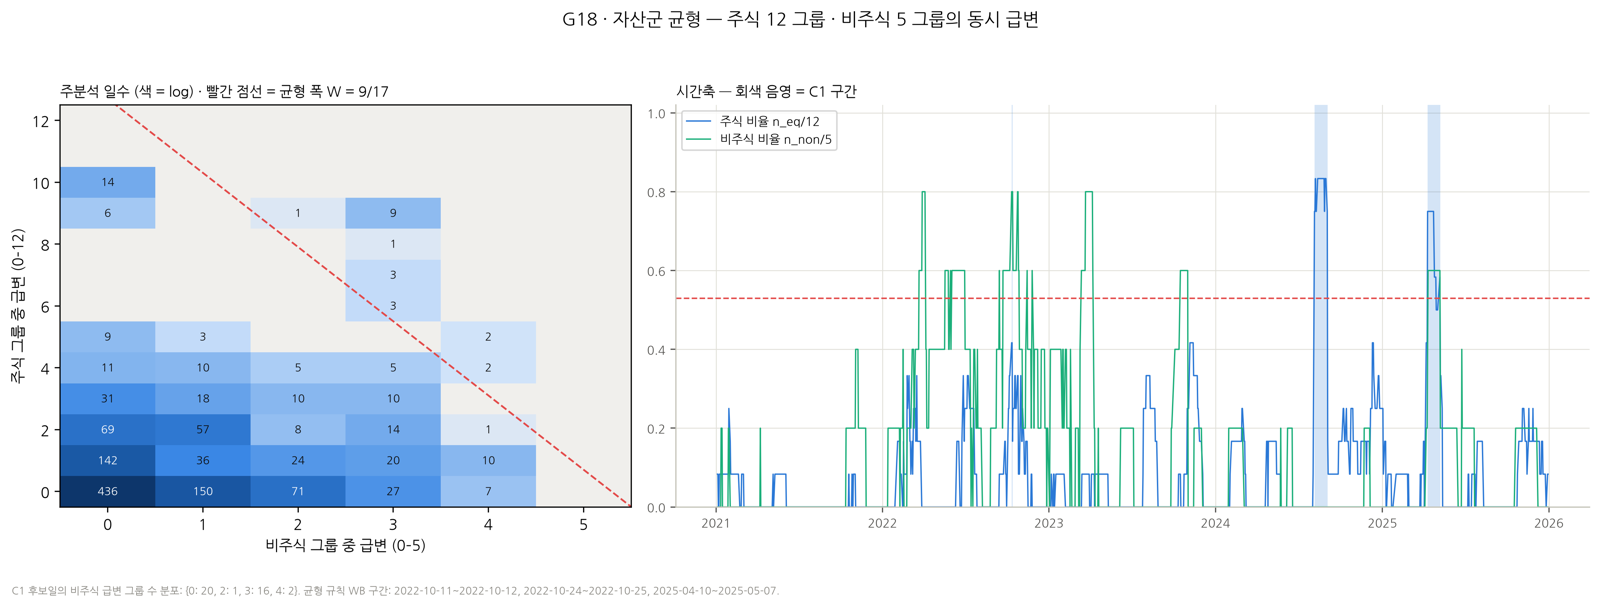

{"c1_days_by_n_non": {"0": 20, "2": 1, "3": 16, "4": 2}, "wb": ["2022-10-11~2022-10-12", "2022-10-24~2022-10-25", "2025-04-10~2025-05-07"]}


In [25]:
CAP["G18_asset_class_balance"] = FG.g18_balance()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G18_asset_class_balance.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G18_asset_class_balance"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

**해석 (D2).**
- C1 후보일 39일 중 **20일은 비주식 급변이 0개**다. 모두 2024-08 구간이다 (주식 9–10개만 급변).
- 나머지 19일은 비주식이 2–4개 함께 급변했다 (2022-10 의 2일, 2025-04 의 17일).
- 균형 규칙 WB 로 바꾸면 **2024-08 이 사라지고**, 2022-10-11~12 · 2022-10-24~25 (C1 에 없던 N_A 8 의 날) · 2025-04-10~05-07 이 남는다.
- 즉 "과반" 기준은 주식 충격을, "균형" 기준은 다자산 충격을 고른다. 어떤 시장 상태를 급변이라 부를지에 따라 고를 기준이 갈린다.

## D3. 이력(히스테리시스) 구간 — 하루 미달로 쪼개지지 않게

In [26]:
# H1 (9 진입·7 유지) vs C1, H2 (10 진입·8 유지) vs C2.
display(X["hysteresis"])  # 이력 구간

,rule,interval_id,start,end,duration,max_n_A,min_n_A,i0,i1
0,H1,H1_001,2022-10-11,2022-10-12,2,9,9,930,931
1,H1,H1_002,2024-08-05,2024-09-02,20,10,9,1379,1398
2,H1,H1_003,2025-04-10,2025-05-07,17,12,9,1542,1558
3,H2,H2_001,2024-08-07,2024-09-02,18,10,9,1381,1398
4,H2,H2_002,2025-04-10,2025-05-07,17,12,9,1542,1558


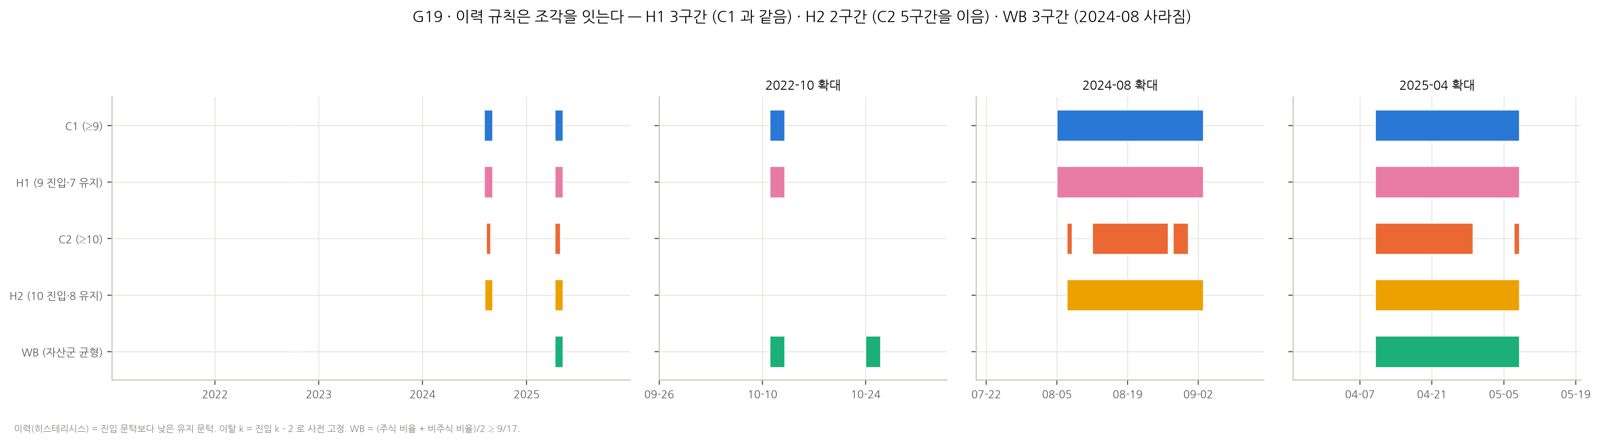

{"H1": 3, "H2": 2, "WB": 3}


In [27]:
CAP["G19_hysteresis_balance_intervals"] = FG.g19_hysteresis()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G19_hysteresis_balance_intervals.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G19_hysteresis_balance_intervals"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

**해석 (D3).**
- **H1 = C1**: C1 의 세 구간은 안에서 N_A 가 9 아래로 내려간 적이 없으므로 그대로다.
- **H2 는 C2 의 5조각을 2구간으로 잇는다**: 2024-08-07~09-02 (18일), 2025-04-10~05-07 (17일). 사건 하나가 구간 하나가 되고, C1 과 비교하면 2022-10 과 2024-08-05~06 만 빠진다.
- 갭 병합처럼 임의의 '며칠 공백 허용' 을 두지 않고도 조각남을 해결한다. 정의를 고를 때 C2 를 원한다면 H2 형태가 낫다.

## D4. 연속 강도 지수 — 몇 개가 아니라 얼마나

In [28]:
# I(t) = Σ_g max(σ_g/경계_g − 1, 0). N_A 와의 순위상관, 상위 5 정점, C1 정점일의 자산군 구성.
print("Spearman(I, N_A) =", round(X["rho_I_NA"], 3))  # 순위상관
display(X["intensity_peaks"])  # 정점 (20거래일 이상 떨어진 날)
display(X["c1_intensity_peak"].round(3))  # C1 구간 정점 분해

Spearman(I, N_A) = 0.914


,date,I,n_A_q20,C1,top3,n_groups_positive
0,2022-10-24,2.377051,8,False,153130 KODEX 단기채권 1.12; 148070 KIWOOM 국고채10년 0.72; 261240 KODEX 미국달러선물 0.17,8
1,2023-11-15,2.453690,5,False,305540 TIGER 2차전지테마 1.29; 229200 KODEX 코스닥150 0.73; 117680 KODEX 철강 0.22,5
2,2024-02-20,7.529277,3,False,153130 KODEX 단기채권 7.20; 161510 PLUS 고배당주 0.20; 091170 KODEX 은행 0.14,3
3,2024-08-19,3.511217,10,True,KOSPI200 동일노출(Core Pair) 0.83; 091230 TIGER 반도체 0.74; 229200 KODEX 코스닥150 0.41,10
4,2025-04-25,4.726893,10,True,219480 KODEX 미국S&P500선물(H) 1.19; 133690 TIGER 미국나스닥100 1.16; 132030 KODEX 골드선물(H) 0.48,10


,interval_id,peak_date,I,equity_share,top3
0,q20_k9_PRI_001,2022-10-11,2.307,0.157,153130 KODEX 단기채권 1.39; 148070 KIWOOM 국고채10년 0.29; 261240 KODEX 미국달러선물 0.22
1,q20_k9_PRI_002,2024-08-19,3.511,1.000,KOSPI200 동일노출(Core Pair) 0.83; 091230 TIGER 반도체 0.74; 229200 KODEX 코스닥150 0.41
2,q20_k9_PRI_003,2025-04-25,4.727,0.801,219480 KODEX 미국S&P500선물(H) 1.19; 133690 TIGER 미국나스닥100 1.16; 132030 KODEX 골드선물(H) 0.48


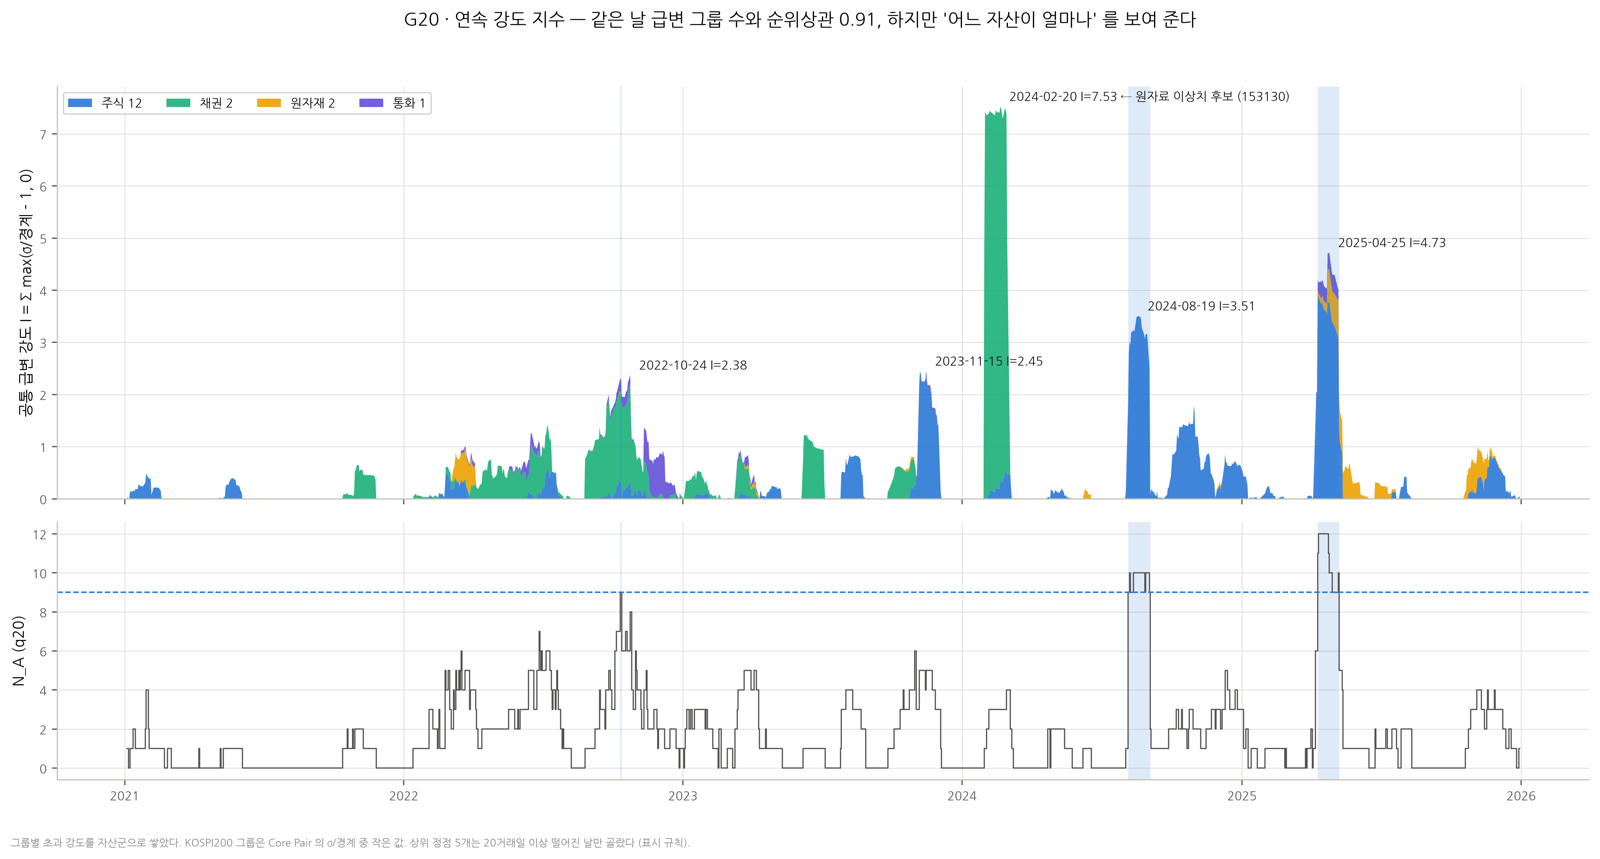

{"rho": 0.914}


In [29]:
CAP["G20_intensity_index"] = FG.g20_intensity()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G20_intensity_index.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G20_intensity_index"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

**해석 (D4).**
- I 와 N_A 의 순위상관은 0.91 이다. 대체로 같은 날을 가리키지만, I 는 **어느 자산이 얼마나** 초과했는지를 보여 준다.
- C1 정점일의 강도 중 주식 몫: **2022-10-11 16%** (단기채·국채·달러 주도), **2024-08-19 100%**, **2025-04-25 80%** (미국 주식·금 포함).
- C1 밖의 고강도 날도 있다. 2022-10-24 (N_A 8, 채권 주도), 2023-11-15 (2차전지·코스닥).
- **주의**: 가장 높은 정점 2024-02-20 (I = 7.53) 은 단기채권 153130 하나(7.20)가 만들었다. 09·11 에서 기록한 **원자료 이상치 후보**(2024-01-30·31)의 흔적이다. σ/경계 비율은 위로 제한이 없어 한 그룹의 이상값에 민감하다. 이 지수로 구간을 정의하려면 그룹별 상한(예: 비율 2배에서 자르기)을 먼저 정해야 한다.

## D5. 20일 → 60일 시차

In [30]:
# corr(N_A20(t), N_A60(t+L)), L = 0..120 거래일.
LL = X["lead_lag"]  # 시차 곡선
display(LL.loc[[0, 10, 20, 33, 40, 60, 90]].round(3))  # 주요 시차

,lag,corr
0,0,0.375
10,10,0.439
20,20,0.508
33,33,0.565
40,40,0.528
60,60,0.010
90,90,0.110


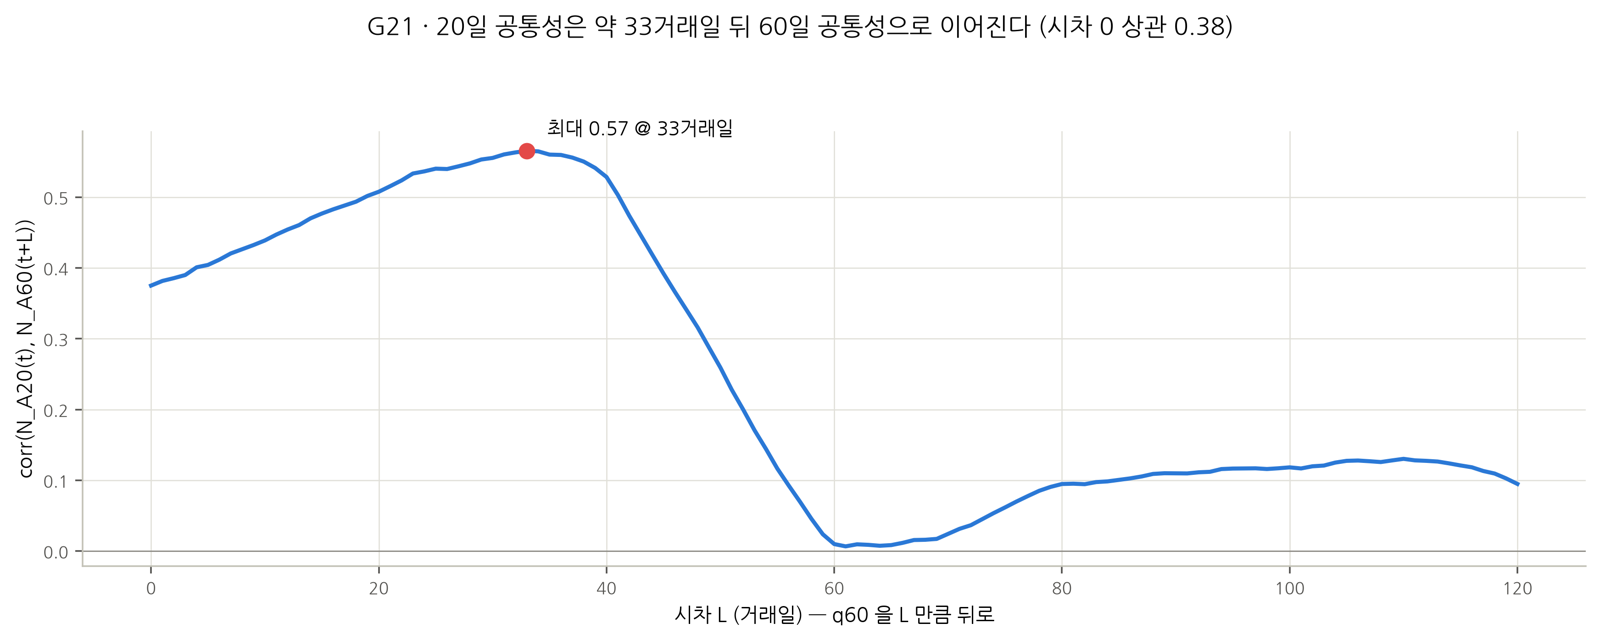

{"lag": 33, "corr": 0.565}


In [31]:
CAP["G21_q20_q60_lead_lag"] = FG.g21_leadlag()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G21_q20_q60_lead_lag.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G21_q20_q60_lead_lag"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

**해석 (D5).**
- 같은 날(시차 0)의 상관은 0.38 이지만, 60일 쪽을 **33거래일** 뒤로 밀면 0.57 로 가장 높다.
- §11 에서 "겹침 0" 으로 보였던 20일과 60일 기준은 **같은 사건의 앞과 뒤**다. 사례에서도 정점 간격이 6주(2022)–2.5개월(2024)이었다.
- 따라서 60일 기준은 C1 과 경쟁하는 정의가 아니다. C1 구간 뒤 약 한 달 반의 '누적 국면' 을 표시하는 **후속 라벨**로 쓰는 편이 자연스럽다. 다만 D1 에서 보았듯 60일 공통성 자체는 우연과 구별이 약하다.

## D6. C1 구간 바텀업 — 누가 먼저 들어왔고 왜 끝났나

In [32]:
# 그룹별 진입일(그 그룹 A20 연속 구간의 시작)과 종료 다음 날 빠진 그룹의 20일 창 최대 기여일·창 이탈 여부.
display(X["c1_entry"].sort_values(["interval_id", "entry_date"]))  # 진입 순서
display(X["c1_exit"])  # 종료 원인

,interval_id,group,label,entry_date,entry_offset_vs_interval,days_in_interval
6,q20_k9_PRI_001,153130,153130 KODEX 단기채권,2022-08-26,-28,2
5,q20_k9_PRI_001,148070,148070 KIWOOM 국고채10년,2022-09-22,-11,2
8,q20_k9_PRI_001,261240,261240 KODEX 미국달러선물,2022-09-22,-11,2
1,q20_k9_PRI_001,091230,091230 TIGER 반도체,2022-10-04,-4,2
3,q20_k9_PRI_001,117680,117680 KODEX 철강,2022-10-04,-4,2
4,q20_k9_PRI_001,219480,219480 KODEX 미국S&P500선물(H),2022-10-04,-4,2
2,q20_k9_PRI_001,305540,305540 TIGER 2차전지테마,2022-10-06,-2,2
0,q20_k9_PRI_001,229200,229200 KODEX 코스닥150,2022-10-11,0,2
7,q20_k9_PRI_001,132030,132030 KODEX 골드선물(H),2022-10-11,0,2
11,q20_k9_PRI_002,091230,091230 TIGER 반도체,2024-08-02,-1,20


,interval_id,group,label,exit_date,top_day,top_r,top_share,window_exit
0,q20_k9_PRI_001,229200,229200 KODEX 코스닥150,2022-10-13,2022-10-04,3.708167,0.183865,False
1,q20_k9_PRI_001,117680,117680 KODEX 철강,2022-10-13,2022-09-26,-5.989636,0.302369,False
2,q20_k9_PRI_001,219480,219480 KODEX 미국S&P500선물(H),2022-10-13,2022-09-14,-4.740027,0.230544,False
3,q20_k9_PRI_002,KOSPI200_동일노출,KOSPI200 동일노출(Core Pair),2024-09-03,2024-08-05,-9.627052,0.765269,True
4,q20_k9_PRI_002,229200,229200 KODEX 코스닥150,2024-09-03,2024-08-05,-11.145375,0.639776,True
5,q20_k9_PRI_002,091170,091170 KODEX 은행,2024-09-03,2024-08-05,-8.023420,0.637306,True
6,q20_k9_PRI_002,091180,091180 KODEX 자동차,2024-09-03,2024-08-05,-9.219312,0.625363,True
7,q20_k9_PRI_002,117680,117680 KODEX 철강,2024-09-03,2024-08-05,-9.755774,0.718978,True
8,q20_k9_PRI_002,161510,161510 PLUS 고배당주,2024-09-03,2024-08-05,-6.290434,0.630608,True
9,q20_k9_PRI_002,133690,133690 TIGER 미국나스닥100,2024-09-03,2024-08-05,-6.741161,0.460087,True


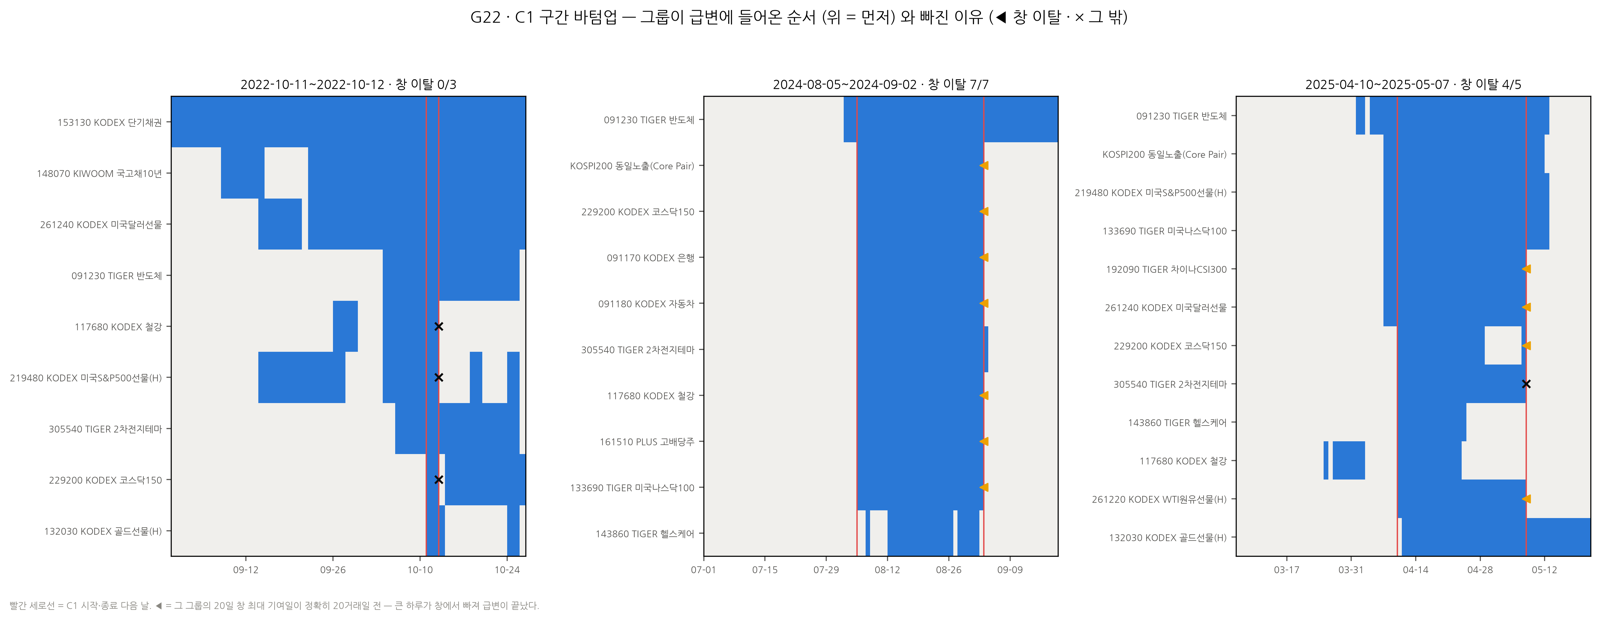

{"q20_k9_PRI_001": {"exit_groups": 3, "window_exit": 0}, "q20_k9_PRI_002": {"exit_groups": 7, "window_exit": 7}, "q20_k9_PRI_003": {"exit_groups": 5, "window_exit": 4}}


In [33]:
CAP["G22_c1_bottomup"] = FG.g22_c1_bottomup()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G22_c1_bottomup.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G22_c1_bottomup"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

**해석 (D6).**
- **2022-10**: 단기채권(08-26) → 국고채·달러(09-22) → 반도체·철강·미국 S&P500(10-04) → 2차전지(10-06) → 코스닥·금(10-11) 순서로 들어왔다. **금리·달러 충격이 주식으로 번진** 모양이다. 종료는 창 이탈이 아니다 (빠진 3개 그룹 모두 다른 이유).
- **2024-08**: 10개 그룹 중 8개가 08-05 하루에 함께 들어왔다 (반도체 08-02, 헬스케어 08-07). 종료일(09-03)에 빠진 7개 그룹은 **모두 08-05 가 20일 창에서 빠진 날** 빠졌다. 이 구간의 20일은 그 하루가 창에 머문 기간이다.
- **2025-04**: KOSPI200·미국 주식 2종·중국·달러가 04-07 에 먼저 들어오고, 국내 업종·원유가 04-10 에 합류해 C1 이 시작됐다. 종료일(05-08)에 빠진 5개 그룹 중 4개가 04-07 의 창 이탈이다.
- 결론: C1 의 **시작은 사건의 확산 순서**를, **끝은 상당 부분 20일 창의 기계적 종료**를 반영한다. 구간을 CNN 표본으로 자를 때 끝 부분 며칠은 '충격 후 잔향' 일 수 있다.

## 12. 2022년 사례 심층 분석 (E1 — 채권 중심 고변동성)

사례 창 2022-01-03~12-29 (09 와 같은 창). 비교 기준: W2 HIGH_LEVEL 2022-09-07~12-07, 09 q20 A 최대 9/17 (2022-10-11).

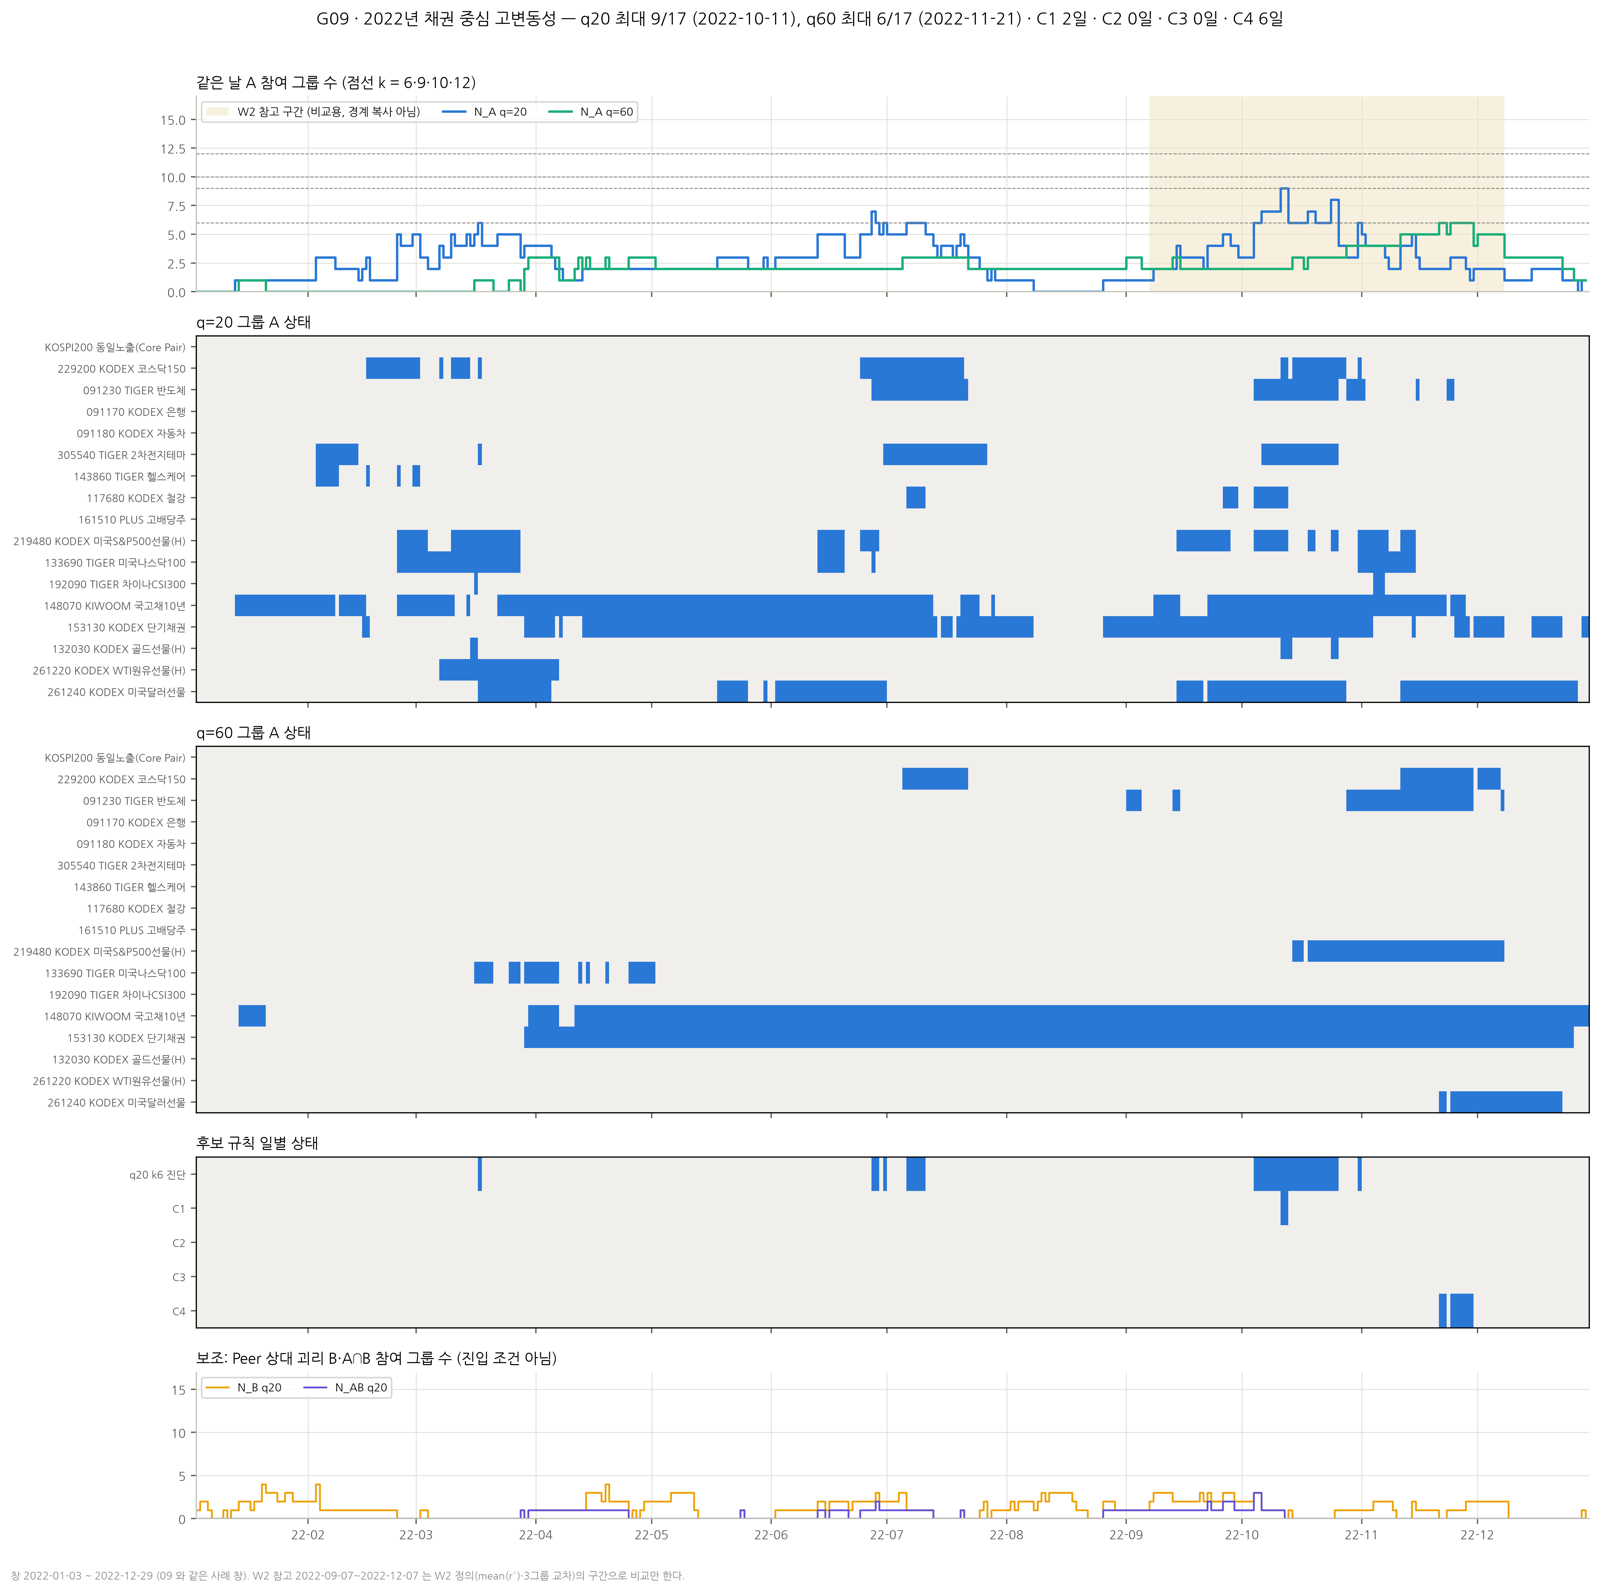

{"C1": {"days": 2, "intervals": "2022-10-11~2022-10-12 (2일, 최대 9)"}, "C2": {"days": 0, "intervals": ""}, "C3": {"days": 0, "intervals": ""}, "C4": {"days": 6, "intervals": "2022-11-21~2022-11-22 (2일, 최대 6); 2022-11-24~2022-11-29 (4일, 최대 6)"}, "max_q20": 9, "max_q20_date": "2022-10-11", "max_q60": 6, "max_q60_date": "2022-11-21"}


In [34]:
CAP["G09_event_E1_2022_bond"] = FG.g_event("E1_2022_bond", "09")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G09_event_E1_2022_bond.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G09_event_E1_2022_bond"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

In [35]:
# E1 창 안의 규칙별 결과와 C1 후보일의 일별 상태.
EVT = R["events"]  # 사례 × 규칙
display(EVT[(EVT["event"] == "E1_2022_bond") & EVT["rule"].isin(["q20_k3", "q20_k6", "q20_k9", "q20_k10", "q20_k12", "q60_k3", "q60_k6"])][["rule", "candidate", "candidate_days", "candidate_days_in_w2_ref", "w2_ref_days", "n_intervals", "intervals", "window_max_n_A", "window_max_first_date"]])  # 규칙별
display(R["event_days"][R["event_days"]["event"] == "E1_2022_bond"])  # C1 후보일

,rule,candidate,candidate_days,candidate_days_in_w2_ref,w2_ref_days,n_intervals,intervals,window_max_n_A,window_max_first_date
0,q20_k3,,114,41,62,11,"2022-02-03~2022-02-07 (3일, 최대 3); 2022-02-16~2022-02-16 (1일, 최대 3); 2022-02-24~2022-03-03 (5일, 최대 5); 2022-03-07~2022-04-05 (21일, 최대 6);...",9,2022-10-11
1,q20_k6,,23,16,62,6,"2022-03-17~2022-03-17 (1일, 최대 6); 2022-06-27~2022-06-28 (2일, 최대 7); 2022-06-30~2022-06-30 (1일, 최대 6); 2022-07-06~2022-07-08 (3일, 최대 6); ...",9,2022-10-11
2,q20_k9,C1,2,2,62,1,"2022-10-11~2022-10-12 (2일, 최대 9)",9,2022-10-11
3,q20_k10,C2,0,0,62,0,,9,2022-10-11
4,q20_k12,C3,0,0,62,0,,9,2022-10-11
6,q60_k3,,80,40,62,10,"2022-03-30~2022-04-06 (6일, 최대 3); 2022-04-12~2022-04-12 (1일, 최대 3); 2022-04-14~2022-04-14 (1일, 최대 3); 2022-04-19~2022-04-19 (1일, 최대 3); ...",6,2022-11-21
7,q60_k6,C4,6,6,62,2,"2022-11-21~2022-11-22 (2일, 최대 6); 2022-11-24~2022-11-29 (4일, 최대 6)",6,2022-11-21


,event,date,n_A_q20,n_A_q60,in_C2,in_C3,in_C4,n_B_q20,n_AB_q20
0,E1_2022_bond,2022-10-11,9,2,False,False,False,1,1
1,E1_2022_bond,2022-10-12,9,2,False,False,False,0,0


**해석 (E1).**
- **C1 에서 실제 연속 구간**: 2022-10-11~10-12, 단 2거래일 (N_A 9). 참여 그룹은 코스닥150·반도체·2차전지·철강·미국 S&P500·국고채10년·단기채권·금·달러다. 주식·채권·원자재·통화가 함께 켜진 날이다.
- **C2 에서 사라지는 날짜**: 이 2일이 전부 사라진다. 2022년의 최대가 9 이므로 C2·C3 는 2022년에 0일이다.
- **q60 에서는 다르게 남는다**: C4 는 2022-11-21~22, 11-24~29 (6일, N_A 6)를 잡는다. q20 정점보다 약 6주 늦다. 구성은 코스닥150·반도체·미국 S&P500·국고채10년·단기채권·달러다. 11-23 하루가 5/17 이라 두 구간으로 나뉜다.
- W2 참고 구간(62거래일) 중 C1 은 2일, C4 는 6일만 포함한다. 2022년의 고변동성은 **오래 지속됐지만 동시 참여 폭은 좁았다**. 채권·달러가 긴 띠를 만드는 동안 주식 그룹은 짧게 들어왔다 나갔다.
- 해석: 2022는 '과반 동시' 기준으로는 거의 보이지 않는다. '중기 누적' 기준(C4)이나 완화 기준(k=6, 23일)으로 보인다. 어떤 정의를 고르느냐에 따라 2022년을 급변기로 볼지가 갈린다.

## 13. 2024년 8월 사례 심층 분석 (E2 — 다자산 변동성 확대)

사례 창 2024-07-01~09-30. 비교 기준: W2 EXPANSION 2024-08-02~09-02.

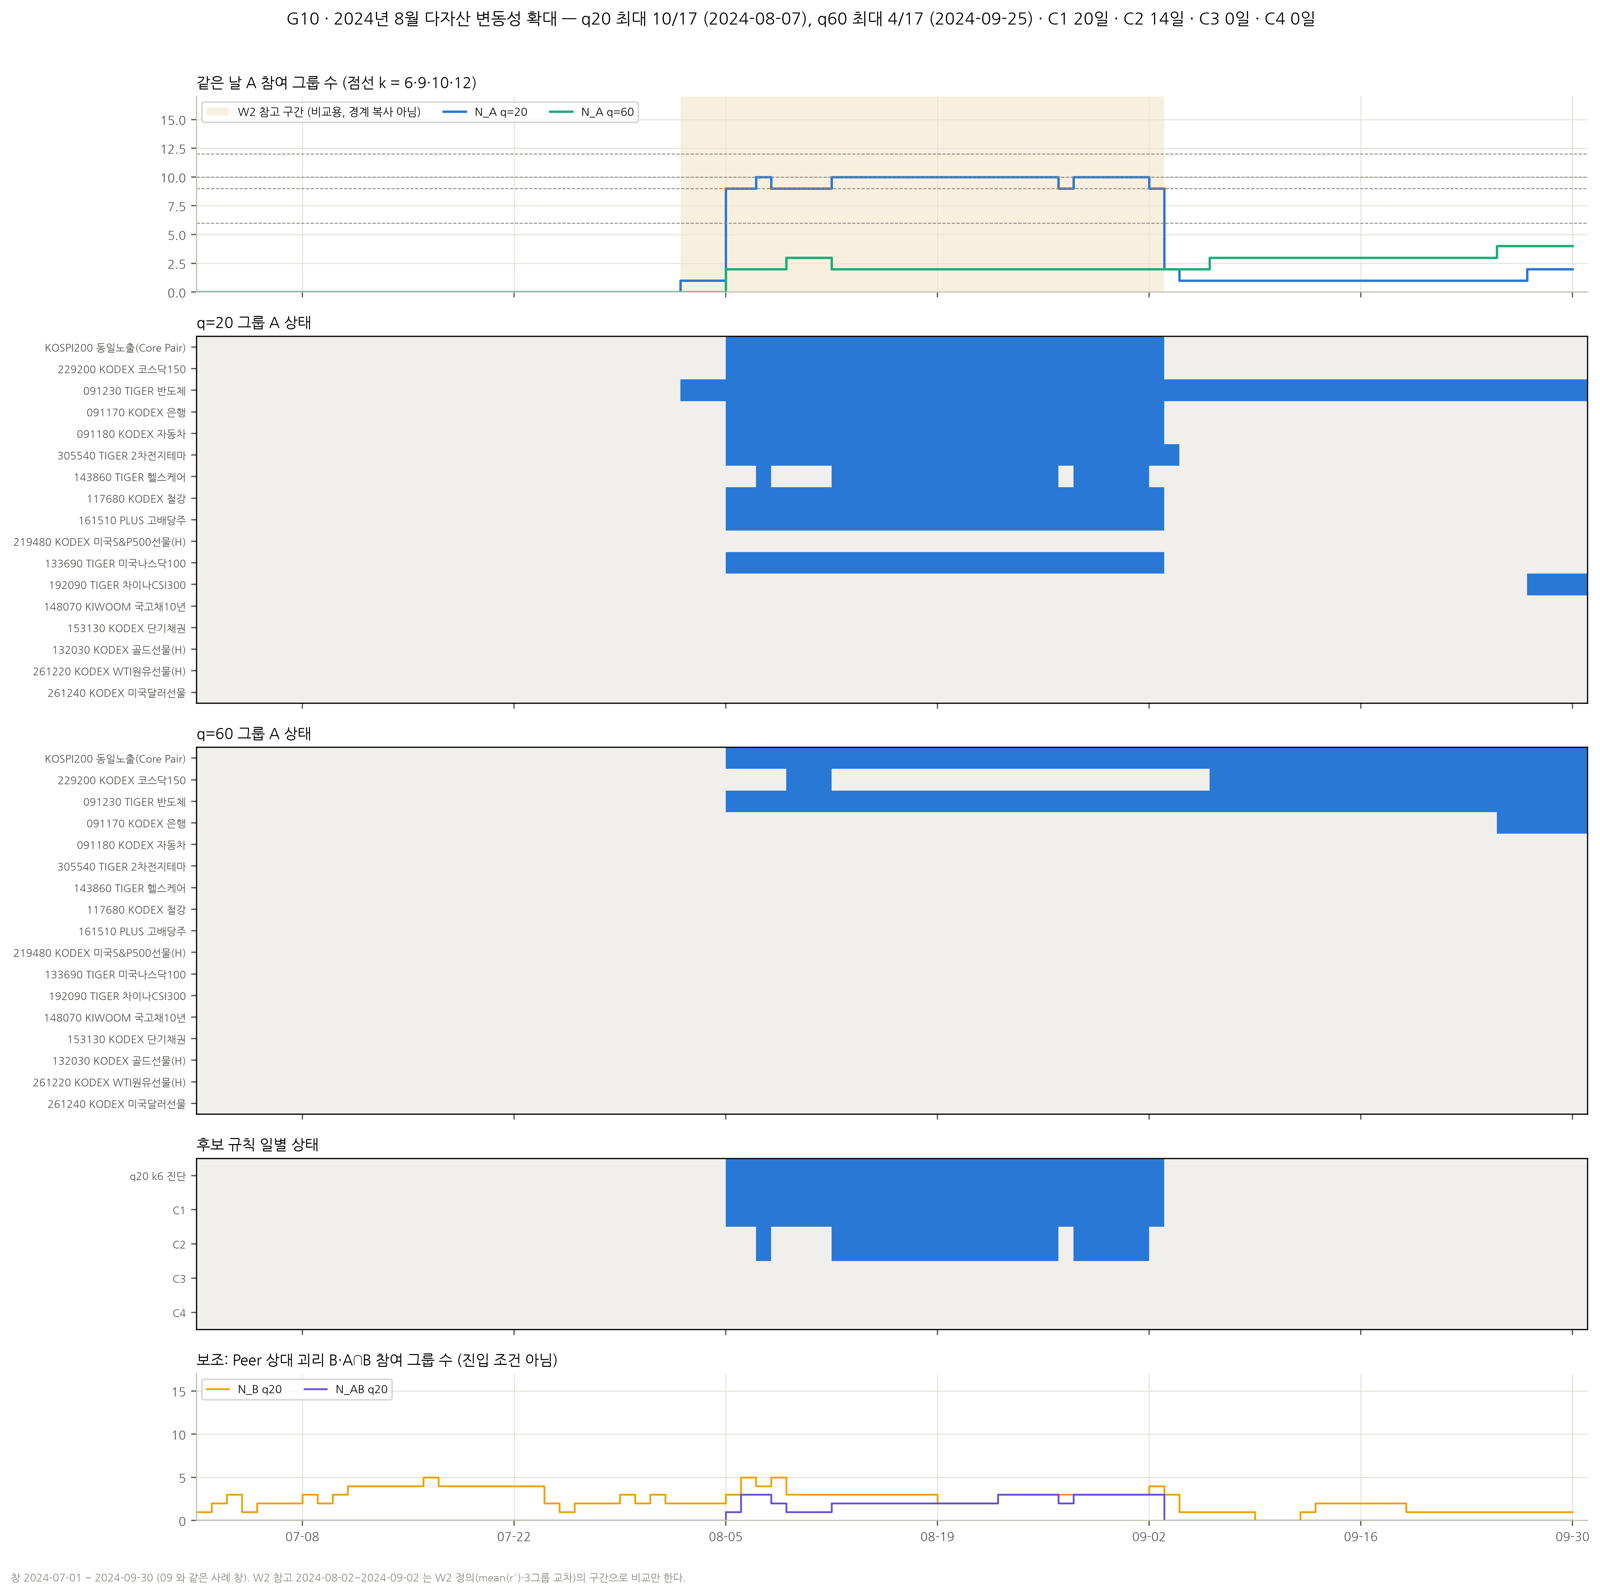

{"C1": {"days": 20, "intervals": "2024-08-05~2024-09-02 (20일, 최대 10)"}, "C2": {"days": 14, "intervals": "2024-08-07~2024-08-07 (1일, 최대 10); 2024-08-12~2024-08-26 (10일, 최대 10); 2024-08-28~2024-08-30 (3일, 최대 10)"}, "C3": {"days": 0, "intervals": ""}, "C4": {"days": 0, "intervals": ""}, "max_q20": 10, "max_q20_date": "2024-08-07", "max_q60": 4, "max_q60_date": "2024-09-25"}


In [36]:
CAP["G10_event_E2_2024_08"] = FG.g_event("E2_2024_08", "10")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G10_event_E2_2024_08.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G10_event_E2_2024_08"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

In [37]:
# E2 창 안의 규칙별 결과와 C1 후보일별 N_A·C2 포함 여부 (분할 원인 확인).
display(EVT[(EVT["event"] == "E2_2024_08") & EVT["rule"].isin(["q20_k6", "q20_k9", "q20_k10", "q20_k12", "q60_k3", "q60_k6"])][["rule", "candidate", "candidate_days", "n_intervals", "intervals", "window_max_n_A", "window_max_first_date"]])  # 규칙별
display(R["event_days"][R["event_days"]["event"] == "E2_2024_08"])  # C1 후보일

,rule,candidate,candidate_days,n_intervals,intervals,window_max_n_A,window_max_first_date
13,q20_k6,,20,1,"2024-08-05~2024-09-02 (20일, 최대 10)",10,2024-08-07
14,q20_k9,C1,20,1,"2024-08-05~2024-09-02 (20일, 최대 10)",10,2024-08-07
15,q20_k10,C2,14,3,"2024-08-07~2024-08-07 (1일, 최대 10); 2024-08-12~2024-08-26 (10일, 최대 10); 2024-08-28~2024-08-30 (3일, 최대 10)",10,2024-08-07
16,q20_k12,C3,0,0,,10,2024-08-07
18,q60_k3,,15,2,"2024-08-09~2024-08-09 (1일, 최대 3); 2024-09-06~2024-11-28 (54일, 최대 6)",4,2024-09-25
19,q60_k6,C4,0,0,,4,2024-09-25


,event,date,n_A_q20,n_A_q60,in_C2,in_C3,in_C4,n_B_q20,n_AB_q20
2,E2_2024_08,2024-08-05,9,2,False,False,False,3,1
3,E2_2024_08,2024-08-06,9,2,False,False,False,5,3
4,E2_2024_08,2024-08-07,10,2,True,False,False,4,3
5,E2_2024_08,2024-08-08,9,2,False,False,False,5,2
6,E2_2024_08,2024-08-09,9,3,False,False,False,3,1
7,E2_2024_08,2024-08-12,10,2,True,False,False,3,2
8,E2_2024_08,2024-08-13,10,2,True,False,False,3,2
9,E2_2024_08,2024-08-14,10,2,True,False,False,3,2
10,E2_2024_08,2024-08-16,10,2,True,False,False,3,2
11,E2_2024_08,2024-08-19,10,2,True,False,False,2,2


**해석 (E2).**
- **C1**: 2024-08-05~09-02, 20거래일 연속. 동시 최대 10 (첫 도달 08-07). k=6 과 k=9 의 구간이 똑같다. 08-05 에 N_A 가 1 에서 9 로 한꺼번에 뛰었다는 뜻이다.
- **참여 구성**: KOSPI200·코스닥150·반도체·은행·자동차·2차전지·헬스케어·철강·고배당·미국 나스닥100 의 10개 그룹. 국고채·단기채·금·원유·달러·중국·미국 S&P500선물은 한 번도 참여하지 않았다. **국내 주식 중심의 동시 급변**이다.
- **C2**: N_A 가 9 와 10 을 오가며 3조각(1·10·3일)이 된다. 같은 사건이 C2 로는 세 개의 사건처럼 보인다.
- **C3**: 0일 (사건 최대 10 < 12).
- **q60**: 창 안 최대 4/17 (09-25). C4 는 이 사건 안에서 0일이다. 대신 2024-10-24~11-04 에 C4 구간(8일)이 나온다. 구성은 KOSPI200·코스닥150·반도체·은행·철강·중국 CSI300 이다. 8월 충격 뒤 남은 국내 주식 고변동성과 중국 변동성의 누적으로 읽힌다.
- 외부 맥락(이 데이터로 원인을 검증하지 않음): 2024-08-05 전후 글로벌 주식 급락·엔 캐리 청산 시기와 겹친다.

## 14. 2025년 4월 사례 심층 분석 (E3 — 다자산 변동성 확대)

사례 창 2025-03-17~06-13. 비교 기준: W2 HIGH_LEVEL 2025-04-07~05-26.

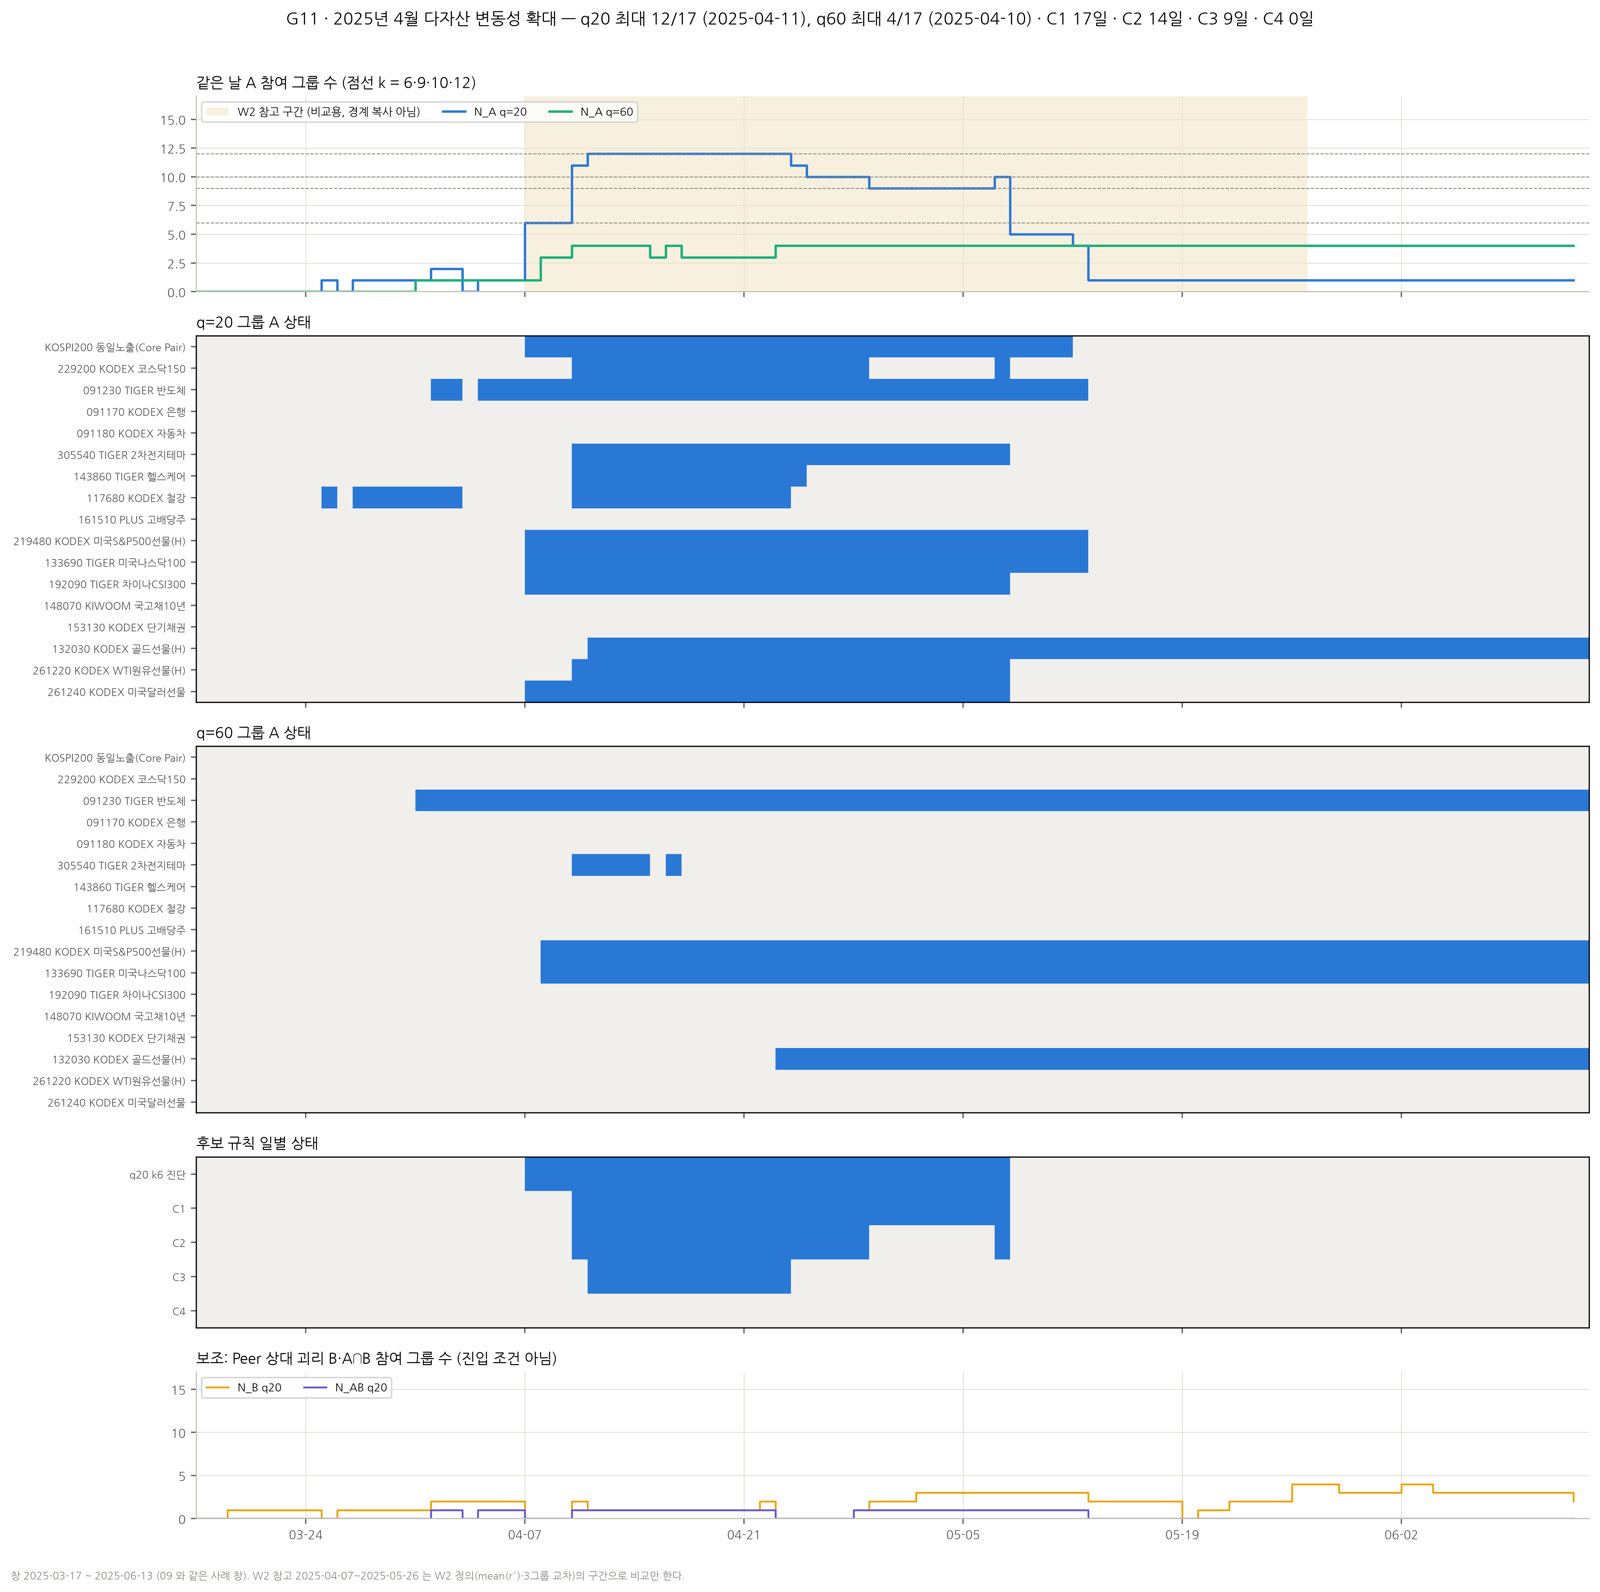

{"C1": {"days": 17, "intervals": "2025-04-10~2025-05-07 (17일, 최대 12)"}, "C2": {"days": 14, "intervals": "2025-04-10~2025-04-28 (13일, 최대 12); 2025-05-07~2025-05-07 (1일, 최대 10)"}, "C3": {"days": 9, "intervals": "2025-04-11~2025-04-23 (9일, 최대 12)"}, "C4": {"days": 0, "intervals": ""}, "max_q20": 12, "max_q20_date": "2025-04-11", "max_q60": 4, "max_q60_date": "2025-04-10"}


In [38]:
CAP["G11_event_E3_2025_04"] = FG.g_event("E3_2025_04", "11")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G11_event_E3_2025_04.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G11_event_E3_2025_04"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

In [39]:
# E3 창 안의 규칙별 결과와 C1 후보일별 상태.
display(EVT[(EVT["event"] == "E3_2025_04") & EVT["rule"].isin(["q20_k6", "q20_k9", "q20_k10", "q20_k12", "q60_k3", "q60_k6"])][["rule", "candidate", "candidate_days", "n_intervals", "intervals", "window_max_n_A", "window_max_first_date"]])  # 규칙별
display(R["event_days"][R["event_days"]["event"] == "E3_2025_04"])  # C1 후보일

,rule,candidate,candidate_days,n_intervals,intervals,window_max_n_A,window_max_first_date
25,q20_k6,,20,1,"2025-04-07~2025-05-07 (20일, 최대 12)",12,2025-04-11
26,q20_k9,C1,17,1,"2025-04-10~2025-05-07 (17일, 최대 12)",12,2025-04-11
27,q20_k10,C2,14,2,"2025-04-10~2025-04-28 (13일, 최대 12); 2025-05-07~2025-05-07 (1일, 최대 10)",12,2025-04-11
28,q20_k12,C3,9,1,"2025-04-11~2025-04-23 (9일, 최대 12)",12,2025-04-11
30,q60_k3,,44,1,"2025-04-08~2025-07-04 (59일, 최대 4)",4,2025-04-10
31,q60_k6,C4,0,0,,4,2025-04-10


,event,date,n_A_q20,n_A_q60,in_C2,in_C3,in_C4,n_B_q20,n_AB_q20
22,E3_2025_04,2025-04-10,11,4,True,False,False,2,1
23,E3_2025_04,2025-04-11,12,4,True,True,False,1,1
24,E3_2025_04,2025-04-14,12,4,True,True,False,1,1
25,E3_2025_04,2025-04-15,12,3,True,True,False,1,1
26,E3_2025_04,2025-04-16,12,4,True,True,False,1,1
27,E3_2025_04,2025-04-17,12,3,True,True,False,1,1
28,E3_2025_04,2025-04-18,12,3,True,True,False,1,1
29,E3_2025_04,2025-04-21,12,3,True,True,False,1,1
30,E3_2025_04,2025-04-22,12,3,True,True,False,2,1
31,E3_2025_04,2025-04-23,12,4,True,True,False,0,0


**해석 (E3).**
- **C1**: 2025-04-10~05-07, 17거래일. 동시 최대 12 (04-11~04-23 의 9일 내내).
- **C3**: 2025-04-11~04-23 (9일). 2021–2025 에서 C3 가 남는 유일한 사건이다.
- **참여 구성 (최대일 12개)**: KOSPI200·코스닥150·반도체·2차전지·헬스케어·철강·미국 S&P500·미국 나스닥100·중국 CSI300·금·원유·달러. 은행·자동차·고배당·국고채10년·단기채권은 참여하지 않았다. 2024-08 과 달리 **해외 주식·원자재·통화까지 퍼진 다자산 급변**이다.
- **C2**: 04-10~04-28 (13일) 과 05-07 (1일) 로 나뉜다. 04-29·30, 05-02 에 N_A 가 9 로 내려갔기 때문이다.
- **q60**: 창 안 최대 4/17. C4 는 0일이다. 60일 창에서는 이 충격이 6개 그룹의 동시 고변동성까지 쌓이지 않았다.
- 외부 맥락(검증하지 않음): 2025-04 초 미국 관세 발표 이후의 글로벌 변동성 확대 시기와 겹친다.

## 15. 후보 구간 내부 참여 그룹 분석

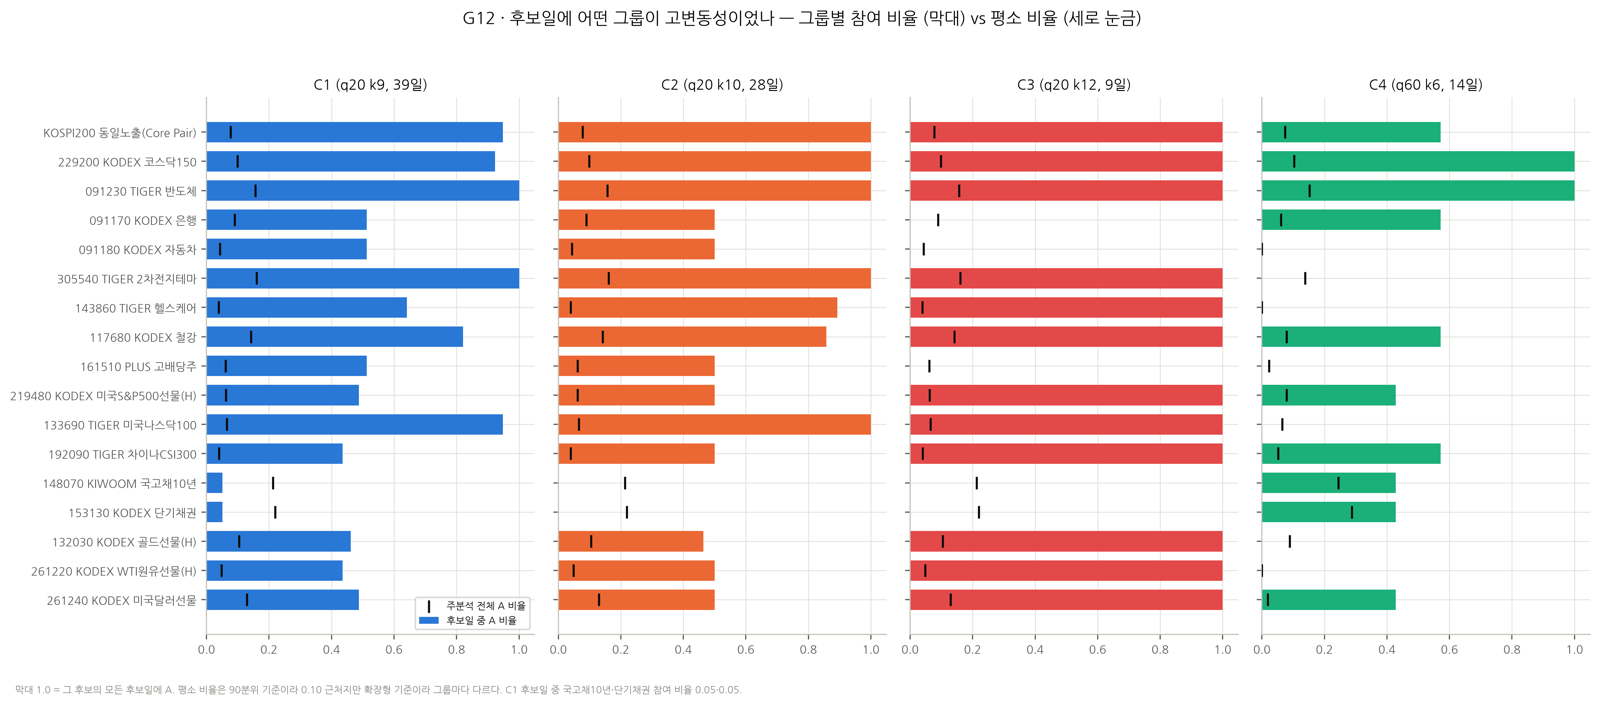

{"C1": {"KOSPI200_동일노출": 0.949, "229200": 0.923, "091230": 1.0, "091170": 0.513, "091180": 0.513, "305540": 1.0, "143860": 0.641, "117680": 0.821, "161510": 0.513, "219480": 0.487, "133690": 0.949, "192090": 0.436, "148070": 0.051, "153130": 0.051, "132030": 0.462, "261220": 0.436, "261240": 0.487}, "C2": {"KOSPI200_동일노출": 1.0, "229200": 1.0, "091230": 1.0, "091170": 0.5, "091180": 0.5, "305540": 1.0, "143860": 0.893, "117680": 0.857, "161510": 0.5, "219480": 0.5, "133690": 1.0, "192090": 0.5, "148070": 0.0, "153130": 0.0, "132030": 0.464, "261220": 0.5, "261240": 0.5}, "C3": {"KOSPI200_동일노출": 1.0, "229200": 1.0, "091230": 1.0, "091170": 0.0, "091180": 0.0, "305540": 1.0, "143860": 1.0, "117


In [40]:
CAP["G12_group_participation"] = FG.g12_participation()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G12_group_participation.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G12_group_participation"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

In [41]:
# 주 후보별 그룹 참여 비율 표 (후보일 중 A 인 비율 vs 주분석 전체 A 비율).
PT = R["participation"]  # 참여 표
display(PT.pivot(index="label", columns="candidate", values="share_on_candidate_days").reindex([R["states"]["label"][g] for g in R["states"]["groups"]]).round(2))  # 그룹 × 후보

candidate,C1,C2,C3,C4
label,,,,
KOSPI200 동일노출(Core Pair),0.95,1.00,1.0,0.57
229200 KODEX 코스닥150,0.92,1.00,1.0,1.00
091230 TIGER 반도체,1.00,1.00,1.0,1.00
091170 KODEX 은행,0.51,0.50,0.0,0.57
091180 KODEX 자동차,0.51,0.50,0.0,0.00
305540 TIGER 2차전지테마,1.00,1.00,1.0,0.00
143860 TIGER 헬스케어,0.64,0.89,1.0,0.00
117680 KODEX 철강,0.82,0.86,1.0,0.57
161510 PLUS 고배당주,0.51,0.50,0.0,0.00


**해석 (G12).**
- C1 후보일 39일 동안 반도체(091230)·2차전지(305540)는 100%, KOSPI200·나스닥100 은 95%, 코스닥150 은 92% 참여했다. **C1 의 공통성은 주식 그룹이 이끈다**.
- 국고채10년·단기채권은 C1 후보일의 5% (2022-10 의 2일)에만 참여한다. 채권 고변동성은 C1 정의에서 거의 드러나지 않는다.
- C4 는 구성이 다르다. 2022-11 (채권·달러·미국 주식) 과 2024-10~11 (국내 주식·중국) 두 묶음이 번갈아 나온다.
- 함의: 17개 그룹 중 **주식 계열이 12개**(국내 9 · 해외 3)이고, 채권 2 · 원자재 2 · 통화 1 의 **비주식은 5개**뿐이다 (W2 `exposure_groups.csv` 범주 기준). 주식 충격만으로도 과반(9/17) 기준을 넘을 수 있다. 반대로 비주식 5개가 모두 켜져도 k=9 에 닿지 않는다. '17개 중 k 개' 기준은 주식 충격에 유리하며, 이것은 정의의 한계로 남는다.

## 16. B 및 AB 를 이용한 보조 해석

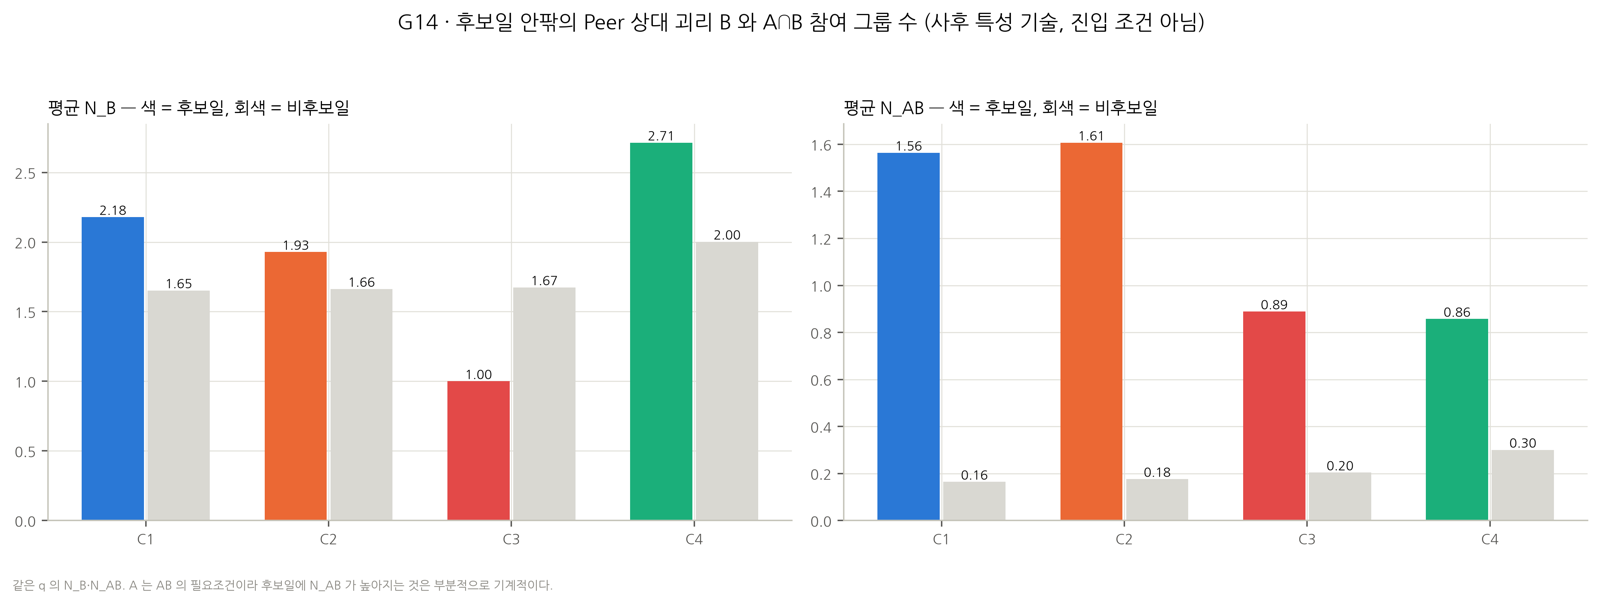

[{"candidate": "C1", "q": 20, "k": 9, "side": "후보일", "days": 39, "mean_n_B": 2.1794871794871793, "max_n_B": 5, "mean_n_AB": 1.564102564102564, "max_n_AB": 3, "share_days_AB_ge1": 0.8974358974358975}, {"candidate": "C1", "q": 20, "k": 9, "side": "비후보일", "days": 1186, "mean_n_B": 1.6526138279932547, "max_n_B": 7, "mean_n_AB": 0.16441821247892074, "max_n_AB": 3, "share_days_AB_ge1": 0.1551433389544688}, {"candidate": "C2", "q": 20, "k": 10, "side": "후보일", "days": 28, "mean_n_B": 1.9285714285714286, "max_n_B": 4, "mean_n_AB": 1.6071428571428572, "max_n_AB": 3, "share_days_AB_ge1": 0.8928571428571429}, {"candidate": "C2", "q": 20, "k": 10, "side": "비후보일", "days": 1197, "mean_n_B": 1.6633249791144


In [42]:
CAP["G14_B_AB_inside_outside"] = FG.g14_b_ab()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G14_B_AB_inside_outside.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G14_B_AB_inside_outside"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

In [43]:
display(R["b_ab"].round(3))  # 후보일 vs 비후보일의 N_B·N_AB

,candidate,q,k,side,days,mean_n_B,max_n_B,mean_n_AB,max_n_AB,share_days_AB_ge1
0,C1,20,9,후보일,39,2.179,5,1.564,3,0.897
1,C1,20,9,비후보일,1186,1.653,7,0.164,3,0.155
2,C2,20,10,후보일,28,1.929,4,1.607,3,0.893
3,C2,20,10,비후보일,1197,1.663,7,0.176,3,0.162
4,C3,20,12,후보일,9,1.000,2,0.889,1,0.889
5,C3,20,12,비후보일,1216,1.674,7,0.204,3,0.174
6,C4,60,6,후보일,14,2.714,5,0.857,2,0.714
7,C4,60,6,비후보일,1211,2.002,7,0.301,2,0.274


**해석 (G14).**
- C1 후보일의 평균 N_B 는 2.18, 비후보일은 1.65 다. Peer 상대 괴리는 후보일에 조금 늘 뿐이다.
- C3 후보일(2025-04)의 평균 N_B 는 1.00 으로 비후보일(1.67)보다 **낮다**. 가장 넓은 공통 고변동성 때 Peer 도 함께 흔들려 상대 괴리가 줄어든다. 09번에서 본 A–B 의 엇갈림과 같은 방향이다.
- N_AB 가 후보일에 높은 것(C1 1.56 vs 0.16)은 A 가 AB 의 필요조건이기 때문에 생기는 부분적인 기계적 효과다. 독립적인 근거로 쓰지 않는다.
- 결론: B 를 진입 조건에 넣으면 공통 고변동성 구간이 오히려 사라진다. 10번에서 B 를 보조 설명으로만 쓰는 이유다.

## 17. 2020 파일럿과 2026 별도 탐색 (주분석 아님)

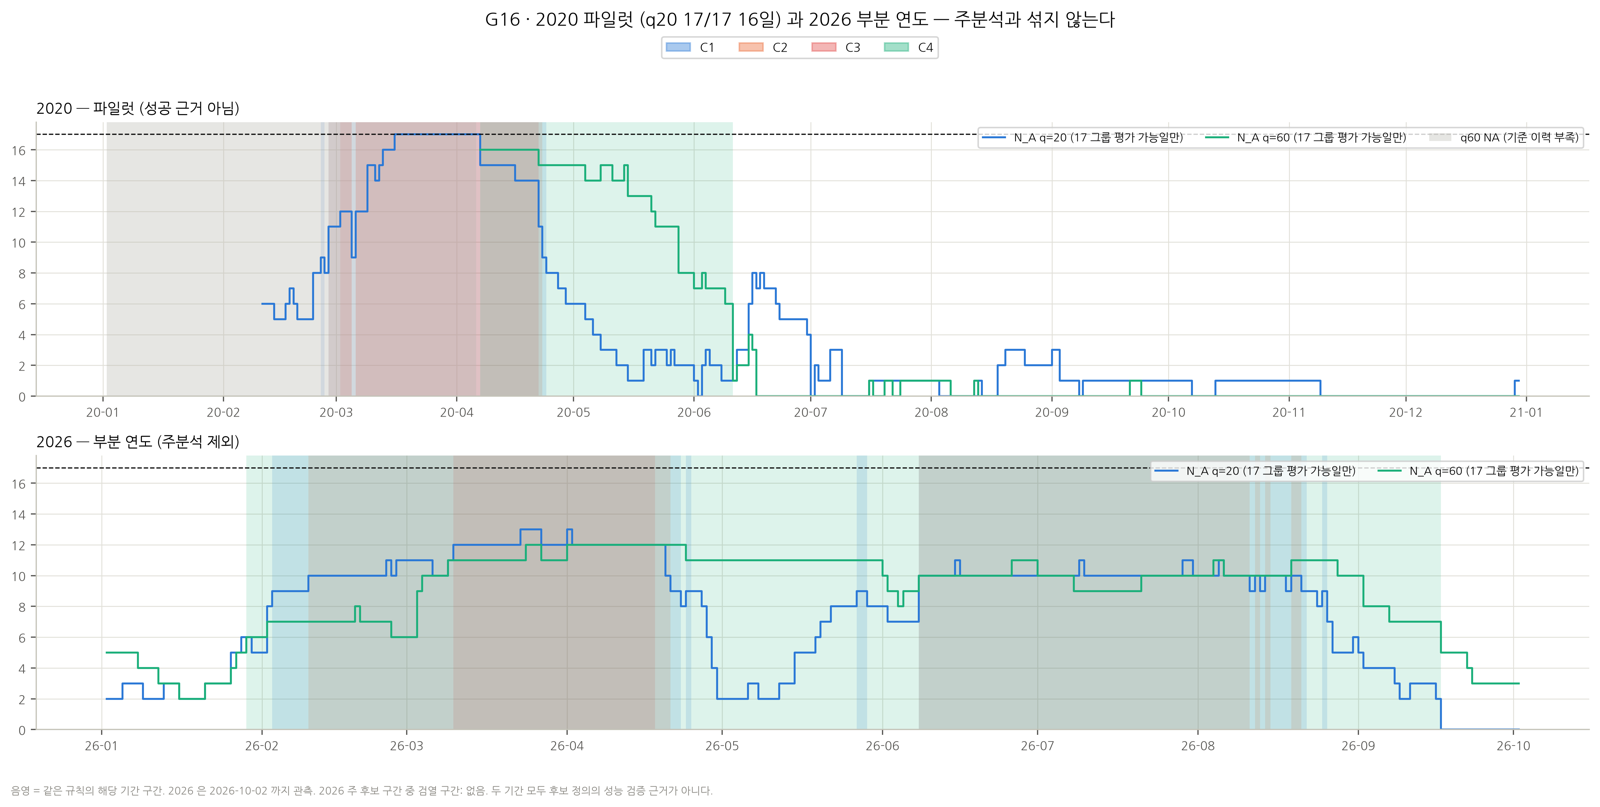

{"2020": {"C1": 40, "C2": 37, "C3": 35, "C4": 43, "k17_q20": 16}, "2026": {"C1": 110, "C2": 95, "C3": 29, "C4": 155, "k17_q20": 0}}


In [44]:
CAP["G16_pilot2020_and_2026"] = FG.g16_pilot_2026()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G16_pilot2020_and_2026.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G16_pilot2020_and_2026"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

In [45]:
# 2020 파일럿과 2026 부분 연도의 규칙별 요약 (주분석과 섞지 않는다).
COLS2 = ["rule", "label", "n_intervals", "candidate_days", "duration_max", "observed_max_n_A", "first_start", "last_end", "censored_intervals", "evaluable_days", "days_in_period"]  # 표시 열
display(R["summary_pilot"][COLS2])  # 2020 파일럿
display(R["summary_2026"][COLS2])  # 2026 부분 연도 (10-02 까지)
display(IV[(IV["period"] != "PRIMARY") & IV["candidate"].isin(["C1", "C2", "C3", "C4"])][["interval_id", "start", "end", "duration_trading_days", "max_n_A", "entry_after", "left_censored", "right_censored"]])  # 파일럿·2026 주 후보 구간

,rule,label,n_intervals,candidate_days,duration_max,observed_max_n_A,first_start,last_end,censored_intervals,evaluable_days,days_in_period
0,q20_k3,W2 참고,9,87,61,17,2020-02-11,2020-09-02,0,222,248
1,q20_k6,진단,4,59,47,17,2020-02-11,2020-06-22,0,222,248
2,q20_k9,C1,2,40,39,17,2020-02-26,2020-04-23,0,222,248
3,q20_k10,C2,2,37,33,17,2020-02-28,2020-04-22,0,222,248
4,q20_k12,C3,2,35,32,17,2020-03-02,2020-04-21,0,222,248
5,q20_k17,W4 연결 참고,1,16,16,17,2020-03-16,2020-04-06,0,222,248
6,q60_k3,W2 참고,2,45,43,16,2020-04-07,2020-06-16,0,182,248
7,q60_k6,C4,1,43,43,16,2020-04-07,2020-06-10,0,182,248
8,q60_k9,기간 통제,1,33,33,16,2020-04-07,2020-05-27,0,182,248
9,q60_k10,기간 통제,1,33,33,16,2020-04-07,2020-05-27,0,182,248


,rule,label,n_intervals,candidate_days,duration_max,observed_max_n_A,first_start,last_end,censored_intervals,evaluable_days,days_in_period
0,q20_k3,W2 참고,6,161,82,13,2026-01-05,2026-09-15,0,184,184
1,q20_k6,진단,4,129,68,13,2026-01-28,2026-08-31,0,184,184
2,q20_k9,C1,5,110,53,13,2026-02-03,2026-08-25,0,184,184
3,q20_k10,C2,5,95,46,13,2026-02-10,2026-08-20,0,184,184
4,q20_k12,C3,1,29,29,13,2026-03-10,2026-04-17,0,184,184
5,q20_k17,W4 연결 참고,0,0,0,13,,,0,184,184
6,q60_k3,W2 참고,2,181,171,12,2026-01-02,2026-10-02,2,184,184
7,q60_k6,C4,1,155,155,12,2026-01-29,2026-09-16,0,184,184
8,q60_k9,기간 통제,2,124,63,12,2026-03-03,2026-09-01,0,184,184
9,q60_k10,기간 통제,3,113,61,12,2026-03-04,2026-09-01,0,184,184


,interval_id,start,end,duration_trading_days,max_n_A,entry_after,left_censored,right_censored
62,q20_k9_PIL_001,2020-02-26,2020-02-26,1,9,AFTER_0,False,False
63,q20_k9_PIL_002,2020-02-28,2020-04-23,39,17,AFTER_0,False,False
67,q20_k9_PAR_001,2026-02-03,2026-04-22,53,13,AFTER_0,False,False
68,q20_k9_PAR_002,2026-04-24,2026-04-24,1,9,AFTER_0,False,False
69,q20_k9_PAR_003,2026-05-27,2026-05-28,2,9,AFTER_0,False,False
70,q20_k9_PAR_004,2026-06-08,2026-08-21,53,11,AFTER_0,False,False
71,q20_k9_PAR_005,2026-08-25,2026-08-25,1,9,AFTER_0,False,False
72,q20_k10_PIL_001,2020-02-28,2020-03-04,4,12,AFTER_0,False,False
73,q20_k10_PIL_002,2020-03-06,2020-04-22,33,17,AFTER_0,False,False
79,q20_k10_PAR_001,2026-02-10,2026-04-20,46,13,AFTER_0,False,False


**해석 (G16).**
- **2020 파일럿**: q20 은 2020-03-16~04-06 에 17/17 이 16일이다 (09 재현). C1 은 2020-02-28~04-23 의 39일 구간을 포함해 40일이다. q60 구간은 모두 2020-04-07 에 시작한다. 그 직전은 기준 이력 부족으로 NA 이므로 진입 직전 상태는 'AFTER_NA' 다. 실제 시작은 더 이를 수 있다.
- **2026 (부분 연도, 2026-10-02 까지)**: C1 110일, C4 155일 (2026-01-29~09-16 한 구간). 주분석 5년 전체보다 많다. 2026 이 확장형 기준 대비 이례적인 고변동성 해였다는 뜻이다. 다만 비맹검 부분 연도라 정의를 고르는 근거로 쓰지 않는다.
- 두 기간 모두 **후보 정의의 성능 검증 근거가 아니다**. 2020 의 17/17 이 있었다고 해서 k=17 이 좋은 정의라는 뜻도 아니다.

## 18. 기존 W2·W3 와의 정의 차이

In [46]:
display(R["w2w3"])  # 주 후보 구간과 W2 교차 그룹 구간·W3 공동 에피소드의 겹침 (비교만)

,candidate,interval_id,start,end,duration,max_n_A,w2_overlap_n,w2_overlap,w3_joint_episode_overlap_n
0,C1,q20_k9_PRI_001,2022-10-11,2022-10-12,2,9,1,HIGH_LEVEL 2022-09-07~2022-12-07 (최대 7그룹),0
1,C1,q20_k9_PRI_002,2024-08-05,2024-09-02,20,10,3,EXPANSION 2024-08-02~2024-09-02 (최대 11그룹); HIGH_LEVEL 2024-08-05~2024-08-23 (최대 10그룹); HIGH_LEVEL 2024-09-02~2024-09-02 (최대 3그룹),0
2,C1,q20_k9_PRI_003,2025-04-10,2025-05-07,17,12,2,EXPANSION 2025-04-07~2025-05-07 (최대 10그룹); HIGH_LEVEL 2025-04-07~2025-05-26 (최대 13그룹),1
3,C2,q20_k10_PRI_001,2024-08-07,2024-08-07,1,10,2,EXPANSION 2024-08-02~2024-09-02 (최대 11그룹); HIGH_LEVEL 2024-08-05~2024-08-23 (최대 10그룹),0
4,C2,q20_k10_PRI_002,2024-08-12,2024-08-26,10,10,2,EXPANSION 2024-08-02~2024-09-02 (최대 11그룹); HIGH_LEVEL 2024-08-05~2024-08-23 (최대 10그룹),0
5,C2,q20_k10_PRI_003,2024-08-28,2024-08-30,3,10,1,EXPANSION 2024-08-02~2024-09-02 (최대 11그룹),0
6,C2,q20_k10_PRI_004,2025-04-10,2025-04-28,13,12,2,EXPANSION 2025-04-07~2025-05-07 (최대 10그룹); HIGH_LEVEL 2025-04-07~2025-05-26 (최대 13그룹),1
7,C2,q20_k10_PRI_005,2025-05-07,2025-05-07,1,10,2,EXPANSION 2025-04-07~2025-05-07 (최대 10그룹); HIGH_LEVEL 2025-04-07~2025-05-26 (최대 13그룹),0
8,C3,q20_k12_PRI_001,2025-04-11,2025-04-23,9,12,2,EXPANSION 2025-04-07~2025-05-07 (최대 10그룹); HIGH_LEVEL 2025-04-07~2025-05-26 (최대 13그룹),1
9,C4,q60_k6_PRI_001,2022-11-21,2022-11-22,2,6,1,HIGH_LEVEL 2022-09-07~2022-12-07 (최대 7그룹),0


**해석.**

| 항목 | W2 (06) | W3 (08) | 10번 후보 |
|---|---|---|---|
| 변동성 | `mean(r²)` (평균 0, ddof 0), q 3–120 | SVR–GARCH 잔차 CUSUM, 검정창 w | 표본표준편차 연환산 σ, q 20·60 |
| 고변동 판정 | 과거 분위 (HIGH_LEVEL·EXPANSION 채널) | 공동 CUSUM 통계량 | 과거 분위 0.90 (09 의 A) |
| KOSPI200 | 구성원 하나라도 (OR) | 대표 6종(069500·229200·148070·153130·261220·133690) 중 069500 하나 | Core Pair 둘 다 (AND) |
| 공통성 | 여러 q 중 3개 이상 겹친 ETF 의 그룹 수 | 공동 통계 유의성 | 같은 날 A 그룹 수 ≥ k |
| 결론 지위 | 탐색적 | `LOW_POWER_INCONCLUSIVE` + `NULL_MODEL_INVALID` (유의 공동 구간 0) | 사후 탐색 후보 |

- C1 의 세 구간은 모두 W2 HIGH_LEVEL·EXPANSION 구간과 겹친다. 다만 경계는 다르다. 예를 들어 2025-04 의 W2 HIGH_LEVEL 은 04-07~05-26 (13그룹), C1 은 04-10~05-07 이다. W2 경계를 복사하지 않았으므로 다른 것이 정상이다.
- W3 공동 에피소드와 겹치는 주 후보 구간은 2025-04 의 C1·C2·C3 뿐이다 (W3 는 귀무모형 부적합으로 탐색적이다). 10번은 W3 의 검출력 문제를 해결하지 않는다. 10번은 검정이 아니라 상태 정의다.

## 19. 후보 간 비교평가 및 의사결정표

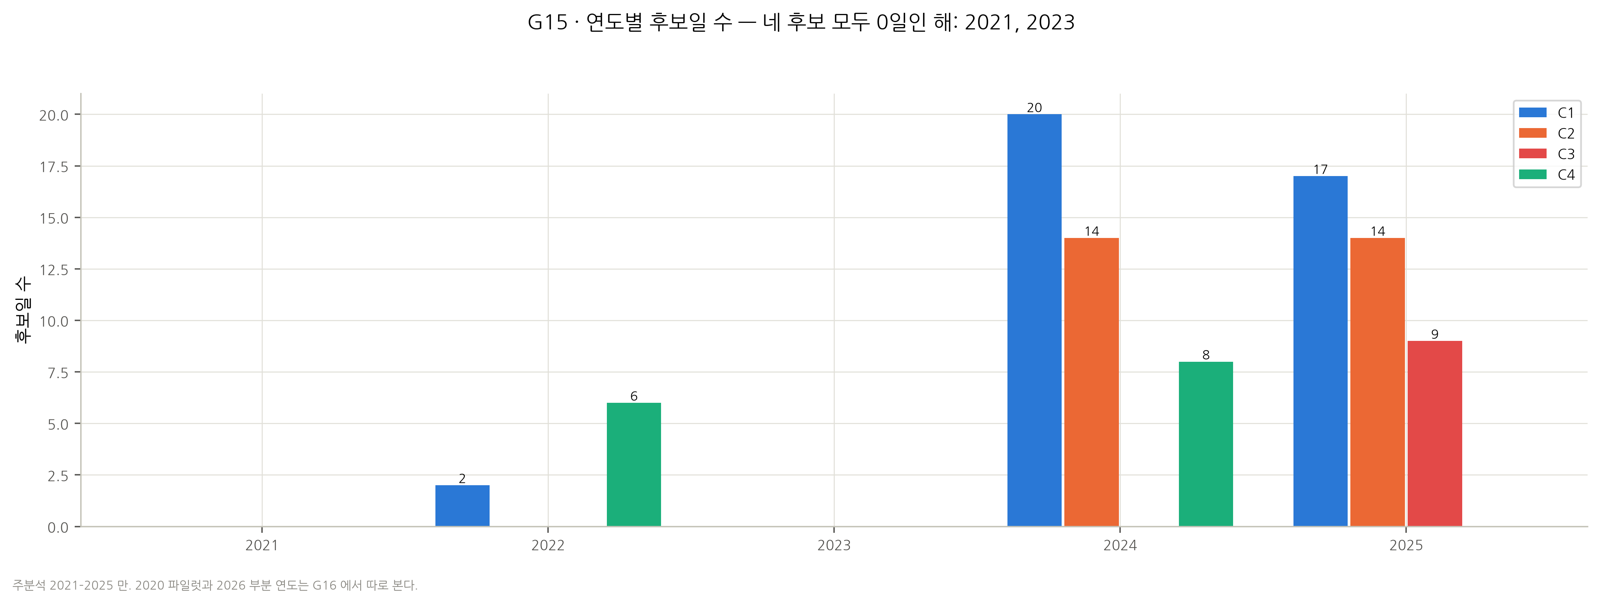

{}


In [47]:
CAP["G15_yearly_candidate_days"] = FG.g15_yearly()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "G15_yearly_candidate_days.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP["G15_yearly_candidate_days"], ensure_ascii=False, default=str)[:700])  # 그림 캡션의 실제 수치

In [48]:
# 의사결정표: 수치는 결과표에서, 성격·한계는 위 장들의 해석을 요약한다.
DEC = pd.DataFrame([  # 후보별 비교
    {"후보": c, "q": CFG["main_candidates"][c]["q"], "k": CFG["main_candidates"][c]["k"], "구간 수": int(SMI.loc[r, "n_intervals"]), "후보일": int(SMI.loc[r, "candidate_days"]), "1일 구간": int(SMI.loc[r, "n_one_day"]), "최장": int(SMI.loc[r, "duration_max"]), "관측 최대 대비 k": f"{CFG['main_candidates'][c]['k']}/{int(SMI.loc[r, 'observed_max_n_A'])}"}  # 수치 열
    for c, r in (("C1", "q20_k9"), ("C2", "q20_k10"), ("C3", "q20_k12"), ("C4", "q60_k6"))  # 네 후보
]).set_index("후보")  # 표 정리
DEC["대표 사건"] = ["2022-10(2일)·2024-08(20일)·2025-04(17일)", "2024-08(3조각)·2025-04(2조각)", "2025-04(9일)만", "2022-11(2조각)·2024-10~11(8일)"]  # 위 §8–§14 결과
DEC["강조하는 시장 상태"] = ["충격 시점의 과반 동시 고변동성", "C1 중 더 넓은 동시성 (조각남)", "관측 최대 수준의 극단 동시성", "충격 뒤 누적된 중기 고변동성"]  # 성격
DEC["주요 한계"] = ["2022 채권 국면은 2일만 · 주식 그룹 비중에 민감", "N_A 9↔10 진동으로 사건 분할 · 2022 소멸", "k=관측 최대 (사후 선택) · 사건 1개", "k=관측 최대 (칼날) · q20 사건과 날짜 0일 겹침"]  # 한계
NTi = X["null"].set_index(["q", "k"])  # 귀무 표 (lock-2)
DEC["우연 확률 (기간 최대)"] = [round(float(NTi.loc[(CFG["main_candidates"][c]["q"], CFG["main_candidates"][c]["k"]), "p_fw_null"]), 4) for c in DEC.index]  # 우연 기준선 D1
DEC["lock-2 판정"] = ["k*_fw 와 같음 — 통과", "통과 · 이력 H2 로 조각 해결", "통과 · 관측 최대 = k", "우연과 구별 안 됨 (k*_fw 7 > 최대 6)"]  # 우연·이력 판정 D1·D3
display(DEC)  # 의사결정표

,q,k,구간 수,후보일,1일 구간,최장,관측 최대 대비 k,대표 사건,강조하는 시장 상태,주요 한계,우연 확률 (기간 최대),lock-2 판정
후보,,,,,,,,,,,,
C1,20,9,3,39,0,20,9/12,2022-10(2일)·2024-08(20일)·2025-04(17일),충격 시점의 과반 동시 고변동성,2022 채권 국면은 2일만 · 주식 그룹 비중에 민감,0.0050,k*_fw 와 같음 — 통과
C2,20,10,5,28,2,13,10/12,2024-08(3조각)·2025-04(2조각),C1 중 더 넓은 동시성 (조각남),N_A 9↔10 진동으로 사건 분할 · 2022 소멸,0.0005,통과 · 이력 H2 로 조각 해결
C3,20,12,1,9,0,9,12/12,2025-04(9일)만,관측 최대 수준의 극단 동시성,k=관측 최대 (사후 선택) · 사건 1개,0.0000,통과 · 관측 최대 = k
C4,60,6,3,14,0,8,6/6,2022-11(2조각)·2024-10~11(8일),충격 뒤 누적된 중기 고변동성,k=관측 최대 (칼날) · q20 사건과 날짜 0일 겹침,0.1635,우연과 구별 안 됨 (k*_fw 7 > 최대 6)


**해석 — 무엇을 근거로 고를 것인가.**

1. **사건 포착 범위**: 세 사례(2022·2024-08·2025-04)를 모두 잡는 후보는 C1 하나다. C2 는 2022 를 잃고, C3 는 2025-04 만 남긴다. C4 는 2022 와 2024 를 늦게 잡고 2025-04 는 놓친다.
2. **경계 안정성**: k 를 한 단계 바꿨을 때 결과가 얼마나 흔들리는가. q20 의 후보일은 k=7–9 에서 46·41·39 로 평탄하다. k=10 이상에서는 급변한다. C1 은 평탄 구간의 끝, C2·C3 는 급변 구간, C4 는 관측 최대 바로 위의 칼날이다.
3. **사건 단위의 일관성**: C1 은 사건 하나를 구간 하나로 본다 (1일 구간 0개). C2 는 같은 사건을 여러 구간으로 나눈다 (1일 구간 2개). CNN 학습 표본을 구간 단위로 자를 계획이라면 이 차이가 표본 수를 바꾼다.
4. **사후 선택의 정도**: C3·C4 의 k 는 09번의 관측 최대와 같다. 정의상 '최대 도달일' 과 같아지므로 독립적인 정의라기보다 관측의 재표현이다.
5. **기간 q 의 의미**: q20 과 q60 은 같은 날짜를 거의 공유하지 않는다 (k=6 에서 0일). 어느 하나를 고르는 문제가 아니라 '충격 시점' 과 '충격 후 누적' 중 무엇을 라벨로 삼을지의 문제다.
6. **우연 기준 (lock-2)**: 20일 기준은 k=9 에서 처음 우연(5%)을 벗어난다. 60일 기준은 관측 최대(6)까지도 우연과 구별되지 않는다. C1 은 사후 선택이었지만 우연 기준과 일치하고, C4 는 단독 정의로 쓰기 어렵다.
7. **자산군 (lock-2)**: C1 의 2024-08 은 주식만의 급변이다. 다자산 급변만 원하면 WB, 시장 전체 주가 충격을 포함하려면 C1 이다.

## 20. 발표용 최종 요약 (교수·연구팀 브리핑)

### ① 문제 정의
기존 정의(17개 노출 그룹 모두 A∩B, 20∨60일)에서는 2021–2025 주분석 1,225일 동안 유효한 급변 구간이 **0개**였다 (`VALID_ZERO_INTERVALS`, 판정 유지).

### ② 원인
A(자기 과거 대비 고변동성)는 시장 공통 현상이고, B(Peer 대비 상대 괴리)는 개별 ETF 의 이탈이다. 시장 전체가 흔들리면 Peer 도 함께 흔들려 B 가 줄어든다. 그래서 두 상태가 17개 그룹에서 동시에 나타나지 않는다. A 만 보아도 동시 참여는 최대 12/17 (q20) · 6/17 (q60) 이다.

### ③ 연구 전환
시장 공통 고변동성 A 하나에 집중했다. "같은 날 A 인 그룹이 k 개 이상" 인 날을 후보로 두고, q ∈ {20, 60} × k ∈ {3, 6, 9, 10, 12, 17} 격자를 비교했다. B·AB 는 사후 설명으로만 썼다. **09번 결과를 본 뒤 설계한 사후 탐색**이다.

### ④ 정의별 실제 결과 (2021–2025)
| 후보 | 규칙 | 구간 | 후보일 | 실제 구간 |
|---|---|---|---|---|
| C1 | q20, ≥9/17 | 3 | 39 | 2022-10-11~12 · 2024-08-05~09-02 · 2025-04-10~05-07 |
| C2 | q20, ≥10/17 | 5 | 28 | 2024-08 3조각 · 2025-04-10~04-28 · 2025-05-07 |
| C3 | q20, ≥12/17 | 1 | 9 | 2025-04-11~04-23 |
| C4 | q60, ≥6/17 | 3 | 14 | 2022-11-21~22 · 2022-11-24~29 · 2024-10-24~11-04 |

### ⑤ 비교평가
- **우연 기준 (v2)**: 20일 기준은 k=9 에서 처음 우연을 벗어난다 (5년 중 하루라도 9개 이상 동시일 우연 확률 0.005). 60일 C4 는 0.164 로 우연과 구별되지 않는다.
- C1 은 **충격 시점의 과반 동시 고변동성**을 잡는다. 세 사례를 모두 포함하고 사건당 구간 하나로 나온다.
- C2 는 더 넓은 동시성을 요구한다. 2022 를 잃고 2024-08 을 세 조각으로 나눈다.
- C3 는 2025-04 다자산 급변 하나만 남기는 **극단 표지**다.
- C4 는 **충격 뒤 누적된 중기 고변동성**이다. q20 후보와 날짜가 겹치지 않는다.

### ⑥ 최종 의사결정 (승인 전 — 제안만)
- **제안 A (주 후보)**: C1 (q20, k=9) — v2 에서 우연 기준 k*_fw = 9 와 일치해 근거가 강해졌다. 비용: 2022 채권 국면이 2일로 축소된다. 2024-08 처럼 주식만의 급변도 포함된다 (원치 않으면 WB).
- **제안 B (보완층)**: C1 구간 뒤 약 33거래일의 '누적 국면' 을 60일 기준으로 표시 (D5). C4 를 단독 정의로 쓰는 것은 권하지 않는다 — 우연 확률 0.164.
- **제안 C (극단 표지)**: C3 를 C1 내부의 '극단' 하위 표지로 쓴다. 비용: 사건 1개라 학습 표본으로는 부족하다.
- 어느 쪽이든 최종 정의는 **새 계약(lock)** 으로 고정한다. 그 뒤 2026 이후의 맹검 자료와 미래 수익률 꼬리 같은 독립 정답으로 평가해야 한다. 갭 병합(하루 미충족 연결) 여부도 그 계약에서 정한다.

### v2 인포그래픽

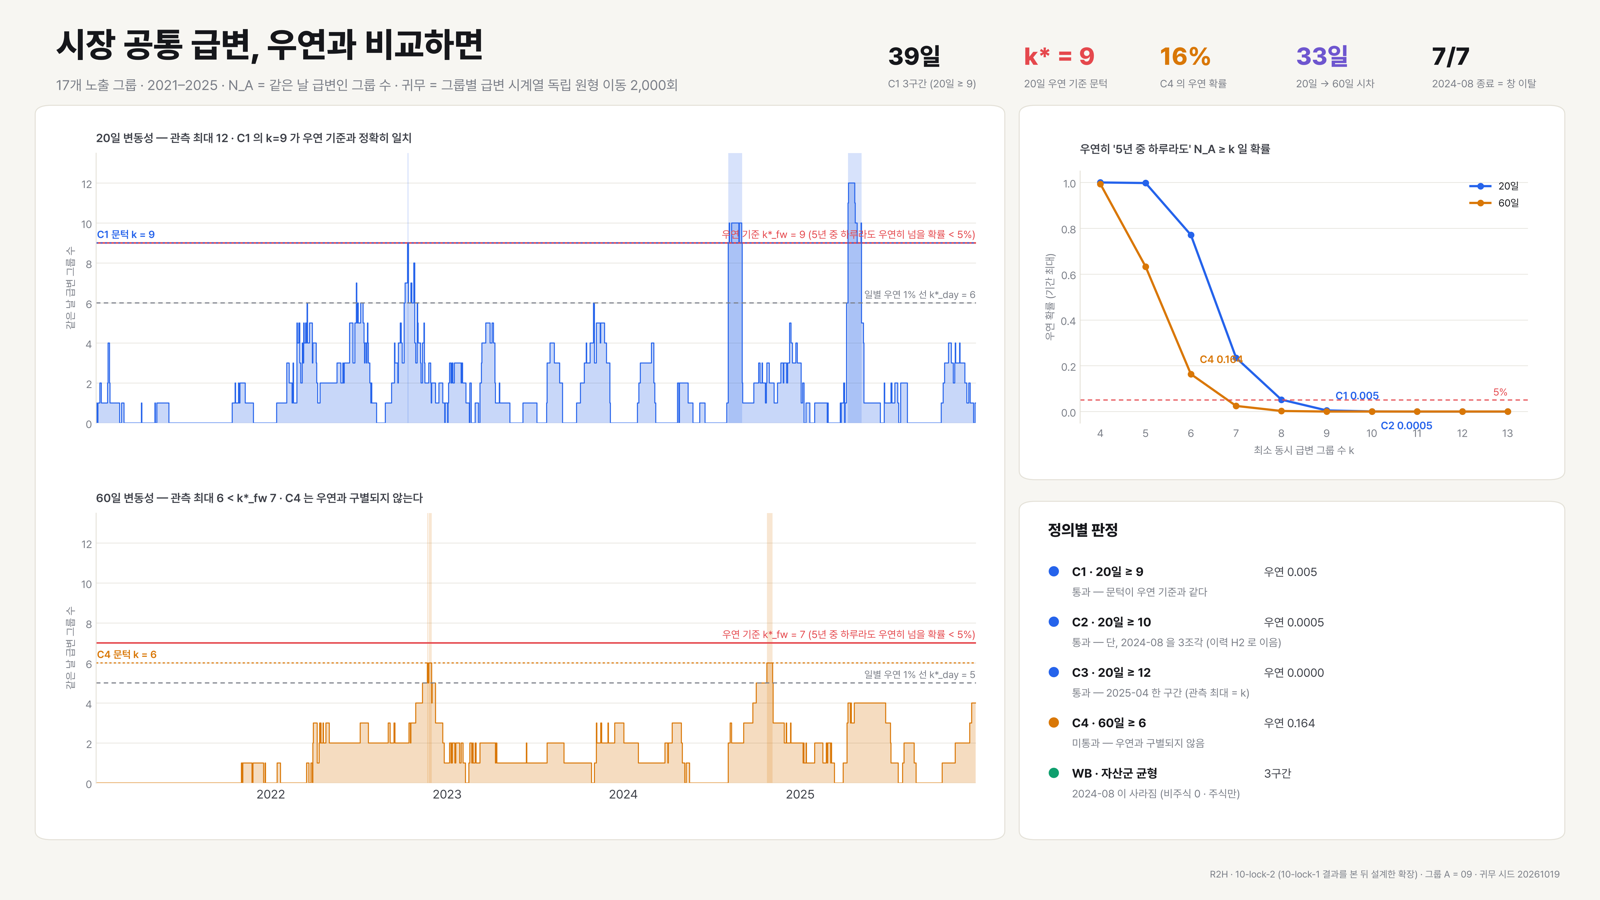

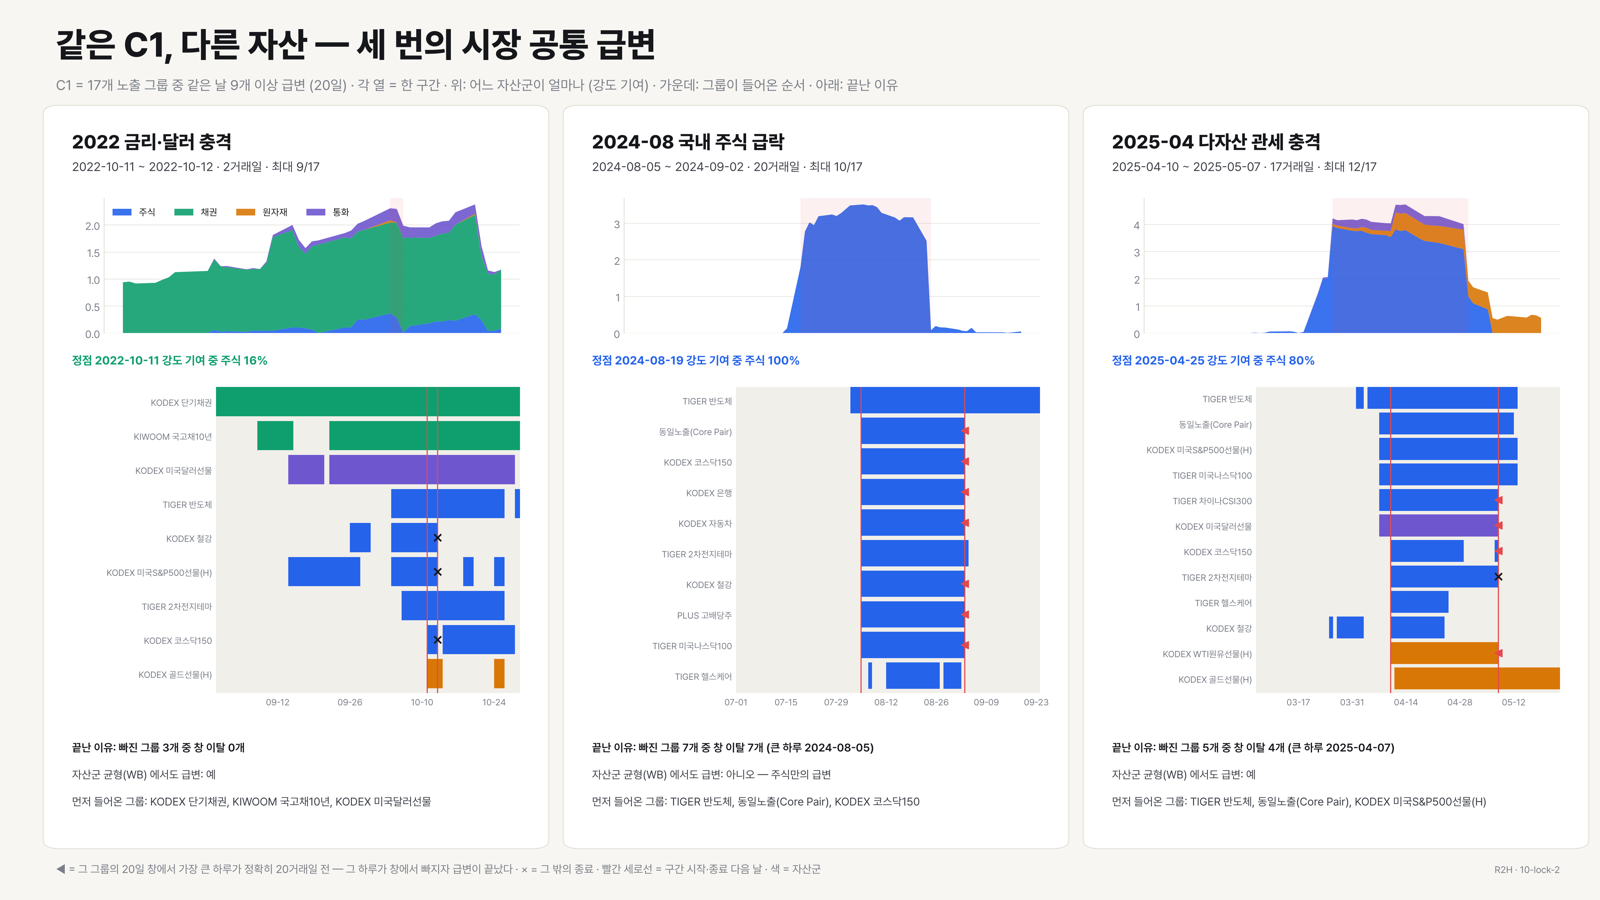

In [49]:
# 발표용 인포그래픽 2장 (밝은 판, Pretendard) — scripts/t19_infographics_light.py 가 같은 결과로 생성.
IGD = BASE / "infographics"  # 인포그래픽 폴더
for _n in ("IG10_1_definitions_vs_chance", "IG10_2_c1_three_intervals"):  # 두 장
    display(Image(data=preview(IGD / f"{_n}.png")))  # 미리보기

### 한 문장 요약
> 2021–2025 에서 17개 노출 그룹의 공통 고변동성은 20일 기준 과반(≥9/17)으로는 2022-10·2024-08·2025-04 의 세 구간(39일)으로, 극단(≥12/17)으로는 2025-04 한 구간(9일)으로, 60일 기준(≥6/17)으로는 충격 뒤 2022-11·2024-10~11 의 누적 구간(14일)으로 나타나며, 17/17 동시 급변은 A 만으로도 관측되지 않았다. v2: C1 의 k=9 는 그룹 간 동시성을 없앤 귀무에서 처음 우연(5%)을 벗어나는 문턱과 같고, 60일 C4 는 우연과 구별되지 않는다.

### PPT 구성 초안 (6장)
1. **문제** — 17/17 A∩B = 0 구간. 원인은 A·B 의 엇갈림 (09 F27 · 10 G14).
2. **전환** — A 하나, 같은 날 참여 그룹 수 N_A. 17 그룹 상태 지도 (G01).
3. **k 와 q 의 효과** — 생존곡선·분할 (G03 · G08). k=7–9 평탄, 10 이상 급변. q20·q60 겹침 0.
4. **실제 구간** — C1–C4 간트와 표 (G05 · ④ 표).
5. **사례 3개** — 2022 채권 (G09) · 2024-08 국내 주식 (G10) · 2025-04 다자산 (G11).
6. **의사결정** — 제안 A·B·C 와 비용, 다음 단계: 새 lock, 2026 맹검, 독립 정답 (§19 표).
7. **(v2) 우연과 비교하면** — IG10-1 (k*_fw = 9 = C1, C4 우연 16%).
8. **(v2) 같은 C1, 다른 자산** — IG10-2 (2022 금리 → 주식 확산 · 2024-08 주식만 · 2025-04 다자산).

## 21. 한계·검증·후속 연구 조건

**한계**
- 사후 탐색: 격자는 09번 결과를 본 뒤 정했다. C3·C4 의 k 는 관측 최대와 같다.
- 그룹 구성 편향: 17개 중 주식 계열이 12개다. '17개 중 k 개' 기준은 주식 충격에 유리하다. v2 의 균형 규칙 WB 는 비교용이며 가중 방식은 하나만 시험했다.
- 우연 기준선의 귀무는 그룹 간 상관을 전부 없앤다. 상관을 보존하는 귀무에서는 k* 가 더 커질 수 있다.
- 연속 강도 지수는 한 그룹의 이상값(153130 2024-01)에 민감하다. 구간 정의에는 쓰지 않았다.
- A 의 기준은 확장형 과거 분위다. 2026 처럼 이례적인 해 뒤에는 기준이 높아져 같은 σ 라도 A 가 덜 켜진다.
- 갭 병합을 하지 않는다. 하루 미충족으로 사건이 쪼개진다 (C2 2024-08 3조각, C4 2022-11 2조각).
- 외부 사건 이름은 맥락일 뿐이다. 이 데이터로 원인을 검증하지 않았다.
- 원문 지시서가 일부(PART VI 중간~PART XII 검증 1–9) 잘려 있었다. E2·E3 는 목차와 09 사건 창으로 재구성했다.

**검증 (이 노트북 또는 pytest `tests/unit/test_common_vol_10.py` 에서 assert)**
- 09 승계: 매니페스트 지문(예외 1건 명시), N_A·n_eval 전 행, 기간별 최대·17/17·NA.
- 같은 q 의 날짜 포함관계, 같은 날짜의 구간 중복 없음, 후보일 수 = 구간 지속일 합, 구간 최대 = 일별 원자료, 참여 그룹 명단 길이 = 집계 수 (ever + 없음 = 17) — `pipeline.check_intervals`.
- NA ≠ 0 (합성 테스트), 기간 분리(2020·2021–2025·2026), 연도 경계 연속 (합성 테스트 + 실제 2024-12→2025-01 구간), 주분석 끝 구간의 우측 검열 = 2026-01-02 상태 (pytest).
- C3·C4 날짜 집합 = 09 `max_participation_days` 의 최대 도달일 (교차 앵커).
- W4 17/17 AB 0개 유지, 09 노트북·W4 results 지문 작업 전후 동일.
- (v2) lock-2 동결 지문, 경계 σ 역산 A ⟺ σ > 경계 (20종, 동점 없는 날), 귀무 시드 고정, lock-1 결과 CSV 바이트 동일.

**후속 연구 조건**
1. 교수·연구팀이 C1/C4/C3 조합 중 하나를 고르면 새 계약(lock)으로 고정한다 (갭 병합·그룹 가중 포함).
2. 평가는 라벨과 독립된 정답(예: 미래 수익률 꼬리)으로 사전 등록한다.
3. 2026 이후 맹검 자료로 확인한다.

## 22. CLAIMS 및 재현성 검증

In [50]:
# 해석 문단의 숫자를 결과 파일에서 다시 읽어 대조한다 (불일치면 실패).
def iv_str(c):  # 후보의 주분석 구간 문자열
    x = IVP[IVP["candidate"] == c]  # 해당 후보
    return "; ".join(f"{a}~{b}" for a, b in zip(x["start"], x["end"]))  # 시작~끝 목록


GBP = pd.read_csv(W4 / "results/global_by_period.csv")  # 09 기간별 요약
EVD = R["event_days"]  # 사례별 C1 후보일
PTc = R["participation"].set_index(["candidate", "group"])  # 참여 비율
BAB = R["b_ab"].set_index(["candidate", "side"])  # B·AB 안팎
HZ = R["horizon"].set_index("k")  # q 비교
JC = R["jaccard"].set_index(["rule_a", "rule_b"])  # 날짜 Jaccard
EV = R["events"].set_index(["event", "rule"])  # 사례 × 규칙
CLAIMS = [  # (주장, 관측, 기대)
    ("주분석 거래일", len(PRI), 1225),  # 주분석 2021–2025
    ("주분석 q20 NA", int((PRI["n_eval_A_q20"] < 17).sum()), 0),  # 전부 평가 가능
    ("q20 최대 N_A", int(PRI["n_A_q20"].max()), int(GBP[(GBP.period == "PRIMARY") & (GBP.q == 20)].max_n_A.iloc[0])),  # 09 와 같음
    ("q60 최대 N_A", int(PRI["n_A_q60"].max()), int(GBP[(GBP.period == "PRIMARY") & (GBP.q == 60)].max_n_A.iloc[0])),  # 09 와 같음
    ("q20 최대 N_A 값", int(PRI["n_A_q20"].max()), 12),  # 본문 12
    ("q60 최대 N_A 값", int(PRI["n_A_q60"].max()), 6),  # 본문 6
    ("파일럿 q20 17/17 일수 = 09", int(R["summary_pilot"].set_index("rule").loc["q20_k17", "candidate_days"]), int(GBP[(GBP.period == "PILOT") & (GBP.q == 20)].days17_A.iloc[0])),  # 09 재현
    ("파일럿 q20 17/17 값", int(R["summary_pilot"].set_index("rule").loc["q20_k17", "candidate_days"]), 16),  # 본문 16일
    ("파일럿 q60 04-07 진입 직전", set(IV[(IV.period == "PILOT") & (IV.q == 60) & (IV.start.astype(str) == "2020-04-07")]["entry_after"]), {"AFTER_NA"}),  # NA 직후 진입
    ("파일럿 q60 시작일", set(IV[(IV.period == "PILOT") & (IV.q == 60)].groupby("rule")["start"].min().astype(str)), {"2020-04-07"}),  # 모두 04-07
    ("2024-08-02·05 N_A", (int(D.loc[D["date"] == "2024-08-02", "n_A_q20"].iloc[0]), int(D.loc[D["date"] == "2024-08-05", "n_A_q20"].iloc[0])), (1, 9)),  # 1 → 9 도약
    ("q20 평균 N_A", round(float(PRI["n_A_q20"].mean()), 2), 1.75),  # 그림 G01 해석
    ("q60 평균 N_A", round(float(PRI["n_A_q60"].mean()), 2), 1.46),  # 그림 G01 해석
    ("k=7·8·9 일수", tuple(int((PRI["n_A_q20"] >= k).sum()) for k in (7, 8, 9)), (46, 41, 39)),  # 평탄
    ("k=10·11 일수", tuple(int((PRI["n_A_q20"] >= k).sum()) for k in (10, 11)), (28, 11)),  # 급감
    ("C1 구간", iv_str("C1"), "2022-10-11~2022-10-12; 2024-08-05~2024-09-02; 2025-04-10~2025-05-07"),  # §8 표
    ("C2 구간", iv_str("C2"), "2024-08-07~2024-08-07; 2024-08-12~2024-08-26; 2024-08-28~2024-08-30; 2025-04-10~2025-04-28; 2025-05-07~2025-05-07"),  # §8 표
    ("C3 구간", iv_str("C3"), "2025-04-11~2025-04-23"),  # §8 표
    ("C4 구간", iv_str("C4"), "2022-11-21~2022-11-22; 2022-11-24~2022-11-29; 2024-10-24~2024-11-04"),  # §8 표
    ("후보일 C1–C4", tuple(int(SMI.loc[r, "candidate_days"]) for r in ("q20_k9", "q20_k10", "q20_k12", "q60_k6")), (39, 28, 9, 14)),  # 본문 §9 대조
    ("구간 수 C1–C4", tuple(int(SMI.loc[r, "n_intervals"]) for r in ("q20_k9", "q20_k10", "q20_k12", "q60_k6")), (3, 5, 1, 3)),  # 본문 §9 대조
    ("1일 구간 C1·C2", (int(SMI.loc["q20_k9", "n_one_day"]), int(SMI.loc["q20_k10", "n_one_day"])), (0, 2)),  # 본문 §9 대조
    ("C1 지속 중앙값", float(SMI.loc["q20_k9", "duration_median"]), 17.0),  # 본문 §9 대조
    ("C4 지속 중앙·최장", (float(SMI.loc["q60_k6", "duration_median"]), int(SMI.loc["q60_k6", "duration_max"])), (4.0, 8)),  # 본문 §9 대조
    ("C1 안정성 Jaccard", round(float(SMI.loc["q20_k9", "mean_stability_jaccard"]), 2), 0.98),  # 본문 §9 대조
    ("후보 비율 C1·C2·C3·C4 %", tuple(round(100 * float(SMI.loc[r, "candidate_share"]), 1) for r in ("q20_k9", "q20_k10", "q20_k12", "q60_k6")), (3.2, 2.3, 0.7, 1.1)),  # 본문 §9 대조
    ("0개 규칙 gap", tuple(int(SMI.loc[r, "gap_k_minus_max"]) for r in ("q20_k17", "q60_k9", "q60_k10", "q60_k12", "q60_k17")), (5, 3, 4, 6, 11)),  # 본문 §9 대조
    ("주 후보 구간 수", len(MAIN_IV), 12),  # 본문 §8 대조
    ("주 후보 검열 구간", int(((MAIN_IV["left_censored"] != False) | (MAIN_IV["right_censored"] != False)).sum()), 0),  # 검열 없음  # noqa: E712
    ("주 후보 종료 사유", set(MAIN_IV["exit_reason"]), {"CONDITION_EXITED"}),  # 모두 0 으로 종료
    ("ever = 동시 최대", bool((MAIN_IV["n_groups_ever"] == MAIN_IV["max_n_A"]).all()), True),  # 본문 §8 대조
    ("C1 2025-04 매일·최대", tuple(MAIN_IV[(MAIN_IV.candidate == "C1") & (MAIN_IV.start.astype(str) == "2025-04-10")][["n_groups_always", "max_n_A"]].iloc[0]), (8, 12)),  # 본문 §9 대조
    ("C4 2022-11-23 N_A", int(D.loc[D["date"] == "2022-11-23", "n_A_q60"].iloc[0]), 5),  # 분할 원인
    ("k6→C1 소멸 구간", int(((KID.q == 20) & (KID.k_loose == 6) & (KID.relation == "소멸")).sum()), 6),  # 본문 §10 대조
    ("C1→C2 분할", tuple(KID[(KID.q == 20) & (KID.k_loose == 9)]["n_children"]), (0, 3, 2)),  # 본문 §10 대조
    ("C1–C2·C1–C3 Jaccard", (round(float(JC.loc[("q20_k9", "q20_k10"), "jaccard"]), 2), round(float(JC.loc[("q20_k9", "q20_k12"), "jaccard"]), 2)), (0.72, 0.23)),  # 본문 §10 대조
    ("2024-08 N_A 9 인 C1 날", tuple(str(x) for x in EVD[(EVD.event == "E2_2024_08") & ~EVD.in_C2].date), ("2024-08-05", "2024-08-06", "2024-08-08", "2024-08-09", "2024-08-27", "2024-09-02")),  # 본문 §10 대조
    ("2025-04 C2 제외 날", tuple(str(x) for x in EVD[(EVD.event == "E3_2025_04") & ~EVD.in_C2].date), ("2025-04-29", "2025-04-30", "2025-05-02")),  # 본문 §10 대조
    ("k=6 q 겹침", (int(HZ.loc[6, "q20_days"]), int(HZ.loc[6, "q60_days"]), int(HZ.loc[6, "both_days"])), (65, 14, 0)),  # 본문 §11 대조
    ("k=3 q Jaccard·접촉", (round(float(HZ.loc[3, "jaccard"]), 2), int(HZ.loc[3, "q20_intervals_touching_q60"]), int(HZ.loc[3, "q20_intervals"])), (0.17, 15, 30)),  # 본문 §11 대조
    ("E1 C1·C4 일수", (int(EV.loc[("E1_2022_bond", "q20_k9"), "candidate_days"]), int(EV.loc[("E1_2022_bond", "q60_k6"), "candidate_days"])), (2, 6)),  # 본문 §12 대조
    ("E1 W2 참고 일수·k6", (int(EV.loc[("E1_2022_bond", "q20_k9"), "w2_ref_days"]), int(EV.loc[("E1_2022_bond", "q20_k6"), "candidate_days"])), (62, 23)),  # 본문 §12 대조
    ("E2 q20 최대·날짜", (int(EV.loc[("E2_2024_08", "q20_k9"), "window_max_n_A"]), EV.loc[("E2_2024_08", "q20_k9"), "window_max_first_date"]), (10, "2024-08-07")),  # 본문 §13 대조
    ("E2 q60 최대·날짜", (int(EV.loc[("E2_2024_08", "q60_k6"), "window_max_n_A"]), EV.loc[("E2_2024_08", "q60_k6"), "window_max_first_date"]), (4, "2024-09-25")),  # 본문 §13 대조
    ("E2 k6 = C1", EV.loc[("E2_2024_08", "q20_k6"), "intervals"] == EV.loc[("E2_2024_08", "q20_k9"), "intervals"], True),  # 본문 §13 대조
    ("E3 q60 최대", int(EV.loc[("E3_2025_04", "q60_k6"), "window_max_n_A"]), 4),  # 본문 §14 대조
    ("C1 참여 반도체·2차전지·KOSPI200·나스닥·코스닥", tuple(round(float(PTc.loc[("C1", g), "share_on_candidate_days"]), 2) for g in ("091230", "305540", "KOSPI200_동일노출", "133690", "229200")), (1.0, 1.0, 0.95, 0.95, 0.92)),  # 본문 §15 대조
    ("C1 참여 채권", (round(float(PTc.loc[("C1", "148070"), "share_on_candidate_days"]), 2), round(float(PTc.loc[("C1", "153130"), "share_on_candidate_days"]), 2)), (0.05, 0.05)),  # 본문 §15 대조
    ("C1 N_B 안팎", (round(float(BAB.loc[("C1", "후보일"), "mean_n_B"]), 2), round(float(BAB.loc[("C1", "비후보일"), "mean_n_B"]), 2)), (2.18, 1.65)),  # 본문 §16 대조
    ("C3 N_B 안팎", (round(float(BAB.loc[("C3", "후보일"), "mean_n_B"]), 2), round(float(BAB.loc[("C3", "비후보일"), "mean_n_B"]), 2)), (1.0, 1.67)),  # 본문 §16 대조
    ("C1 N_AB 안팎", (round(float(BAB.loc[("C1", "후보일"), "mean_n_AB"]), 2), round(float(BAB.loc[("C1", "비후보일"), "mean_n_AB"]), 2)), (1.56, 0.16)),  # 본문 §16 대조
    ("2020 C1 일수", int(R["summary_pilot"].set_index("rule").loc["q20_k9", "candidate_days"]), 40),  # 본문 §17 대조
    ("2026 C1·C4 일수", tuple(int(R["summary_2026"].set_index("rule").loc[r, "candidate_days"]) for r in ("q20_k9", "q60_k6")), (110, 155)),  # 본문 §17 대조
    ("W3 겹침 후보 구간", tuple(R["w2w3"][R["w2w3"]["w3_joint_episode_overlap_n"] > 0]["interval_id"]), ("q20_k9_PRI_003", "q20_k10_PRI_004", "q20_k12_PRI_001")),  # 본문 §18 대조
    ("C1 구간 W2 겹침", bool((R["w2w3"][R["w2w3"].candidate == "C1"]["w2_overlap_n"] > 0).all()), True),  # 본문 §18 대조
    ("W4 판정 유지", VER["w4_verdict"], "VALID_ZERO_INTERVALS"),  # 09 판정
    ("lock2 k* q20·q60", tuple(int(v) for v in X["kstar"].set_index("q").loc[[20, 60], ["k_star_fw", "k_star_day"]].to_numpy().ravel()), (9, 6, 7, 5)),  # 본문 D1 대조
    ("lock2 P_fw q20 k8·k9·k10", tuple(round(float(NTi.loc[(20, k), "p_fw_null"]), 4) for k in (8, 9, 10)), (0.052, 0.005, 0.0005)),  # 본문 D1 대조
    ("lock2 P_fw C4", round(float(NTi.loc[(60, 6), "p_fw_null"]), 3), 0.164),  # 본문 D1 대조
    ("lock2 귀무 기대 일수 k9", round(float(NTi.loc[(20, 9), "expected_days_null"]), 3), 0.014),  # 본문 D1 대조
    ("lock2 C1 비주식 분포", BP.loc[PRI.index[PRI["q20_k9"] == 1]].groupby("n_non").size().to_dict(), {0: 20, 2: 1, 3: 16, 4: 2}),  # 본문 D2 대조
    ("lock2 WB 구간", tuple(f"{a}~{b}" for a, b in zip(X["wb_intervals"]["start"], X["wb_intervals"]["end"])), ("2022-10-11~2022-10-12", "2022-10-24~2022-10-25", "2025-04-10~2025-05-07")),  # 본문 D2 대조
    ("lock2 H1 = C1", tuple(f"{a}~{b}" for a, b in zip(X["hysteresis"].query("rule == 'H1'")["start"], X["hysteresis"].query("rule == 'H1'")["end"])), tuple(iv_str("C1").split("; "))),  # 본문 D3 대조
    ("lock2 H2", tuple(f"{a}~{b} {d}" for a, b, d in zip(X["hysteresis"].query("rule == 'H2'")["start"], X["hysteresis"].query("rule == 'H2'")["end"], X["hysteresis"].query("rule == 'H2'")["duration"])), ("2024-08-07~2024-09-02 18", "2025-04-10~2025-05-07 17")),  # 본문 D3 대조
    ("lock2 순위상관", round(X["rho_I_NA"], 2), 0.91),  # 본문 D4 대조
    ("lock2 최고 정점", (str(X["intensity_peaks"].sort_values("I").iloc[-1]["date"]), round(float(X["intensity_peaks"]["I"].max()), 2), X["intensity_peaks"].sort_values("I").iloc[-1]["top3"].split(" ")[0]), ("2024-02-20", 7.53, "153130")),  # 본문 D4 대조
    ("lock2 C1 정점 주식 몫", tuple(round(float(v), 2) for v in X["c1_intensity_peak"]["equity_share"]), (0.16, 1.0, 0.8)),  # 본문 D4 대조
    ("lock2 시차", (int(LL.loc[LL["corr"].idxmax(), "lag"]), round(float(LL["corr"].max()), 2), round(float(LL.loc[0, "corr"]), 2)), (33, 0.57, 0.38)),  # 본문 D5 대조
    ("lock2 C1 창 이탈", tuple(f"{int(g['window_exit'].sum())}/{len(g)}" for _, g in X["c1_exit"].groupby("interval_id")), ("0/3", "7/7", "4/5")),  # 본문 D6 대조
    ("lock2 2024-08 08-05 진입", int((X["c1_entry"].query("interval_id == 'q20_k9_PRI_002'")["entry_date"].astype(str) == "2024-08-05").sum()), 8),  # 본문 D6 대조
    ("그룹 범주: 주식·비주식", (int(EG.drop_duplicates("exposure_group")["category"].isin(["broad_market", "sector", "theme", "strategy", "leveraged_inverse"]).sum()), int(EG.drop_duplicates("exposure_group")["category"].isin(["rates", "money_market", "commodity", "currency"]).sum())), (12, 5)),  # 본문 §15 대조
    ("2026 주 후보 검열 구간", int(((IV.period == "PARTIAL_NON_BLIND") & IV.candidate.isin(["C1", "C2", "C3", "C4"]) & ((IV.left_censored != False) | (IV.right_censored != False))).sum()), 0),  # 그림 G16 각주 대조  # noqa: E712
]  # 끝
bad = {k: (o, x) for k, o, x in CLAIMS if o != x}  # 불일치 주장
print(f"CLAIMS {len(CLAIMS) - len(bad)}/{len(CLAIMS)} 일치")  # 결과
assert not bad, bad  # 불일치가 있으면 해석 문단을 고쳐야 한다

CLAIMS 72/72 일치


In [51]:
# 09 노트북과 W4 results 가 이 노트북 실행 전후로 바이트 동일한지 확인한다 (원본 보호).
W4_AFTER = {p.name: sha(p) for p in sorted((W4 / "results").glob("*"))} | {"09_notebook": sha(ROOT / "notebooks/09_ETF20종_Peer상대변동성_급변구간정의.ipynb")}  # 종료 지문
assert W4_AFTER == W4_BEFORE, "09 산출물이 바뀌었습니다"  # 변경 금지
DIG = P.results_digest(ROOT)  # 10번 결과 파일 SHA256
(BASE / "results/figure_captions.json").write_text(json.dumps(CAP, ensure_ascii=False, indent=1, default=str, sort_keys=True) + "\n", encoding="utf-8")  # 캡션 수치 저장
print("09·W4 산출물 불변 ·", len(DIG), "개 결과 CSV ·", len(list(FIGDIR.glob("*.png"))), "PNG ·", len(list(FIGDIR.glob("*.svg"))), "SVG")  # 산출물 수

09·W4 산출물 불변 · 28 개 결과 CSV · 22 PNG · 22 SVG
